In [1]:
from sq_engine import *
from ssh_chain_sq import *
import numpy as np
import matplotlib.pyplot as plt
import thesis_style as ts
ts.use()

In [2]:
# Reference per-sector k-space blocks -- every block was verified against the
# G^dag H G transform in the cells below (|difference| ~ 1e-16). Basis per sector:
#   generic k : (c_{kA}, c_{kB}, c_{-kA}, c_{-kB})   -> 4x4
#   TRIM      : (c_{kA}, c_{kB})                     -> 2x2   [sin(k) == 0]
# Convention: global 1/2 dropped (factor 2), all-annihilation basis.

def k_space_hamiltonians(k, Omega_C, Chi_C, Omega_J, Chi_J):
    is_trim = np.isclose(np.sin(k), 0.0)               # k == -k (mod 2pi): k = 0 or +/-pi

    g_cap_intra = 0.25 * Omega_C * (1 + Chi_C)
    g_cap_inter = 0.25 * Omega_C * (1 - Chi_C)
    g_joseph_intra =  Omega_J * (1 + Chi_J)
    g_joseph_inter = -Omega_J * (1 - Chi_J)
    g_joseph_sum   = g_joseph_intra + g_joseph_inter

    bloch_cap    = g_cap_intra    + g_cap_inter    * np.exp(-1.0j * k)
    bloch_joseph = g_joseph_intra + g_joseph_inter * np.exp(-1.0j * k)
    bloch_cap_conj, bloch_joseph_conj = np.conj(bloch_cap), np.conj(bloch_joseph)

    if is_trim:
        cap_normal  = np.array([[1.0, bloch_cap], [bloch_cap_conj, 1.0]])
        cap_pairing = np.array([[0.0, -bloch_cap], [-bloch_cap_conj, 0.0]])   # -bloch_cap (was +: sign bug)
        joseph_normal  = np.array([[g_joseph_sum, -bloch_joseph],
                                   [-bloch_joseph_conj, g_joseph_sum]])
        joseph_pairing = np.array([[-g_joseph_sum, -bloch_joseph],
                                   [-bloch_joseph_conj, -g_joseph_sum]])
    else:
        cap_normal = np.array([
            [1.0,            bloch_cap,      0.0,            0.0],
            [bloch_cap_conj, 1.0,            0.0,            0.0],
            [0.0,            0.0,            1.0,            bloch_cap_conj],
            [0.0,            0.0,            bloch_cap,      1.0],
        ])
        # anomalous (c^dag c^dag): complex-symmetric, only couples k <-> -k
        cap_pairing = np.array([
            [0.0,             0.0,             0.0,            -bloch_cap],
            [0.0,             0.0,            -bloch_cap_conj,  0.0],
            [0.0,            -bloch_cap_conj,  0.0,             0.0],
            [-bloch_cap,      0.0,             0.0,             0.0],
        ])
        joseph_normal = np.array([
            [g_joseph_sum,       -bloch_joseph,       0.0,                 0.0],
            [-bloch_joseph_conj,  g_joseph_sum,       0.0,                 0.0],
            [0.0,                 0.0,                 g_joseph_sum,       -bloch_joseph_conj],
            [0.0,                 0.0,                -bloch_joseph,        g_joseph_sum],
        ])
        # -g_joseph_sum on-site pairing sits on the k <-> -k block-diagonal, NOT the main diagonal
        joseph_pairing = np.array([
            [0.0,                 0.0,                -g_joseph_sum,       -bloch_joseph],
            [0.0,                 0.0,                -bloch_joseph_conj,  -g_joseph_sum],
            [-g_joseph_sum,      -bloch_joseph_conj,   0.0,                 0.0],
            [-bloch_joseph,      -g_joseph_sum,        0.0,                 0.0],
        ])
    return cap_normal, cap_pairing, joseph_normal, joseph_pairing

## k-space transform of the PBC chain — from first principles

Real space (exactly `PHOTONICChain.__init__`, bosonic branch): $n=2N$ sites, site
$l = 2j+\sigma$ with unit-cell index $j$ and sublattice $\sigma\in\{A,B\}=\{0,1\}$.
The quadratic Hamiltonian is $H = \tfrac12\,\Phi^\dagger \mathcal H\,\Phi + \text{const}$
with $\Phi = (b_0,\dots,b_{n-1},b_0^\dagger,\dots,b_{n-1}^\dagger)^T$ and

$$\mathcal H_C=\begin{pmatrix}A&B\\B&A\end{pmatrix},\quad A=\tfrac12(I+T),\ B=-\tfrac12 T,\qquad
  \mathcal H_J=\begin{pmatrix}A_J&B_J\\B_J&A_J\end{pmatrix}.$$

$T$ is the SSH hopping ($g_{c1}$ intra-cell, $g_{c2}$ inter-cell, wrap term $T_{0,n-1}=T_{n-1,0}=g_{c2}$).

**Transform.** $b_{j\sigma}=\frac{1}{\sqrt N}\sum_k e^{ikj}\,c_{k\sigma}$, with $k$ taken on the
`np.fft.fftfreq` grid $k_m = 2\pi\,\text{fftfreq}(N)_m$ (canonical BZ, `fftshift`ed to the
symmetric interval $(-\pi,\pi]$). As an operator-basis change $b=\mathcal F c$, $b^\dagger=\mathcal F^* c^\dagger$,
so the full Nambu transform is $\mathcal G=\operatorname{blkdiag}(\mathcal F,\mathcal F^*)$ and

$$\mathcal H^k=\mathcal G^\dagger\,\mathcal H\,\mathcal G .$$

**Block structure.** $\mathcal F^\dagger A\mathcal F$ is block-diagonal in $k$ ($2\times2$ sublattice blocks
$\tilde A(k)$). The anomalous piece $\mathcal F^\dagger B\mathcal F^*$ connects $k\leftrightarrow-k$ only.
So grouping the Nambu indices by the unordered pair $\{k,-k\}$ block-diagonalizes $\mathcal H^k$ by a
pure **permutation**: $8\times8$ blocks for generic $k$, $4\times4$ at the TRIMs ($k=-k$, i.e. $k=0$
and — for even $N$ — $k=\pi$). Dropping the redundant creation half (number-conserving sector +
its $\pm k$ pairing partner) leaves the $4\times4$ / $2\times2$ blocks referenced in
`k_space_hamiltonians`.


In [3]:
import numpy as np


def real_space_nambu(num_cells, Omega_C, Chi_C, Omega_J, Chi_J, PBC=True):
    """Real-space Nambu blocks (cap_normal, cap_pairing, joseph_normal, joseph_pairing),
    byte-for-byte the construction in PHOTONICChain.__init__ (bosonic branch).
    num_sites = 2 * num_cells; site l = 2*cell + sublattice."""
    num_sites = 2 * num_cells
    g_cap_intra = 0.25 * Omega_C * (1 + Chi_C)
    g_cap_inter = 0.25 * Omega_C * (1 - Chi_C)
    g_joseph_intra =  Omega_J * (1 + Chi_J)
    g_joseph_inter = -Omega_J * (1 - Chi_J)

    cap_hopping = np.zeros((num_sites, num_sites))
    for site in range(num_sites - 1):
        cap_hopping[site, site + 1] = cap_hopping[site + 1, site] = (
            g_cap_intra if site % 2 == 0 else g_cap_inter)
    if PBC and num_cells != 1:
        cap_hopping[0, num_sites - 1] = cap_hopping[num_sites - 1, 0] = g_cap_inter
    cap_normal  = 0.5 * (np.eye(num_sites) + cap_hopping)
    cap_pairing = -0.5 * cap_hopping

    joseph_hopping = np.zeros((num_sites, num_sites))
    for site in range(num_sites - 1):
        joseph_hopping[site, site + 1] = joseph_hopping[site + 1, site] = (
            g_joseph_intra if site % 2 == 0 else g_joseph_inter)
    if PBC and num_cells != 1:
        joseph_hopping[0, num_sites - 1] = joseph_hopping[num_sites - 1, 0] = g_joseph_inter
    joseph_normal  =  0.5 * ((g_joseph_intra + g_joseph_inter) * np.eye(num_sites) - joseph_hopping)
    joseph_pairing = -0.5 * joseph_hopping - 0.5 * (g_joseph_intra + g_joseph_inter) * np.eye(num_sites)
    return cap_normal, cap_pairing, joseph_normal, joseph_pairing


def k_grid(num_cells, shift=True):
    """Canonical BZ momenta on the FFT grid: k_m = 2*pi*fftfreq(num_cells).
    shift=True returns them fftshift-ed onto the symmetric interval (-pi, pi]."""
    momenta = 2 * np.pi * np.fft.fftfreq(num_cells)
    return np.fft.fftshift(momenta) if shift else momenta


def negated_k_index(momenta):
    """For each index m, the index m' with momenta[m'] == -momenta[m]  (mod 2*pi)."""
    num_cells = len(momenta)
    partner = np.empty(num_cells, dtype=int)
    for m in range(num_cells):
        partner[m] = int(np.argmin(np.abs(np.angle(np.exp(1j * (momenta + momenta[m]))))))
    return partner


def fourier_operator_matrix(num_cells, shift=True):
    """fourier_matrix (num_sites x num_sites, num_sites = 2*num_cells), unitary, such that
    b_{j,s} = (1/sqrt(num_cells)) sum_m e^{i k_m j} c_{m,s}, i.e. b = fourier_matrix @ c
    and b_dag = conj(fourier_matrix) @ c_dag. Block-diagonal in sublattice."""
    momenta = k_grid(num_cells, shift=shift)
    cell_indices = np.arange(num_cells)
    per_sublattice = np.exp(1j * np.outer(cell_indices, momenta)) / np.sqrt(num_cells)
    num_sites = 2 * num_cells
    fourier_matrix = np.zeros((num_sites, num_sites), dtype=complex)
    fourier_matrix[0::2, 0::2] = per_sublattice        # sublattice A
    fourier_matrix[1::2, 1::2] = per_sublattice        # sublattice B
    return fourier_matrix


def to_k_space_nambu(cap_normal, cap_pairing, joseph_normal, joseph_pairing, num_cells, shift=True):
    """Full (2*num_sites x 2*num_sites) Nambu matrices in k space:  H_k = nambu_fourier^dag @ H @ nambu_fourier,
    nambu_fourier = blkdiag(fourier_matrix, conj(fourier_matrix)). Returns (H_cap_k, H_joseph_k)."""
    fourier_matrix = fourier_operator_matrix(num_cells, shift=shift)
    num_sites = 2 * num_cells
    zeros = np.zeros((num_sites, num_sites))
    nambu_fourier = np.block([[fourier_matrix, zeros], [zeros, fourier_matrix.conj()]])
    H_cap    = np.block([[cap_normal, cap_pairing], [cap_pairing, cap_normal]])
    H_joseph = np.block([[joseph_normal, joseph_pairing], [joseph_pairing, joseph_normal]])
    return (nambu_fourier.conj().T @ H_cap    @ nambu_fourier,
            nambu_fourier.conj().T @ H_joseph @ nambu_fourier)


def sector_permutation(num_cells, shift=True):
    """Permutation of the 2*num_sites Nambu indices grouping them by unordered pair {k, -k}.
    Returns (permutation, sector_blocks) with sector_blocks = [(start, size, k_label), ...].
    Applying the permutation to a k-space Nambu matrix makes it block diagonal:
    4x4 at TRIM momenta (k == -k), 8x8 elsewhere."""
    momenta = k_grid(num_cells, shift=shift)
    partner = negated_k_index(momenta)
    num_sites = 2 * num_cells
    permutation, sector_blocks, already_placed = [], [], set()
    for m in range(num_cells):
        if m in already_placed:
            continue
        m_partner = int(partner[m])
        if m_partner == m:                # TRIM: c_{kA}, c_{kB}, c_{kA}^dag, c_{kB}^dag
            already_placed.add(m)
            indices = [2 * m, 2 * m + 1, num_sites + 2 * m, num_sites + 2 * m + 1]
        else:                             # generic: +k block, -k block, then their daggers
            already_placed.update((m, m_partner))
            indices = [2 * m, 2 * m + 1, 2 * m_partner, 2 * m_partner + 1,
                       num_sites + 2 * m, num_sites + 2 * m + 1,
                       num_sites + 2 * m_partner, num_sites + 2 * m_partner + 1]
        sector_blocks.append((len(permutation), len(indices), float(momenta[m])))
        permutation.extend(indices)
    return np.array(permutation), sector_blocks


def off_block_norm(matrix, sector_blocks):
    """Frobenius norm of everything OUTSIDE the declared diagonal blocks
    (0 <=> matrix is exactly block diagonal for that block layout)."""
    outside = np.ones(matrix.shape, dtype=bool)
    for start, size, _ in sector_blocks:
        outside[start:start + size, start:start + size] = False
    return np.linalg.norm(matrix[outside])

In [4]:
# --- full Nambu matrix, block-diagonalized by a pure permutation -------------
num_cells = 10
Omega_C   = 0.95
Chi_C     = 0.5
Omega_J   = 1.0
Chi_J     = 0.0

cap_normal, cap_pairing, joseph_normal, joseph_pairing = real_space_nambu(
    num_cells, Omega_C, Chi_C, Omega_J, Chi_J, PBC=True)
H_cap_k, H_joseph_k = to_k_space_nambu(
    cap_normal, cap_pairing, joseph_normal, joseph_pairing, num_cells)
sector_perm, sector_blocks = sector_permutation(num_cells)

H_cap_sectored    = H_cap_k[np.ix_(sector_perm, sector_perm)]
H_joseph_sectored = H_joseph_k[np.ix_(sector_perm, sector_perm)]

print("block sizes:", [size for _, size, _ in sector_blocks], " (4 = TRIM, 8 = generic k)")
print("sum of block sizes =", sum(size for _, size, _ in sector_blocks),
      " expected 2*num_sites =", 4 * num_cells)
print(f"off-block ||.||  H_cap: {off_block_norm(H_cap_sectored, sector_blocks):.2e}   "
      f"H_joseph: {off_block_norm(H_joseph_sectored, sector_blocks):.2e}   "
      f"(~1e-15 => exactly block diagonal)")
print(f"Hermitian?  H_cap: {np.linalg.norm(H_cap_sectored - H_cap_sectored.conj().T):.2e}   "
      f"H_joseph: {np.linalg.norm(H_joseph_sectored - H_joseph_sectored.conj().T):.2e}")

# spectrum is unchanged by the (unitary) transform + (orthogonal) permutation
freqs_real_space = np.linalg.eigvalsh(np.block([[cap_normal, cap_pairing],
                                                [cap_pairing, cap_normal]]))
freqs_k_space    = np.linalg.eigvalsh(H_cap_sectored)
print("eigenvalue drift real-space vs k-space H_cap: "
      f"{np.abs(np.sort(freqs_real_space) - np.sort(freqs_k_space)).max():.2e}")

block sizes: [4, 8, 8, 8, 8, 4]  (4 = TRIM, 8 = generic k)
sum of block sizes = 40  expected 2*num_sites = 40
off-block ||.||  H_cap: 2.11e-15   H_joseph: 4.12e-15   (~1e-15 => exactly block diagonal)
Hermitian?  H_cap: 3.22e-16   H_joseph: 8.79e-16
eigenvalue drift real-space vs k-space H_cap: 5.55e-16


In [5]:
# --- reduced blocks, same shape/convention as k_space_hamiltonians ----------
# Convention matched to the hand-written function: global 1/2 dropped (factor 2),
# all-annihilation basis  (c_{kA}, c_{kB} [, c_{-kA}, c_{-kB}]).
#   cap_normal_k  / joseph_normal_k  = 2 * fourier^dag @ (real-space normal)  @ fourier
#   cap_pairing_k / joseph_pairing_k = 2 * fourier^dag @ (real-space pairing) @ conj(fourier)

def reduced_k_blocks(num_cells, Omega_C, Chi_C, Omega_J, Chi_J, shift=True):
    cap_normal, cap_pairing, joseph_normal, joseph_pairing = real_space_nambu(
        num_cells, Omega_C, Chi_C, Omega_J, Chi_J, PBC=True)
    fourier_matrix = fourier_operator_matrix(num_cells, shift=shift)
    cap_normal_k     = 2 * (fourier_matrix.conj().T @ cap_normal     @ fourier_matrix)
    cap_pairing_k    = 2 * (fourier_matrix.conj().T @ cap_pairing    @ fourier_matrix.conj())
    joseph_normal_k  = 2 * (fourier_matrix.conj().T @ joseph_normal  @ fourier_matrix)
    joseph_pairing_k = 2 * (fourier_matrix.conj().T @ joseph_pairing @ fourier_matrix.conj())

    momenta = k_grid(num_cells, shift=shift)
    partner = negated_k_index(momenta)
    k_sectors, already_placed = [], set()
    for m in range(num_cells):
        if m in already_placed:
            continue
        m_partner = int(partner[m])
        is_trim = (m_partner == m)
        sub = ([2 * m, 2 * m + 1] if is_trim
               else [2 * m, 2 * m + 1, 2 * m_partner, 2 * m_partner + 1])
        block = np.ix_(sub, sub)
        k_sectors.append(dict(
            k=float(momenta[m]), is_trim=is_trim,
            cap_normal=cap_normal_k[block],   cap_pairing=cap_pairing_k[block],
            joseph_normal=joseph_normal_k[block], joseph_pairing=joseph_pairing_k[block]))
    return k_sectors


k_sectors = reduced_k_blocks(num_cells, Omega_C, Chi_C, Omega_J, Chi_J)
for sector in k_sectors:
    print(f"k = {sector['k']:+.4f}   {'TRIM ' if sector['is_trim'] else 'generic'}   "
          f"block {sector['cap_normal'].shape[0]}x{sector['cap_normal'].shape[0]}")

# side-by-side with the hand-written k_space_hamiltonians (robust TRIM test:
# sin(k) == 0, not k in {0, pi}, since fftshift puts the second TRIM at k = -pi).
print("\n--- transform vs k_space_hamiltonians (|difference| per block) ---")
for sector in k_sectors:
    try:
        ref_cap_normal, ref_cap_pairing, ref_joseph_normal, ref_joseph_pairing = (
            k_space_hamiltonians(sector['k'], Omega_C, Chi_C, Omega_J, Chi_J))
    except Exception as err:
        print(f"  k={sector['k']:+.3f}  k_space_hamiltonians raised {type(err).__name__}: {err}")
        continue
    for name, reference, from_transform in [
        ("cap_normal",     ref_cap_normal,     sector['cap_normal']),
        ("cap_pairing",    ref_cap_pairing,    sector['cap_pairing']),
        ("joseph_normal",  ref_joseph_normal,  sector['joseph_normal']),
        ("joseph_pairing", ref_joseph_pairing, sector['joseph_pairing'])]:
        reference = np.asarray(reference)
        difference = (np.inf if from_transform.shape != reference.shape
                      else np.abs(from_transform - reference).max())
        print(f"  k={sector['k']:+.3f}  {name}: |difference|max = {difference:.2e}")

k = -3.1416   TRIM    block 2x2
k = -2.5133   generic   block 4x4
k = -1.8850   generic   block 4x4
k = -1.2566   generic   block 4x4
k = -0.6283   generic   block 4x4
k = +0.0000   TRIM    block 2x2
k = +0.6283   generic   block 4x4
k = +1.2566   generic   block 4x4
k = +1.8850   generic   block 4x4
k = +2.5133   generic   block 4x4

--- transform vs k_space_hamiltonians (|difference| per block) ---
  k=-3.142  cap_normal: |difference|max = 1.45e-17
  k=-3.142  cap_pairing: |difference|max = 2.76e-16
  k=-3.142  joseph_normal: |difference|max = 1.22e-16
  k=-3.142  joseph_pairing: |difference|max = 2.33e-15
  k=-2.513  cap_normal: |difference|max = 1.94e-16
  k=-2.513  cap_pairing: |difference|max = 4.82e-17
  k=-2.513  joseph_normal: |difference|max = 3.89e-16
  k=-2.513  joseph_pairing: |difference|max = 3.89e-16
  k=-1.885  cap_normal: |difference|max = 3.48e-16
  k=-1.885  cap_pairing: |difference|max = 1.15e-16
  k=-1.885  joseph_normal: |difference|max = 5.13e-16
  k=-1.885  jos

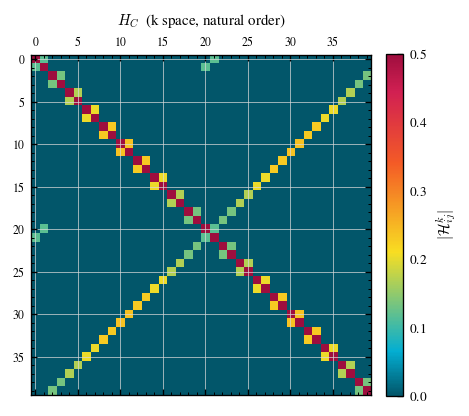

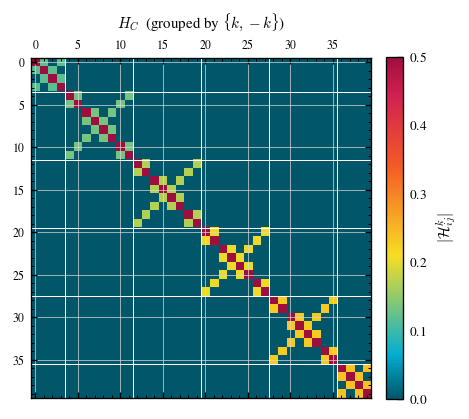

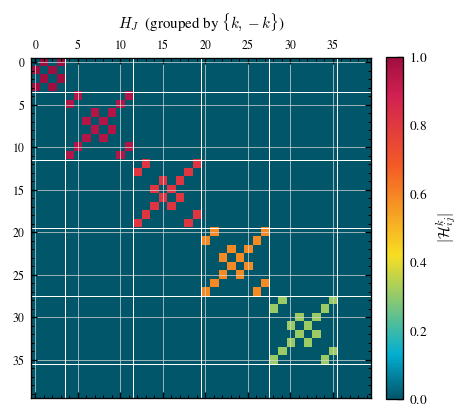

In [6]:
# --- visualise the permutation-induced block-diagonal structure -------------
import matplotlib.pyplot as plt

block_edges = np.cumsum([size for _, size, _ in sector_blocks])[:-1]

for matrix, name, grouped in [
        (H_cap_k,           r"$H_C$  (k space, natural order)", False),
        (H_cap_sectored,    r"$H_C$  (grouped by $\{k,-k\}$)",   True),
        (H_joseph_sectored, r"$H_J$  (grouped by $\{k,-k\}$)",   True)]:
    image = plt.matshow(np.abs(matrix), cmap="thesis_cmap")
    ax = image.axes
    if grouped:
        for edge in block_edges:
            ax.axhline(edge - 0.5, color="w", lw=0.6)
            ax.axvline(edge - 0.5, color="w", lw=0.6)
    ax.set_title(name, pad=18, fontsize=9)
    ax.tick_params(labelsize=7)
    image.figure.colorbar(image, ax=ax, fraction=0.046, pad=0.04, label=r"$|\mathcal{H}^k_{ij}|$")
plt.show()

## Diagonalising each $H_C$ sector: sublattice split + two-mode squeeze

Target: for every $\{k,-k\}$ block of $H_C$, a canonical (paraunitary) transform that leaves it
diagonal. The proposed recipe — symmetric/antisymmetric sublattice combination, then a squeeze on
each $\{k,-k\}$ pair — **works, with two corrections** (verified numerically against
$\operatorname{eig}(\tau_3\mathcal H)$ in the next cell):

1. **The sublattice combination must carry the Bloch phase.** $\alpha_k=(b_{kA}+b_{kB})/\sqrt2$
   diagonalises $\tilde A(k)$ only where $\delta_{C,k}$ is real, i.e. at the TRIMs. For generic $k$
   the plain combination leaves an $\alpha_k$–$\beta_k$ number-conserving coupling of
   $\tfrac12 g_{c2}\lvert\sin k\rvert$. The fix is the eigenbasis of $\tilde A(k)$,

   $$\alpha_k=\tfrac1{\sqrt2}\big(e^{-i\phi_k/2}b_{kA}+e^{+i\phi_k/2}b_{kB}\big),\quad
     \beta_k=\tfrac1{\sqrt2}\big(e^{-i\phi_k/2}b_{kA}-e^{+i\phi_k/2}b_{kB}\big),\quad
     \phi_k=\arg\big(g_{c1}+g_{c2}e^{-ik}\big),$$

   which reduces to $(b_{kA}\pm b_{kB})/\sqrt2$ exactly at $k=0,\pi$.

2. **Squeeze parameter.** After the rotation each $\{k,-k\}$ pair is
   $\omega_\pm(\text{n}_k+\text{n}_{-k})+\lambda_\pm(\gamma_k^\dagger\gamma_{-k}^\dagger+\text{h.c.})$
   with $\omega_\pm=\tfrac12(1\pm|\delta_{C,k}|)$, $\lambda_\pm=\mp\tfrac12|\delta_{C,k}|$. The
   two-mode squeeze ($S\gamma_k S^\dagger=\cosh z\,\gamma_k+\sinh z\,\gamma_{-k}^\dagger$) that
   kills the pairing has

   $$z_{k,\alpha}=\tfrac14\ln\!\big(1+2|\delta_{C,k}|\big),\qquad
     z_{k,\beta} =\tfrac14\ln\!\big(1-2|\delta_{C,k}|\big),$$

   i.e. $2|\delta_{C,k}|$ inside the log, not $|\delta_{C,k}|$. The stated bound
   $g_{c1}+g_{c2}<\tfrac12$ is precisely what keeps $1-2|\delta_{C,k}|>0$ — it only bites with the
   factor 2. Resulting bands:

   $$\omega_{k,\alpha}=\tfrac12\sqrt{1+2|\delta_{C,k}|},\qquad
     \omega_{k,\beta}=\tfrac12\sqrt{1-2|\delta_{C,k}|}.$$

The **same** transform applied to $H_J$ does *not* diagonalise it (the Josephson Bloch phase
$\arg(g_{J1}+g_{J2}e^{-ik})\neq\phi_k$), so $H_J$ keeps both an $\alpha$–$\beta$ number mixing and
pairing — reported in the last cell.


In [7]:
# --- sublattice split + squeeze, as paraunitary Nambu transforms ------------
# A sector Nambu block (from H_cap_sectored / H_joseph_sectored) is ordered
#   (b_kA, b_kB, b_-kA, b_-kB, b_kA^d, b_kB^d, b_-kA^d, b_-kB^d)   [4+4]  generic
#   (b_kA, b_kB, b_kA^d, b_kB^d)                                   [2+2]  TRIM

def nambu_metric(half_dim):
    """tau_3 = diag(+1,...,+1, -1,...,-1)  (half_dim of each sign)."""
    return np.diag(np.concatenate([np.ones(half_dim), -np.ones(half_dim)]))


def paraunitary_defect(transform, half_dim):
    """0  <=>  transform is paraunitary (transform^dag tau_3 transform = tau_3),
    i.e. a canonical bosonic Bogoliubov transform."""
    tau3 = nambu_metric(half_dim)
    return np.abs(transform.conj().T @ tau3 @ transform - tau3).max()


def bogoliubov_frequencies(nambu_hamiltonian, half_dim):
    """physical mode frequencies = positive eigenvalues of tau_3 @ nambu_hamiltonian."""
    eigenvalues = np.linalg.eigvals(nambu_metric(half_dim) @ nambu_hamiltonian).real
    return np.sort(eigenvalues[eigenvalues > 1e-9])


def passive_nambu_transform(mode_mixing):
    """new = mode_mixing @ old  (mode_mixing unitary)  ->  Nambu transform Psi = transform Psi'."""
    inverse = np.linalg.inv(mode_mixing)
    zeros = np.zeros_like(inverse)
    return np.block([[inverse, zeros], [zeros, inverse.conj()]])


def phased_sublattice_rotation(bloch_phase, half_dim):
    """rows = (alpha, beta); alpha_k = (e^{-i phase/2} b_kA + e^{+i phase/2} b_kB)/sqrt(2).
    phase(-k) = -phase(k)."""
    at_plus_k = np.array([[np.exp(-1j * bloch_phase / 2),  np.exp(1j * bloch_phase / 2)],
                          [np.exp(-1j * bloch_phase / 2), -np.exp(1j * bloch_phase / 2)]]) / np.sqrt(2)
    if half_dim == 2:
        return at_plus_k
    at_minus_k = np.array([[np.exp(1j * bloch_phase / 2),  np.exp(-1j * bloch_phase / 2)],
                           [np.exp(1j * bloch_phase / 2), -np.exp(-1j * bloch_phase / 2)]]) / np.sqrt(2)
    zeros = np.zeros((2, 2))
    return np.block([[at_plus_k, zeros], [zeros, at_minus_k]])


def squeeze_nambu_transform(half_dim, squeeze_specs):
    """squeeze_specs = [(mode_i, mode_j, squeeze), ...];
    gamma_i -> cosh(squeeze) gamma_i + sinh(squeeze) gamma_j^dag.
    mode_i == mode_j  => single-mode squeeze (TRIM)."""
    diag = np.eye(half_dim, dtype=complex)
    anti_diag = np.zeros((half_dim, half_dim), dtype=complex)
    for mode_i, mode_j, squeeze in squeeze_specs:
        diag[mode_i, mode_i] = diag[mode_j, mode_j] = np.cosh(squeeze)
        anti_diag[mode_i, mode_j] = anti_diag[mode_j, mode_i] = np.sinh(squeeze)
    return np.block([[diag, anti_diag], [anti_diag.conj(), diag.conj()]])


def diagonalize_cap_sector(H_cap_sector, k, g_cap_intra, g_cap_inter):
    """Return (transform, H_cap_diag) with transform paraunitary and H_cap_diag numerically diagonal."""
    half_dim = H_cap_sector.shape[0] // 2
    bloch_cap = g_cap_intra + g_cap_inter * np.exp(-1j * k)
    bloch_magnitude, bloch_phase = abs(bloch_cap), np.angle(bloch_cap)
    squeeze_alpha = 0.25 * np.log(1 + 2 * bloch_magnitude)
    squeeze_beta  = 0.25 * np.log(1 - 2 * bloch_magnitude)

    rotation = passive_nambu_transform(phased_sublattice_rotation(bloch_phase, half_dim))
    if half_dim == 2:                      # TRIM: single-mode squeeze on alpha (0) and beta (1)
        squeeze = squeeze_nambu_transform(2, [(0, 0, squeeze_alpha), (1, 1, squeeze_beta)])
    else:                                  # generic: two-mode on (alpha_k, alpha_-k), (beta_k, beta_-k)
        squeeze = squeeze_nambu_transform(4, [(0, 2, squeeze_alpha), (1, 3, squeeze_beta)])

    transform = rotation @ squeeze
    return transform, transform.conj().T @ H_cap_sector @ transform

In [8]:
# --- run it on every sector: diagonalize H_cap, then push H_joseph through the same transform
g_cap_intra = 0.25 * Omega_C * (1 + Chi_C)
g_cap_inter = 0.25 * Omega_C * (1 - Chi_C)
assert g_cap_intra + g_cap_inter < 0.5, "need g_cap_intra + g_cap_inter < 1/2 for the beta squeeze to exist"

print(f"{'k':>9}  {'type':<5} {'H_cap num-offdiag':>17} {'H_cap pairing':>13} "
      f"{'freqs vs eig(t3 H)':>20}   |  H_joseph after same transform")
for start, size, k_label in sector_blocks:
    H_cap_sector    = H_cap_sectored[start:start + size, start:start + size]
    H_joseph_sector = H_joseph_sectored[start:start + size, start:start + size]
    half_dim = size // 2

    transform, H_cap_diag = diagonalize_cap_sector(H_cap_sector, k_label, g_cap_intra, g_cap_inter)
    H_joseph_qp = transform.conj().T @ H_joseph_sector @ transform

    cap_normal_diag, cap_pairing_diag = H_cap_diag[:half_dim, :half_dim], H_cap_diag[:half_dim, half_dim:]
    num_off_diagonal = np.abs(cap_normal_diag - np.diag(np.diag(cap_normal_diag))).max()
    pairing_leftover = np.abs(cap_pairing_diag).max()
    freqs_from_diag = np.sort(np.diag(cap_normal_diag).real)
    freqs_from_tau3 = bogoliubov_frequencies(H_cap_sector, half_dim)
    bloch_magnitude = abs(g_cap_intra + g_cap_inter * np.exp(-1j * k_label))
    freqs_analytic = np.sort(np.r_[
        [0.5 * np.sqrt(1 + 2 * bloch_magnitude)] * (half_dim // 2 or 1),
        [0.5 * np.sqrt(1 - 2 * bloch_magnitude)] * (half_dim // 2 or 1)][:half_dim])

    joseph_normal_qp, joseph_pairing_qp = H_joseph_qp[:half_dim, :half_dim], H_joseph_qp[:half_dim, half_dim:]
    print(f"{k_label:+9.4f}  {'TRIM' if np.isclose(np.sin(k_label), 0) else 'gen':<5} "
          f"{num_off_diagonal:17.2e} {pairing_leftover:13.2e} "
          f"{'ok' if np.allclose(freqs_from_diag, freqs_from_tau3, atol=1e-9) else 'MISMATCH':>20}   |  "
          f"num-offdiag {np.abs(joseph_normal_qp - np.diag(np.diag(joseph_normal_qp))).max():.3f}  "
          f"pairing {np.abs(joseph_pairing_qp).max():.3f}")
    assert paraunitary_defect(transform, half_dim) < 1e-9
    assert (np.allclose(freqs_from_diag, freqs_from_tau3, atol=1e-9)
            and np.allclose(freqs_from_diag, freqs_analytic, atol=1e-9))

print("\nH_cap: every sector diagonal; bands = 1/2 sqrt(1 +/- 2|delta_C_k|), matches eig(tau_3 H).")
print("H_joseph: same transform leaves number-off-diagonal + pairing (different Bloch phase) -> not diagonal.")

        k  type  H_cap num-offdiag H_cap pairing   freqs vs eig(t3 H)   |  H_joseph after same transform
  -3.1416  TRIM           7.57e-18      1.37e-16                   ok   |  num-offdiag 0.000  pairing 1.214
  -2.5133  gen            1.04e-16      1.65e-17                   ok   |  num-offdiag 0.476  pairing 0.989
  -1.8850  gen            2.30e-16      3.81e-17                   ok   |  num-offdiag 0.571  pairing 0.594
  -1.2566  gen            6.63e-17      4.95e-17                   ok   |  num-offdiag 0.419  pairing 0.419
  -0.6283  gen            4.80e-17      1.53e-16                   ok   |  num-offdiag 0.194  pairing 0.194
  +0.0000  TRIM           3.47e-18      6.94e-17                   ok   |  num-offdiag 0.000  pairing 0.000

H_cap: every sector diagonal; bands = 1/2 sqrt(1 +/- 2|delta_C_k|), matches eig(tau_3 H).
H_joseph: same transform leaves number-off-diagonal + pairing (different Bloch phase) -> not diagonal.


In [9]:
# --- print the diagonalised H_cap sectors ----------------------------------
# Physical convention: bare transmon at frequency 1, i.e. multiply the
# 1/2 Psi^dag H Psi blocks by _nambu_prefactor = 2 (same as ssh_chain_sq).
np.set_printoptions(linewidth=160, precision=4, suppress=True)

sectors_to_show = [sector_blocks[len(sector_blocks) // 2], sector_blocks[0]]   # one TRIM, one generic
for start, size, k_label in sectors_to_show:
    half_dim = size // 2
    H_cap_sector = H_cap_sectored[start:start + size, start:start + size]
    _, H_cap_diag = diagonalize_cap_sector(H_cap_sector, k_label, g_cap_intra, g_cap_inter)
    tag = "TRIM" if np.isclose(np.sin(k_label), 0) else "generic"
    print(f"k = {k_label:+.4f}  ({tag})   2 * H_cap^diag  "
          f"(Nambu, ordered alpha_k, beta_k[, alpha_-k, beta_-k], then daggers):")
    print(np.real_if_close(2 * H_cap_diag, tol=1e6))
    print()

k = -1.2566  (generic)   2 * H_cap^diag  (Nambu, ordered alpha_k, beta_k[, alpha_-k, beta_-k], then daggers):
[[ 1.3482 -0.     -0.      0.     -0.     -0.     -0.      0.    ]
 [ 0.      0.427   0.     -0.      0.      0.     -0.      0.    ]
 [-0.      0.      1.3482 -0.     -0.      0.     -0.     -0.    ]
 [ 0.     -0.      0.      0.427  -0.      0.      0.      0.    ]
 [-0.     -0.     -0.      0.      1.3482 -0.     -0.      0.    ]
 [ 0.      0.     -0.      0.      0.      0.427   0.     -0.    ]
 [-0.      0.     -0.     -0.     -0.      0.      1.3482 -0.    ]
 [-0.      0.      0.      0.      0.     -0.      0.      0.427 ]]

k = -3.1416  (TRIM)   2 * H_cap^diag  (Nambu, ordered alpha_k, beta_k[, alpha_-k, beta_-k], then daggers):
[[ 1.2145 -0.     -0.      0.    ]
 [ 0.      0.7246  0.      0.    ]
 [-0.      0.      1.2145  0.    ]
 [ 0.      0.      0.      0.7246]]



max |sort(ssh)  -  sort(analytic at discrete k)|  = 8.881784197001252e-16
max |sort(ssh)  -  sort(squeeze-diag bands)|      = 1.1102230246251565e-15


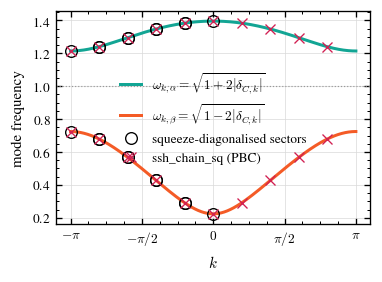

In [10]:
# --- the two bands: analytic  vs  squeeze-diagonalisation  vs  ssh_chain_sq --
from ssh_chain_sq import PHOTONICChain

reference_chain = PHOTONICChain(N=num_cells, Omega_C=Omega_C, Chi_C=Chi_C, omega_r=1.0, gamma=0.0,
                                fock_photon=2, Omega_J=Omega_J, Chi_J=Chi_J, kerr=0.0, PBC=True)
freqs_ssh_chain = np.sort(
    (reference_chain._nambu_prefactor() * np.diag(reference_chain.H_C)[:2 * num_cells]).real)

k_dense = np.linspace(-np.pi, np.pi, 601)
bloch_magnitude_dense = np.abs(g_cap_intra + g_cap_inter * np.exp(-1j * k_dense))
freq_alpha = np.sqrt(1 + 2 * bloch_magnitude_dense)   # sqrt(1 + |delta|), gauge's delta = 2(g_cap_intra + g_cap_inter e^-ik)
freq_beta  = np.sqrt(1 - 2 * bloch_magnitude_dense)

k_discrete = k_grid(num_cells)
bloch_magnitude_discrete = np.abs(g_cap_intra + g_cap_inter * np.exp(-1j * k_discrete))
freq_alpha_discrete = np.sqrt(1 + 2 * bloch_magnitude_discrete)
freq_beta_discrete  = np.sqrt(1 - 2 * bloch_magnitude_discrete)

# bands straight off the squeeze-diagonalised sectors (factor 2 -> physical)
k_from_sectors, freqs_from_sectors = [], []
for start, size, k_label in sector_blocks:
    half_dim = size // 2
    _, H_cap_diag = diagonalize_cap_sector(
        H_cap_sectored[start:start + size, start:start + size], k_label, g_cap_intra, g_cap_inter)
    for freq in 2 * np.diag(H_cap_diag[:half_dim, :half_dim]).real:
        k_from_sectors.append(k_label); freqs_from_sectors.append(freq)

print("max |sort(ssh)  -  sort(analytic at discrete k)|  =",
      np.abs(freqs_ssh_chain - np.sort(np.r_[freq_alpha_discrete, freq_beta_discrete])).max())
print("max |sort(ssh)  -  sort(squeeze-diag bands)|      =",
      np.abs(freqs_ssh_chain - np.sort(freqs_from_sectors)).max())

fig, ax = plt.subplots(figsize=ts.figsize(1))
ax.plot(k_dense, freq_alpha, color=ts.COLORS["teal"],
        label=r"$\omega_{k,\alpha}=\sqrt{1+2|\delta_{C,k}|}$")
ax.plot(k_dense, freq_beta, color=ts.COLORS["orange"],
        label=r"$\omega_{k,\beta}=\sqrt{1-2|\delta_{C,k}|}$")
ax.plot(k_from_sectors, freqs_from_sectors, "o", mfc="none", mec="k", ms=7, lw=0,
        label="squeeze-diagonalised sectors")
ax.plot(np.r_[k_discrete, k_discrete], np.r_[freq_alpha_discrete, freq_beta_discrete],
        "x", color=ts.COLORS["red"], ms=6, label="ssh_chain_sq (PBC)")
ax.axhline(1.0, color="0.6", lw=0.7, ls=":")
ax.set_xlabel(r"$k$"); ax.set_ylabel(r"mode frequency")
ax.set_xticks([-np.pi, -np.pi/2, 0, np.pi/2, np.pi])
ax.set_xticklabels([r"$-\pi$", r"$-\pi/2$", r"$0$", r"$\pi/2$", r"$\pi$"])
ax.legend()
ts.finalize(ax)
plt.show()

## Zak phase of the lower band (Wilson loop)

$$\gamma=-\operatorname{Im}\ln\!\Big[\textstyle\prod_j\langle u(k_j)|u(k_{j+1})\rangle\Big],$$

single-log-of-the-product — gauge invariant (each $|u_k\rangle$ enters once as bra, once as ket).
*(The image's second line should read $-\sum_j$, not $-\prod_j$.)*

**Orbital gauge.** The loop runs over the cell-periodic part $|u_k\rangle=e^{-ik\hat r}|\psi_k\rangle$,
$\hat r=\operatorname{diag}(s_A,s_B)$ the sublattice positions in the cell. The eigenvectors of
$h(k)=\big(\begin{smallmatrix}0&\delta_{C,k}\\\delta_{C,k}^\ast&0\end{smallmatrix}\big)$,
$\delta_{C,k}=g_{c1}+g_{c2}e^{-ik}$, are the $|\psi_k\rangle$ (convention where the cell phase sits on
the inter-cell bond); the BZ-boundary overlap then carries the extra factor
$e^{-i2\pi s_\sigma}$ (same construction as `class_subjects/topology/zak_phase.ipynb`). For the
chiral SSH band $|\psi_{k,A}|^2=|\psi_{k,B}|^2=\tfrac12$, so the orbital term contributes
$-\pi(s_A+s_B)$: the symmetric cell $s=(-\tfrac14,\tfrac14)$ and the periodic gauge $s=(0,0)$ both
give $\gamma\in\{0,\pi\}$; $s=(0,\tfrac12)$ shifts it to $\pm\tfrac\pi2$.

Chiral symmetry: $\gamma=0$ for $g_{c1}>g_{c2}$ ($\chi_C>0$), $\gamma=\pi$ for $g_{c1}<g_{c2}$
($\chi_C<0$), gap closing at $\chi_C=0$. The last cell repeats the loop with the **Bogoliubov
eigenvectors of $H_C$** (pairing included) and gets the same $\gamma$ — the squeeze does not touch
the Zak phase.


Omega_C=0.95  Chi_C=0.5  ->  g_cap_intra=0.3562 > g_cap_inter=0.1187

  s=(+0.00,+0.00)   gamma_lower = +0.000000  =  +0.0000 pi
  s=(-0.25,+0.25)   gamma_lower = -0.000000  =  -0.0000 pi
  s=(+0.00,+0.50)   gamma_lower = +1.570796  =  +0.5000 pi

  grid-independent (s = -1/4, 1/4): ['+0.000', '+0.000', '+0.000', '-0.000']


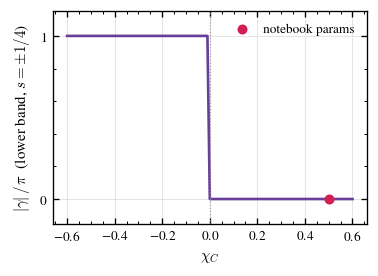

In [11]:
# --- Zak phase of the lower band, Wilson loop (orbital gauge) ---------------
# same construction as class_subjects/topology/zak_phase.ipynb

def compute_zak_phase(bloch_spinor_at, num_k_points, sublattice_positions=(-0.25, 0.25)):
    """gamma_Zak = -Im ln [ prod_j <u_j|u_{j+1}> ], u_k = e^{-i k r} psi_k.
    bloch_spinor_at(k) returns psi_k: a 2-vector (bare band) or a 4-vector Bogoliubov
    spinor (u_A, u_B, v_A, v_B); the hole block picks up the opposite orbital phase."""
    momenta = np.linspace(0.0, 2 * np.pi, num_k_points, endpoint=False)
    spinors = [bloch_spinor_at(k) for k in momenta]
    positions = np.asarray(sublattice_positions)
    bz_boundary_phase = (np.exp(-1j * 2 * np.pi * positions) if len(spinors[0]) == 2
                         else np.exp(-1j * 2 * np.pi * np.r_[positions, -positions]))
    wilson_product = np.prod([np.vdot(spinors[j], spinors[j + 1]) for j in range(num_k_points - 1)])
    wilson_product *= np.vdot(spinors[-1], bz_boundary_phase * spinors[0])   # BZ boundary + orbital factor
    return -np.angle(wilson_product)


def ssh_lower_band_spinor(k, g_cap_intra, g_cap_inter):
    bloch_cap = g_cap_intra + g_cap_inter * np.exp(-1j * k)
    _, eigenvectors = np.linalg.eigh(np.array([[0.0 + 0j, bloch_cap], [np.conj(bloch_cap), 0.0]]))
    return eigenvectors[:, 0]


lower_band_spinor = lambda k: ssh_lower_band_spinor(k, g_cap_intra, g_cap_inter)
print(f"Omega_C={Omega_C}  Chi_C={Chi_C}  ->  g_cap_intra={g_cap_intra:.4f} > g_cap_inter={g_cap_inter:.4f}\n")
for positions in [(0.0, 0.0), (-0.25, 0.25), (0.0, 0.5)]:
    zak_phase = compute_zak_phase(lower_band_spinor, 400, positions)
    print(f"  s=({positions[0]:+.2f},{positions[1]:+.2f})   "
          f"gamma_lower = {zak_phase:+.6f}  =  {zak_phase/np.pi:+.4f} pi")
print("\n  grid-independent (s = -1/4, 1/4):",
      [f"{compute_zak_phase(lower_band_spinor, num_k_points, (-0.25, 0.25)) / np.pi:+.3f}"
       for num_k_points in (num_cells, 13, 50, 400)])

# sweep Chi_C : topological transition at Chi_C = 0
chi_values = np.linspace(-0.6, 0.6, 121)
zak_vs_chi = np.array([
    compute_zak_phase(lambda k: ssh_lower_band_spinor(
        k, 0.25 * Omega_C * (1 + chi), 0.25 * Omega_C * (1 - chi)), 200)
    for chi in chi_values])

fig, ax = plt.subplots(figsize=ts.figsize(1))
ax.plot(chi_values, np.abs(zak_vs_chi) / np.pi, color=ts.COLORS["purple"], lw=1.6)
ax.axvline(0.0, color="0.6", lw=0.7, ls=":")
ax.scatter([Chi_C], [np.abs(compute_zak_phase(lower_band_spinor, 400, (-0.25, 0.25))) / np.pi],
           color=ts.COLORS["red"], zorder=5, label="notebook params")
ax.set_xlabel(r"$\chi_C$")
ax.set_ylabel(r"$|\gamma|\,/\,\pi$  (lower band, $s = \pm 1/4$)")
ax.set_yticks([0, 1]); ax.set_ylim(-0.15, 1.15); ax.legend()
ts.finalize(ax)
plt.show()

### Do the pairing terms conserve the Zak phase?

Run the **same** Wilson loop on the Bogoliubov eigenvectors that diagonalise $H_C$ — the columns of
the paraunitary $T$, i.e. the positive-$\beta$-band spinor of the single-$k$ BdG Bloch Hamiltonian

$$\mathcal H_{\rm BdG}(k)=\begin{pmatrix}h(k)&\Delta(k)\\ \Delta(k)&h(k)\end{pmatrix},\qquad
  h(k)=\begin{pmatrix}1&\delta_{C,k}\\ \delta_{C,k}^\ast&1\end{pmatrix},\qquad
  \Delta(k)=I-h(k),$$

acting on $\Psi_k=(b_{kA},b_{kB},b_{-kA}^\dagger,b_{-kB}^\dagger)$, normalised $\Phi^\dagger\tau_3\Phi=+1$.

Because $\Delta(k)=I-h(k)$ **shares $h(k)$'s eigenbasis**, the Bogoliubov rotation is (phased
sublattice rotation) $\times$ (real squeeze on the $\{k,-k\}$ pair). So the particle block
$(u_{kA},u_{kB})$ is exactly the SSH eigenvector and the hole block $(v_{kA},v_{kB})$ points the
same way with a real, non-winding amplitude $\sinh z_{k,\beta}$. Chiral symmetry survives
($|u_{kA}|^2=|u_{kB}|^2$, $|v_{kA}|^2=|v_{kB}|^2$ at every $k$), so both the Berry connection and
the orbital term are identical to the bare band — $\gamma$ is unchanged.


In [12]:
# --- Wilson loop on the Bogoliubov (H_cap-diagonalising) eigenvectors ------
nambu_metric_4 = np.diag([1.0, 1.0, -1.0, -1.0])

def bdg_bloch_hamiltonian(k, g_cap_intra, g_cap_inter):
    bloch_cap = g_cap_intra + g_cap_inter * np.exp(-1j * k)
    normal_block = np.array([[1.0 + 0j, bloch_cap], [np.conj(bloch_cap), 1.0]])
    return np.block([[normal_block, np.eye(2) - normal_block],
                     [np.eye(2) - normal_block, normal_block]])


def beta_bogoliubov_spinor(k, g_cap_intra, g_cap_inter):
    """positive beta-band Bogoliubov eigenvector, normalised Phi^dag tau_3 Phi = +1."""
    eigenvalues, eigenvectors = np.linalg.eig(
        nambu_metric_4 @ bdg_bloch_hamiltonian(k, g_cap_intra, g_cap_inter))
    beta_freq = np.sqrt(1 - 2 * abs(g_cap_intra + g_cap_inter * np.exp(-1j * k)))
    beta_index = np.argmin(np.abs(eigenvalues - beta_freq))
    spinor = eigenvectors[:, beta_index]
    return spinor / np.sqrt(abs(np.real(spinor.conj() @ nambu_metric_4 @ spinor)))


beta_spinor = lambda k: beta_bogoliubov_spinor(k, g_cap_intra, g_cap_inter)

print(f"{'s = (s_A, s_B)':>16} | {'bare SSH':>12} | {'BdG beta':>12} | {'|diff|':>9}")
for positions in [(0.0, 0.0), (-0.25, 0.25), (0.0, 0.5), (0.1, 0.4)]:
    zak_bare = compute_zak_phase(lower_band_spinor, 400, positions)
    zak_bdg  = compute_zak_phase(beta_spinor, 400, positions)
    print(f"  ({positions[0]:+.2f}, {positions[1]:+.2f})   | {zak_bare/np.pi:+8.4f} pi | "
          f"{zak_bdg/np.pi:+8.4f} pi | {abs(zak_bare - zak_bdg):9.1e}")

# topological side
g_cap_intra_topo, g_cap_inter_topo = 0.25 * Omega_C * (1 - 0.3), 0.25 * Omega_C * (1 + 0.3)
print(f"\ntopological check (g_cap_intra < g_cap_inter):  SSH = "
      f"{compute_zak_phase(lambda k: ssh_lower_band_spinor(k, g_cap_intra_topo, g_cap_inter_topo), 400, (-.25, .25))/np.pi:+.4f} pi   "
      f"BdG = {compute_zak_phase(lambda k: beta_bogoliubov_spinor(k, g_cap_intra_topo, g_cap_inter_topo), 400, (-.25, .25))/np.pi:+.4f} pi")

# explicit overlaps + chiral-symmetry weights along the loop
print("\n  k_j     <Phi_j|Phi_j+1>        |u_A|^2 |u_B|^2   |v_A|^2  |v_B|^2")
loop_momenta = np.linspace(0.0, 2 * np.pi, num_cells, endpoint=False)
spinors_along_loop = [beta_bogoliubov_spinor(k, g_cap_intra, g_cap_inter) for k in loop_momenta]
for j in range(num_cells):
    overlap = np.vdot(spinors_along_loop[j], spinors_along_loop[(j + 1) % num_cells])
    spinor = spinors_along_loop[j]
    print(f" {loop_momenta[j]:6.3f}  {overlap.real:+.4f}{overlap.imag:+.4f}j   "
          f"{abs(spinor[0])**2:.4f} {abs(spinor[1])**2:.4f}   "
          f"{abs(spinor[2])**2:.5f} {abs(spinor[3])**2:.5f}")

print("\n=> the squeeze/pairing leaves the Zak phase unchanged, in every orbital gauge.")

  s = (s_A, s_B) |     bare SSH |     BdG beta |    |diff|
  (+0.00, +0.00)   |  +0.0000 pi |  -0.0000 pi |   6.0e-16
  (-0.25, +0.25)   |  -0.0000 pi |  -0.0000 pi |   2.0e-13
  (+0.00, +0.50)   |  +0.5000 pi |  +0.5000 pi |   1.4e-13
  (+0.10, +0.40)   |  +0.5000 pi |  +0.5000 pi |   1.6e-15

topological check (g_cap_intra < g_cap_inter):  SSH = -1.0000 pi   BdG = -1.0000 pi

  k_j     <Phi_j|Phi_j+1>        |u_A|^2 |u_B|^2   |v_A|^2  |v_B|^2
  0.000  +2.0756+0.1592j   0.8370 0.8370   0.33697 0.33697
  0.628  -1.5545+0.3419j   0.7160 0.7160   0.21600 0.21600
  1.257  +1.2607-0.0377j   0.5961 0.5961   0.09614 0.09614
  1.885  +1.1141+0.0433j   0.5412 0.5412   0.04118 0.04118
  2.513  +1.0454+0.1378j   0.5189 0.5189   0.01895 0.01895
  3.142  +1.0454+0.1378j   0.5131 0.5131   0.01309 0.01309
  3.770  +1.1141+0.0433j   0.5189 0.5189   0.01895 0.01895
  4.398  +1.2607-0.0377j   0.5412 0.5412   0.04118 0.04118
  5.027  -1.5545+0.3419j   0.5961 0.5961   0.09614 0.09614
  5.655  +2.0756+0.1

In [13]:
# --- Zak phase vs Chi_C for the PAIRED (BdG) SSH chain --------------------
orbital_positions = (-0.25, 0.25)          # symmetric cell, class_subjects/topology convention
num_k_points = 400

chi_values = np.linspace(-0.6, 0.6, 240)   # even count -> skips the exact gap-closing point
def cap_couplings(chi):
    return 0.25 * Omega_C * (1 + chi), 0.25 * Omega_C * (1 - chi)

zak_bare_vs_chi   = np.array([compute_zak_phase(
    lambda k: ssh_lower_band_spinor(k, *cap_couplings(chi)), num_k_points, orbital_positions)
    for chi in chi_values])
zak_paired_vs_chi = np.array([compute_zak_phase(
    lambda k: beta_bogoliubov_spinor(k, *cap_couplings(chi)), num_k_points, orbital_positions)
    for chi in chi_values])

print("max | |gamma|_bare - |gamma|_paired |  over the sweep = "
      f"{np.abs(np.abs(zak_bare_vs_chi) - np.abs(zak_paired_vs_chi)).max():.2e}")
print(f"paired Zak phase:  {np.unique(np.round(np.abs(zak_paired_vs_chi) / np.pi))} * pi   "
      f"(0 for Chi_C > 0, pi for Chi_C < 0)")

max | |gamma|_bare - |gamma|_paired |  over the sweep = 8.34e-13
paired Zak phase:  [0. 1.] * pi   (0 for Chi_C > 0, pi for Chi_C < 0)


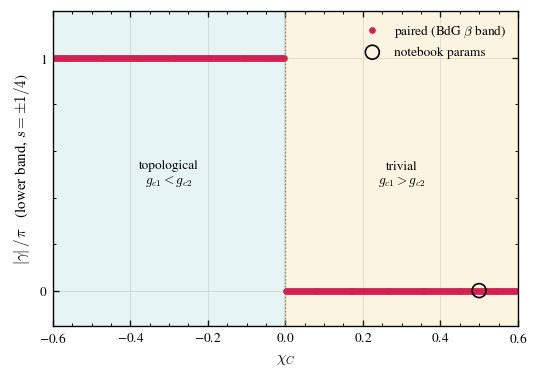

In [14]:
fig, ax = plt.subplots(figsize=ts.figsize(1.5))
ax.axvspan(-0.6, 0.0, color=ts.COLORS["teal"], alpha=0.10)
ax.axvspan(0.0, 0.6, color=ts.COLORS["gold"], alpha=0.12)
ax.axvline(0.0, color="0.5", lw=0.8, ls=":")
ax.text(-0.3, 0.5, "topological\n$g_{c1}<g_{c2}$", ha="center", va="center", fontsize=8)
ax.text(0.3, 0.5, "trivial\n$g_{c1}>g_{c2}$", ha="center", va="center", fontsize=8)

ax.plot(chi_values, np.abs(zak_paired_vs_chi) / np.pi, color=ts.COLORS["red"], lw=0, marker="o", ms=3.2,
        label=r"paired (BdG $\beta$ band)")
ax.scatter([Chi_C],
           [np.abs(compute_zak_phase(lambda k: beta_bogoliubov_spinor(k, g_cap_intra, g_cap_inter),
                                     num_k_points, orbital_positions)) / np.pi],
           s=70, facecolor="none", edgecolor="k", zorder=6, label="notebook params")

ax.set_xlabel(r"$\chi_C$")
ax.set_ylabel(r"$|\gamma|\,/\,\pi$   (lower band, $s=\pm 1/4$)")
ax.set_yticks([0, 1]); ax.set_ylim(-0.15, 1.2); ax.set_xlim(-0.6, 0.6)
ax.legend(loc="upper right")
ts.finalize(ax)
plt.show()

## Schrieffer–Wolff correction in this gauge (single-excitation subspace)

Add the readout resonator, $H = \omega_r a^\dagger a + H_C - \gamma\,(a+a^\dagger)\,H_J$, exactly the
`PHOTONICChain` model. `schrieffer_wolff_correction` in `ssh_chain_sq` builds the 2nd-order
correction from the pairing blocks $B_J,C_J$ via the $\pm2$-excitation virtual sectors:

$$H_{\rm SW}[X,X']=\tfrac12\sum_{n_{\rm mid},\,r} s_{0,n_{\rm mid}}s_{n_{\rm mid},0}\,
  \langle X|H_J|r\rangle\langle r|H_J|X'\rangle
  \Big[\tfrac{1}{E_X-E_r-n_{\rm mid}\omega_r}+\tfrac{1}{E_{X'}-E_r-n_{\rm mid}\omega_r}\Big],
  \quad s=\gamma(a+a^\dagger).$$

Same procedure here, per $\{k,-k\}$ sector, with $X$ the **single quasiparticle** $\gamma_i^\dagger|0\rangle$
($i\in\{\alpha_k,\beta_k,\alpha_{-k},\beta_{-k}\}$, $E_X=\omega_{k,i}$), $r$ the 3-QP virtual states,
and $H_J$ the Josephson operator in the diagonalising gauge, $\tilde H_J = T^\dagger\mathcal H_J T$
(number block $\tilde{\mathcal A}_J$, pairing block $\tilde{\mathcal B}_J$).

Crystal momentum is exactly conserved (the resonator carries none), so the effective quadratic
correction splits cleanly:

- **$k$-preserving** — the number-conserving piece $\delta\mathcal A(k)_{ij}\,\gamma_i^\dagger\gamma_j$
  (band renormalisation + $\alpha_k\!\leftrightarrow\!\beta_k$ interband mixing at fixed $k$);
- **$k$-changing** — the anomalous piece $\delta\mathcal B(k)_{ij}\,\gamma_i^\dagger\gamma_{-i}^\dagger$,
  a resonator-**induced pairing** connecting the $+k$ and $-k$ single-particle sectors.

`ssh_chain_sq` eliminates only $\tilde{\mathcal B}_J$ and keeps $\tilde{\mathcal A}_J$ in $H$; to reach
the interband resonance we eliminate the whole coupling (identical denominators / time-orderings).

**Resonance.** The interband gap is $\omega_{k,\alpha}-\omega_{k,\beta}=\sqrt{1+2|\delta_{C,k}|}-\sqrt{1-2|\delta_{C,k}|}$,
which at $k=0$ equals $\sqrt{1+2(g_{c1}+g_{c2})}-\sqrt{1-2(g_{c1}+g_{c2})}\approx 2(g_{c1}+g_{c2})$.
Take $\omega_r = 2(g_{c1}+g_{c2})$. Solving $\sqrt{1+2x}-\sqrt{1-2x}=\omega_r$ gives
$x=|\delta_{C,k^\star}|=\tfrac{\omega_r}{2}\sqrt{1-\omega_r^2/4}$, then
$\cos k^\star=(x^2-g_{c1}^2-g_{c2}^2)/(2g_{c1}g_{c2})$ — the exact momentum where $\omega_r$ hits the
interband transition and the SW denominator vanishes.


In [15]:
# --- SW correction, single-excitation subspace, per {k,-k} sector -----------
def bosonic_annihilation_ops(fock_cutoffs):
    """annihilation operators for a list of bosonic modes with the given Fock dimensions."""
    operators = []
    for target_mode, target_cutoff in enumerate(fock_cutoffs):
        single_mode = np.diag(np.sqrt(np.arange(1, target_cutoff)), 1)
        full = np.array([[1.0]])
        for mode, cutoff in enumerate(fock_cutoffs):
            full = np.kron(full, single_mode if mode == target_mode else np.eye(cutoff))
        operators.append(full.astype(complex))
    return operators


def sector_nambu_at_k(k, g_cap_intra, g_cap_inter, Omega_J, Chi_J):
    """8x8 capacitive + Josephson Nambu blocks for the {k,-k} sector,
    basis (b_kA, b_kB, b_-kA, b_-kB, + daggers), honest 1/2 Psi^dag H Psi convention."""
    g_joseph_intra, g_joseph_inter = Omega_J * (1 + Chi_J), -Omega_J * (1 - Chi_J)
    g_joseph_sum = g_joseph_intra + g_joseph_inter
    bloch_cap    = g_cap_intra    + g_cap_inter    * np.exp(-1j * k)
    bloch_joseph = g_joseph_intra + g_joseph_inter * np.exp(-1j * k)
    zero_2x2 = np.zeros((2, 2))

    def sector_from_bloch(on_site, bloch_off_diagonal):
        at_plus_k  = np.array([[on_site, bloch_off_diagonal],
                               [np.conj(bloch_off_diagonal), on_site]], dtype=complex)
        at_minus_k = np.array([[on_site, np.conj(bloch_off_diagonal)],
                               [bloch_off_diagonal, on_site]], dtype=complex)
        return np.block([[at_plus_k, zero_2x2], [zero_2x2, at_minus_k]])

    cap_normal  = 0.5 * sector_from_bloch(1.0, bloch_cap)
    cap_pairing = np.zeros((4, 4), dtype=complex)
    cap_pairing[0:2, 2:4] = -0.5 * np.array([[0, bloch_cap], [np.conj(bloch_cap), 0]])
    cap_pairing[2:4, 0:2] = -0.5 * np.array([[0, np.conj(bloch_cap)], [bloch_cap, 0]])

    joseph_normal = 0.5 * sector_from_bloch(g_joseph_sum, -bloch_joseph)
    joseph_pairing = np.zeros((4, 4), dtype=complex)
    joseph_pairing[0:2, 2:4] = (-0.5 * np.array([[0, bloch_joseph], [np.conj(bloch_joseph), 0]])
                                - 0.5 * g_joseph_sum * np.eye(2))
    joseph_pairing[2:4, 0:2] = (-0.5 * np.array([[0, np.conj(bloch_joseph)], [bloch_joseph, 0]])
                                - 0.5 * g_joseph_sum * np.eye(2))
    return (np.block([[cap_normal, cap_pairing], [cap_pairing.conj(), cap_normal.conj()]]),
            np.block([[joseph_normal, joseph_pairing], [joseph_pairing.conj(), joseph_normal.conj()]]))


def sw_correction(k, g_cap_intra, g_cap_inter, Omega_J, Chi_J, omega_r, gamma,
                  coupling_mode="full", qp_fock_cutoff=3, photon_fock_cutoff=2, denom_floor=1e-9):
    """2nd-order SW elimination of the resonator, single-excitation subspace, {k,-k} sector.
    Returns (qp_freqs, sw_number_correction, sw_pairing_correction): QP frequencies, and the
    k-preserving (number-conserving) and k-changing (induced pairing) effective corrections,
    4x4 over (alpha_k, beta_k, alpha_-k, beta_-k).
    coupling_mode='full' eliminates the whole coupling; 'pairing' matches ssh_chain_sq (B_J only)."""
    H_cap, H_joseph = sector_nambu_at_k(k, g_cap_intra, g_cap_inter, Omega_J, Chi_J)
    transform, H_cap_diag = diagonalize_cap_sector(H_cap, k, g_cap_intra, g_cap_inter)
    H_joseph_qp = transform.conj().T @ H_joseph @ transform
    num_qp_modes = 4
    qp_freqs        = 2.0 * np.diag(H_cap_diag[:num_qp_modes, :num_qp_modes]).real
    joseph_number_qp  = 2.0 * H_joseph_qp[:num_qp_modes, :num_qp_modes]
    joseph_pairing_qp = 2.0 * H_joseph_qp[:num_qp_modes, num_qp_modes:]

    fock_cutoffs = [photon_fock_cutoff] + [qp_fock_cutoff] * num_qp_modes
    photon_annihilation, *qp_annihilation = bosonic_annihilation_ops(fock_cutoffs)
    photon_number_op = photon_annihilation.conj().T @ photon_annihilation
    H_unperturbed = omega_r * photon_number_op + sum(
        qp_freqs[mode] * (qp_annihilation[mode].conj().T @ qp_annihilation[mode])
        for mode in range(num_qp_modes))

    matter_coupling = np.zeros_like(H_unperturbed)
    for mode_i in range(num_qp_modes):
        for mode_j in range(num_qp_modes):
            if coupling_mode == "full":
                matter_coupling += joseph_number_qp[mode_i, mode_j] * (
                    qp_annihilation[mode_i].conj().T @ qp_annihilation[mode_j])
            matter_coupling += joseph_pairing_qp[mode_i, mode_j] * (
                qp_annihilation[mode_i].conj().T @ qp_annihilation[mode_j].conj().T)
            matter_coupling += np.conj(joseph_pairing_qp[mode_i, mode_j]) * (
                qp_annihilation[mode_j] @ qp_annihilation[mode_i])
    coupling_operator = -gamma * ((photon_annihilation + photon_annihilation.conj().T) @ matter_coupling)

    photon_occupation = np.round(np.real(np.diag(photon_number_op))).astype(int)
    in_P, in_Q = (photon_occupation == 0), (photon_occupation != 0)
    energies = np.real(np.diag(H_unperturbed))
    energies_P, energies_Q = energies[in_P], energies[in_Q]
    coupling_PQ = coupling_operator[np.ix_(in_P, in_Q)]
    denominator = energies_P[:, None] - energies_Q[None, :]
    generator = np.where(np.abs(denominator) > denom_floor,
                         coupling_PQ / np.where(np.abs(denominator) > denom_floor, denominator, 1.0), 0.0)
    H_sw = 0.5 * (generator @ coupling_PQ.conj().T + coupling_PQ @ generator.conj().T)   # both time-orderings

    P_states = [state for state, keep in zip(list(np.ndindex(*fock_cutoffs)), in_P) if keep]
    vacuum_index = next(i for i, state in enumerate(P_states) if sum(state[1:]) == 0)
    one_qp_index = {state[1:].index(1): i for i, state in enumerate(P_states) if sum(state[1:]) == 1}
    two_qp_index = {tuple(sorted(m for m in range(num_qp_modes) for _ in range(state[1 + m]))): i
                    for i, state in enumerate(P_states) if sum(state[1:]) == 2}
    sw_number_correction = np.array(
        [[H_sw[one_qp_index[i], one_qp_index[j]] for j in range(num_qp_modes)]
         for i in range(num_qp_modes)])
    sw_pairing_correction = np.array(
        [[H_sw[two_qp_index[tuple(sorted((i, j)))], vacuum_index]
          if tuple(sorted((i, j))) in two_qp_index else 0.0
          for j in range(num_qp_modes)] for i in range(num_qp_modes)])
    return qp_freqs, sw_number_correction, sw_pairing_correction

# quick check: gamma^2 scaling, structure, and Fock convergence at a generic k
probe_momentum = k_grid(num_cells)[3]
for probe_gamma in (0.01, 0.02, 0.04):
    _, sw_number, sw_pairing = sw_correction(
        probe_momentum, g_cap_intra, g_cap_inter, Omega_J, Chi_J, 2 * (g_cap_intra + g_cap_inter), probe_gamma)
    print(f"k={probe_momentum:+.3f}  gamma={probe_gamma}:  "
          f"||sw_number|| (k-preserving) = {np.linalg.norm(sw_number):.3e}   "
          f"||sw_pairing|| (k-changing) = {np.linalg.norm(sw_pairing):.3e}   "
          f"ratio = {np.linalg.norm(sw_pairing)/np.linalg.norm(sw_number):.3f}")
for qp_fock_cutoff in (3, 4):
    _, sw_number, sw_pairing = sw_correction(
        probe_momentum, g_cap_intra, g_cap_inter, Omega_J, Chi_J,
        2 * (g_cap_intra + g_cap_inter), 0.02, qp_fock_cutoff=qp_fock_cutoff)
    print(f"  qp_fock_cutoff={qp_fock_cutoff}: ||sw_number||={np.linalg.norm(sw_number):.6e}  "
          f"||sw_pairing||={np.linalg.norm(sw_pairing):.6e}")

k=-1.257  gamma=0.01:  ||sw_number|| (k-preserving) = 4.096e-03   ||sw_pairing|| (k-changing) = 7.154e-03   ratio = 1.747
k=-1.257  gamma=0.02:  ||sw_number|| (k-preserving) = 1.639e-02   ||sw_pairing|| (k-changing) = 2.862e-02   ratio = 1.747
k=-1.257  gamma=0.04:  ||sw_number|| (k-preserving) = 6.554e-02   ||sw_pairing|| (k-changing) = 1.145e-01   ratio = 1.747
  qp_fock_cutoff=3: ||sw_number||=1.638524e-02  ||sw_pairing||=2.861778e-02
  qp_fock_cutoff=4: ||sw_number||=1.638524e-02  ||sw_pairing||=2.861778e-02


omega_r = 2(g_cap_intra + g_cap_inter) = 0.95000
resonant momentum   k* = 1.16110  (0.3696 pi),   interband gap there = 0.95000


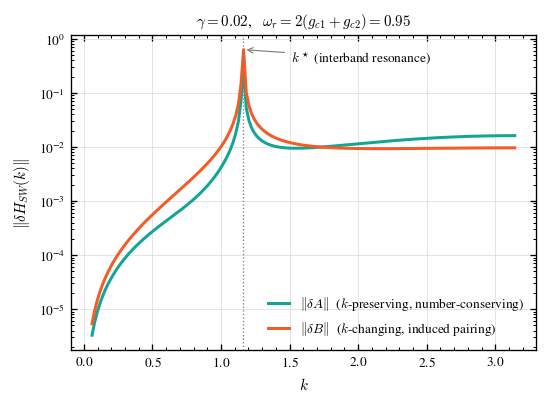

In [16]:
# --- k-dependence of the two pieces, with omega_r on the interband resonance
omega_r = 2 * (g_cap_intra + g_cap_inter)
resonant_bloch_mag = 0.5 * omega_r * np.sqrt(1 - omega_r**2 / 4)
resonant_momentum = np.arccos(np.clip(
    (resonant_bloch_mag**2 - g_cap_intra**2 - g_cap_inter**2) / (2 * g_cap_intra * g_cap_inter), -1, 1))
print(f"omega_r = 2(g_cap_intra + g_cap_inter) = {omega_r:.5f}")
print(f"resonant momentum   k* = {resonant_momentum:.5f}  ({resonant_momentum/np.pi:.4f} pi),   "
      f"interband gap there = {np.sqrt(1 + 2*resonant_bloch_mag) - np.sqrt(1 - 2*resonant_bloch_mag):.5f}")

momenta = np.linspace(0.06, np.pi, 160)
momenta = momenta[np.abs(momenta - resonant_momentum) > 3e-3]     # skip the exact pole
gamma = 0.02
norm_number, norm_pairing = [], []
for k in momenta:
    _, sw_number, sw_pairing = sw_correction(
        k, g_cap_intra, g_cap_inter, Omega_J, Chi_J, omega_r, gamma)
    norm_number.append(np.linalg.norm(sw_number))
    norm_pairing.append(np.linalg.norm(sw_pairing))
norm_number, norm_pairing = np.array(norm_number), np.array(norm_pairing)

fig, ax = plt.subplots(figsize=ts.figsize(1.5))
ax.semilogy(momenta, norm_number, color=ts.COLORS["teal"], lw=1.8,
            label=r"$\|\delta A\|$  ($k$-preserving, number-conserving)")
ax.semilogy(momenta, norm_pairing, color=ts.COLORS["orange"], lw=1.8,
            label=r"$\|\delta B\|$  ($k$-changing, induced pairing)")
ax.axvline(resonant_momentum, color="0.5", lw=0.8, ls=":")
ax.annotate(r"$k^\star$ (interband resonance)",
            xy=(resonant_momentum, norm_pairing.max()),
            xytext=(resonant_momentum + 0.35, norm_pairing.max()),
            fontsize=8, va="top", arrowprops=dict(arrowstyle="->", lw=0.7, color="0.5"))
ax.set_xlabel(r"$k$"); ax.set_ylabel(r"$\|\delta H_{SW}(k)\|$")
ax.set_title(rf"$\gamma={gamma}$,   $\omega_r=2(g_{{c1}}+g_{{c2}})={omega_r:.2f}$", fontsize=9)
ax.legend()
ts.finalize(ax)
plt.show()

probe_momentum = 1.2211
  ||sw_number||  ~ 58.08 gamma^2   (k-preserving)
  ||sw_pairing|| ~ 106.71 gamma^2   (k-changing, induced pairing)
  ratio ||sw_pairing||/||sw_number|| = 1.837  (gamma-independent -> both are 2nd order)


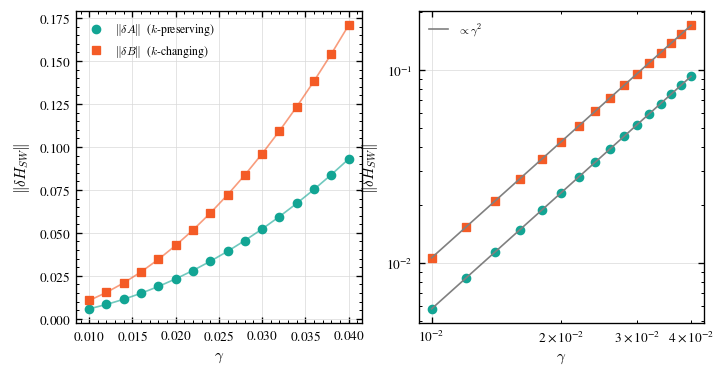

In [17]:
# --- gamma dependence of the two pieces (gamma = 0.01 ... 0.04) -----------
gamma_values = np.linspace(0.01, 0.04, 16)
probe_momentum = resonant_momentum + 0.06                # near the resonance, off the pole

norm_number_vs_gamma, norm_pairing_vs_gamma = [], []
for gamma in gamma_values:
    _, sw_number, sw_pairing = sw_correction(
        probe_momentum, g_cap_intra, g_cap_inter, Omega_J, Chi_J, omega_r, gamma)
    norm_number_vs_gamma.append(np.linalg.norm(sw_number))
    norm_pairing_vs_gamma.append(np.linalg.norm(sw_pairing))
norm_number_vs_gamma  = np.array(norm_number_vs_gamma)
norm_pairing_vs_gamma = np.array(norm_pairing_vs_gamma)

mid = len(gamma_values) // 2
slope_number  = norm_number_vs_gamma[mid]  / gamma_values[mid]**2
slope_pairing = norm_pairing_vs_gamma[mid] / gamma_values[mid]**2
print(f"probe_momentum = {probe_momentum:.4f}")
print(f"  ||sw_number||  ~ {slope_number:.2f} gamma^2   (k-preserving)")
print(f"  ||sw_pairing|| ~ {slope_pairing:.2f} gamma^2   (k-changing, induced pairing)")
print(f"  ratio ||sw_pairing||/||sw_number|| = {np.mean(norm_pairing_vs_gamma / norm_number_vs_gamma):.3f}  "
      f"(gamma-independent -> both are 2nd order)")

fig, axs = plt.subplots(1, 2, figsize=ts.figsize(2, ratio=0.5))
axs[0].plot(gamma_values, norm_number_vs_gamma, "o", color=ts.COLORS["teal"], ms=5,
            label=r"$\|\delta A\|$  ($k$-preserving)")
axs[0].plot(gamma_values, norm_pairing_vs_gamma, "s", color=ts.COLORS["orange"], ms=5,
            label=r"$\|\delta B\|$  ($k$-changing)")
axs[0].plot(gamma_values, slope_number * gamma_values**2, "-", color=ts.COLORS["teal"], lw=1, alpha=0.6)
axs[0].plot(gamma_values, slope_pairing * gamma_values**2, "-", color=ts.COLORS["orange"], lw=1, alpha=0.6)
axs[0].set_xlabel(r"$\gamma$"); axs[0].set_ylabel(r"$\|\delta H_{SW}\|$")
axs[0].legend(fontsize=7)

axs[1].loglog(gamma_values, norm_number_vs_gamma, "o", color=ts.COLORS["teal"], ms=5)
axs[1].loglog(gamma_values, norm_pairing_vs_gamma, "s", color=ts.COLORS["orange"], ms=5)
axs[1].loglog(gamma_values, slope_number * gamma_values**2, "-", color="0.5", lw=1, label=r"$\propto\gamma^2$")
axs[1].loglog(gamma_values, slope_pairing * gamma_values**2, "-", color="0.5", lw=1)
axs[1].set_xlabel(r"$\gamma$"); axs[1].set_ylabel(r"$\|\delta H_{SW}\|$")
axs[1].legend(fontsize=7)

ts.finalize(axs)
plt.show()

### The SW correction as matrix elements in the composite (cavity $\otimes$ chain) space

`schrieffer_wolff_correction` does **not** eliminate the cavity — it eliminates only the
matter-non-number-conserving part of the coupling ($(a+a^\dagger)\,\tilde{\mathcal B}_J$, which
would take the single quasiparticle into the 3-QP sector) and folds it into a 2nd-order term
$H_{\rm SW}$ that lives in the *same* composite space as $H$: $(\text{cavity Fock})\otimes
(\text{single-QP matter})$, and is added as `chain.H = chain.H + chain.H_SW`.

Per $\{k,-k\}$ sector the single-QP matter space is $\{\alpha_k,\beta_k,\alpha_{-k},\beta_{-k}\}$,
so $H_{\rm SW}$ is a $4\,d_{\rm ph}\times4\,d_{\rm ph}$ matrix. Transcribed verbatim from
`ssh_chain_sq` (same $V_r=\langle r|\tilde{\mathcal B}_J|X\rangle$, denominators
$n_{\rm mid}\omega_r + E_X - E_r$, `term1 - term2`, $s=\gamma(a+a^\dagger)$, symmetrise, $\times\tfrac12$).

Its structure: **block-diagonal in the QP mode** (each $\gamma_i$ dressed on its own — crystal
momentum and, to leading order, band index are conserved), with each block carrying a cavity
$\Delta n_{\rm ph}=0$ piece (dispersive/Stark shift) and a $\Delta n_{\rm ph}=\pm2$ piece
(cavity two-photon squeezing $\propto a^{\dagger2},a^2$).

- **$k$-preserving** = the mode-diagonal part $\gamma_{k\gamma}^\dagger\gamma_{k\gamma}\otimes(\dots)_{\rm cav}$;
- **$k$-changing** = the mode-off-diagonal part, i.e. the residual interband
  $\gamma_{k\alpha}^\dagger\gamma_{k\beta}$ scattering (from the same-band elements of
  $\tilde{\mathcal B}_J$) — small here ($\sim10^{-3}$–$10^{-2}$ of the total), since the pairing
  block predominantly pairs $\alpha_k$ with $\beta_{-k}$.


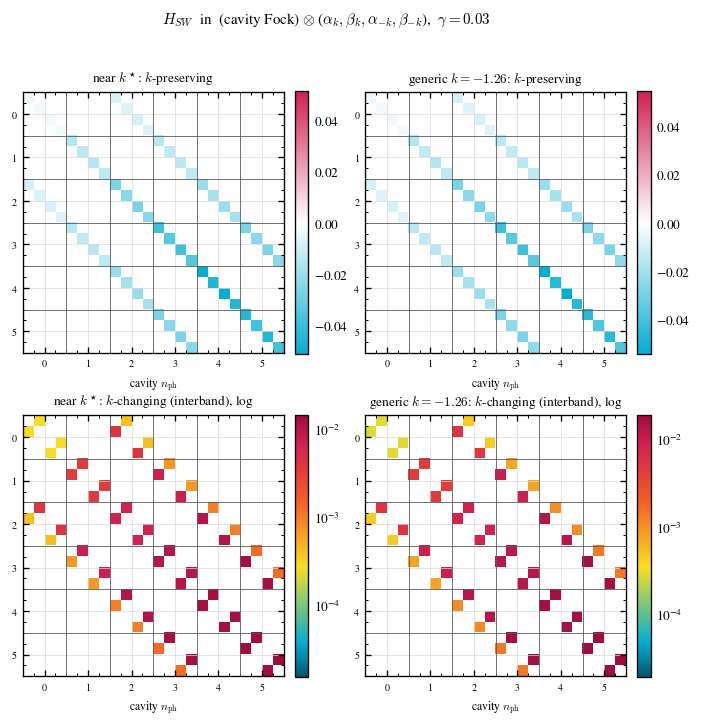

In [18]:
from matplotlib.colors import LogNorm

def H_SW_composite(k, omega_r, gamma, photon_cutoff=6, qp_fock_cutoff=4, denom_floor=1e-6):
    """Verbatim schrieffer_wolff_correction, per {k,-k} sector: 2nd-order elimination
    of the pairing block ~B_J (single-QP -> 3-QP virtual r), photon ladder = gamma(a + a^dag).
    Returns H_SW on (cavity Fock photon_cutoff) x (alpha_k, beta_k, alpha_-k, beta_-k)."""
    H_cap, H_joseph = sector_nambu_at_k(k, g_cap_intra, g_cap_inter, Omega_J, Chi_J)
    transform, H_cap_diag = diagonalize_cap_sector(H_cap, k, g_cap_intra, g_cap_inter)
    H_joseph_qp = transform.conj().T @ H_joseph @ transform
    num_qp_modes = 4
    qp_freqs = 2.0 * np.diag(H_cap_diag[:num_qp_modes, :num_qp_modes]).real   # single-QP energies
    joseph_pairing_qp = 2.0 * H_joseph_qp[:num_qp_modes, num_qp_modes:]       # pairing block ~B_J

    single_mode_lower = np.diag(np.sqrt(np.arange(1, qp_fock_cutoff)), 1)
    single_mode_raise = single_mode_lower.conj().T
    def mode_operator(target_mode, dagger):
        full = np.array([[1.0]])
        for mode in range(num_qp_modes):
            full = np.kron(full, (single_mode_raise if dagger else single_mode_lower)
                           if mode == target_mode else np.eye(qp_fock_cutoff))
        return full
    qp_creation = [mode_operator(mode, dagger=True) for mode in range(num_qp_modes)]
    qp_fock_states = list(np.ndindex(*([qp_fock_cutoff] * num_qp_modes)))
    total_excitations = np.array([sum(state) for state in qp_fock_states])
    pairing_operator = sum(joseph_pairing_qp[i, j] * (qp_creation[i] @ qp_creation[j])
                           for i in range(num_qp_modes) for j in range(num_qp_modes))
    idx_single_qp = np.where(total_excitations == 1)[0]
    idx_virtual   = np.where(total_excitations == 3)[0]
    fock_energies = np.array(qp_fock_states) @ qp_freqs
    energy_single_qp, energy_virtual = fock_energies[idx_single_qp], fock_energies[idx_virtual]
    pairing_matrix_elements = pairing_operator[np.ix_(idx_virtual, idx_single_qp)]   # <r|B_J|X>
    single_qp_order = np.argsort([qp_fock_states[x].index(1) for x in idx_single_qp])
    energy_single_qp = energy_single_qp[single_qp_order]
    pairing_matrix_elements = pairing_matrix_elements[:, single_qp_order]
    dim_single_qp = 4

    photon_ladder = np.zeros((photon_cutoff, photon_cutoff))
    for n in range(photon_cutoff - 1):
        photon_ladder[n, n + 1] = photon_ladder[n + 1, n] = gamma * np.sqrt(n + 1)

    H_SW = np.zeros((photon_cutoff * dim_single_qp, photon_cutoff * dim_single_qp), dtype=complex)
    for n_bra in range(photon_cutoff):
        for n_ket in range(photon_cutoff):
            for n_mid in range(photon_cutoff):
                ladder_factor = photon_ladder[n_bra, n_mid] * photon_ladder[n_mid, n_ket]
                if abs(ladder_factor) < 1e-15:
                    continue
                denom_first  = ((n_bra - n_mid) * omega_r
                                + energy_single_qp[:, None] - energy_virtual[None, :])
                denom_second = ((n_mid - n_ket) * omega_r
                                + energy_virtual[:, None] - energy_single_qp[None, :])
                resolvent_first  = np.where(np.abs(denom_first) > denom_floor,
                                            1 / np.where(np.abs(denom_first) > denom_floor, denom_first, 1), 0)
                resolvent_second = np.where(np.abs(denom_second) > denom_floor,
                                            1 / np.where(np.abs(denom_second) > denom_floor, denom_second, 1), 0)
                block = ladder_factor * (
                    (pairing_matrix_elements.T * resolvent_first) @ pairing_matrix_elements.conj()
                    - pairing_matrix_elements.T @ (pairing_matrix_elements.conj() * resolvent_second))
                H_SW[n_bra * dim_single_qp:(n_bra + 1) * dim_single_qp,
                     n_ket * dim_single_qp:(n_ket + 1) * dim_single_qp] += block
    H_SW = 0.5 * (H_SW + H_SW.conj().T)
    return 0.5 * H_SW


photon_cutoff, gamma = 6, 0.03
panels = [(resonant_momentum + 0.05, r"near $k^\star$"),
          (float(k_grid(num_cells)[3]), rf"generic $k={k_grid(num_cells)[3]:.2f}$")]

fig, axs = plt.subplots(2, 2, figsize=ts.figsize(2, ratio=0.95))
for col, (k, title) in enumerate(panels):
    H_SW = H_SW_composite(k, 2 * (g_cap_intra + g_cap_inter), gamma, photon_cutoff=photon_cutoff)
    qp_mode = np.arange(photon_cutoff * 4) % 4
    same_mode = qp_mode[:, None] == qp_mode[None, :]

    # --- k-preserving: signed, linear diverging ---
    k_preserving = np.where(same_mode, H_SW.real, 0.0)
    vmax = np.abs(k_preserving).max()
    ax = axs[0, col]
    image = ax.imshow(k_preserving, cmap="thesis_cmap_diverging", vmin=-vmax, vmax=vmax)
    fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
    ax.set_title(f"{title}: $k$-preserving", fontsize=8)

    # --- k-changing: magnitude, log colour scale ---
    k_changing = np.abs(np.where(~same_mode, H_SW, np.nan))
    color_hi = np.nanmax(k_changing); color_lo = color_hi * 1e-3
    ax = axs[1, col]
    image = ax.imshow(k_changing, cmap="thesis_cmap", norm=LogNorm(vmin=color_lo, vmax=color_hi))
    fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
    ax.set_title(f"{title}: $k$-changing (interband), log", fontsize=8)

    for ax in axs[:, col]:
        for boundary in range(1, photon_cutoff):
            ax.axhline(4 * boundary - 0.5, color="0.35", lw=0.5)
            ax.axvline(4 * boundary - 0.5, color="0.35", lw=0.5)
        ax.set_xticks(np.arange(photon_cutoff) * 4 + 1.5)
        ax.set_xticklabels(range(photon_cutoff), fontsize=6)
        ax.set_yticks(np.arange(photon_cutoff) * 4 + 1.5)
        ax.set_yticklabels(range(photon_cutoff), fontsize=6)
        ax.set_xlabel(r"cavity $n_{\rm ph}$", fontsize=7)

fig.suptitle(r"$H_{SW}$  in  (cavity Fock) $\otimes$ ($\alpha_k,\beta_k,\alpha_{-k},\beta_{-k}$),"
             rf"  $\gamma={gamma}$", fontsize=9)
plt.show()

### Parameter sweep: peak of the $k$-non-conserving part of $H_{\rm SW}$

For each $(\chi_C,\Omega_C)$ (with $\omega_r = 2(g_{c1}+g_{c2}) = \Omega_C$, on the interband
resonance), sweep $k$ across the BZ and record the largest matrix element of the **mode-off-diagonal
(interband, $k$-changing) part** of $H_{\rm SW}(k)$, normalised by $\gamma^2$.

The normalisation is exact: the only $\gamma$-dependence of the 2nd-order $H_{\rm SW}$ is
$s=\gamma(a+a^\dagger)$ entering quadratically, so $H_{\rm SW}/\gamma^2$ is $\gamma$-independent by
construction — the discrete-$\gamma$ curves collapse onto a single surface (right panel).

The $k$-changing part **vanishes on the $\chi_C=0$ line**: there $g_{c1}=g_{c2}$, the pairing block
$\tilde{\mathcal B}_J$ is exactly band-diagonal, and $H_{\rm SW}$ cannot scatter $\alpha_k\to\beta_k$.
Dimerisation ($\chi_C\neq0$) switches it on; it grows with $|\chi_C|$ and with $\Omega_C$
(both increase $\|\tilde{\mathcal B}_J\|$).


In [19]:
# --- sweep (Chi_C, Omega_C) continuous, gamma discrete: peak k-changing / gamma^2
qp_fock_cutoff, photon_cutoff, num_qp_modes = 4, 4, 4
single_mode_lower = np.diag(np.sqrt(np.arange(1, qp_fock_cutoff)), 1)
single_mode_raise = single_mode_lower.conj().T
def mode_operator(target_mode, dagger):
    full = np.array([[1.0]])
    for mode in range(num_qp_modes):
        full = np.kron(full, (single_mode_raise if dagger else single_mode_lower)
                       if mode == target_mode else np.eye(qp_fock_cutoff))
    return full
qp_creation = [mode_operator(mode, dagger=True) for mode in range(num_qp_modes)]
qp_creation_pairs = [[qp_creation[i] @ qp_creation[j] for j in range(num_qp_modes)]
                     for i in range(num_qp_modes)]
qp_fock_states = np.array(list(np.ndindex(*([qp_fock_cutoff] * num_qp_modes))))
total_excitations = qp_fock_states.sum(1)
idx_single_qp = np.where(total_excitations == 1)[0][
    np.argsort([np.argmax(qp_fock_states[x]) for x in np.where(total_excitations == 1)[0]])]
idx_virtual = np.where(total_excitations == 3)[0]
photon_ladder = np.zeros((photon_cutoff, photon_cutoff))
for n in range(photon_cutoff - 1):
    photon_ladder[n, n + 1] = photon_ladder[n + 1, n] = np.sqrt(n + 1)
mode_off_diagonal = ((np.arange(photon_cutoff * num_qp_modes) % num_qp_modes)[:, None]
                     != (np.arange(photon_cutoff * num_qp_modes) % num_qp_modes)[None, :])


def peak_k_changing(Chi_C, Omega_C, momenta, denom_floor=1e-6):
    """max over the BZ of the largest |mode-off-diagonal H_SW element|, at gamma = 1
    (H_SW scales exactly as gamma^2, so this is the gamma^2-normalised value)."""
    g_cap_intra = 0.25 * Omega_C * (1 + Chi_C)
    g_cap_inter = 0.25 * Omega_C * (1 - Chi_C)
    omega_r = Omega_C
    best = 0.0
    for k in momenta:
        H_cap, H_joseph = sector_nambu_at_k(k, g_cap_intra, g_cap_inter, Omega_J, Chi_J)
        transform, H_cap_diag = diagonalize_cap_sector(H_cap, k, g_cap_intra, g_cap_inter)
        H_joseph_qp = transform.conj().T @ H_joseph @ transform
        qp_freqs = 2.0 * np.diag(H_cap_diag[:4, :4]).real
        joseph_pairing_qp = 2.0 * H_joseph_qp[:4, 4:]
        pairing_operator = sum(joseph_pairing_qp[i, j] * qp_creation_pairs[i][j]
                               for i in range(4) for j in range(4))
        fock_energies = qp_fock_states @ qp_freqs
        pairing_matrix_elements = pairing_operator[np.ix_(idx_virtual, idx_single_qp)]
        energy_single_qp, energy_virtual = fock_energies[idx_single_qp], fock_energies[idx_virtual]
        H_SW = np.zeros((photon_cutoff * 4, photon_cutoff * 4), dtype=complex)
        for n_bra in range(photon_cutoff):
            for n_ket in range(photon_cutoff):
                for n_mid in range(photon_cutoff):
                    ladder_factor = photon_ladder[n_bra, n_mid] * photon_ladder[n_mid, n_ket]
                    if ladder_factor == 0:
                        continue
                    denom_first  = (n_bra - n_mid) * omega_r + energy_single_qp[:, None] - energy_virtual[None, :]
                    denom_second = (n_mid - n_ket) * omega_r + energy_virtual[:, None] - energy_single_qp[None, :]
                    resolvent_first  = np.where(np.abs(denom_first) > denom_floor,
                                                1 / np.where(np.abs(denom_first) > denom_floor, denom_first, 1), 0)
                    resolvent_second = np.where(np.abs(denom_second) > denom_floor,
                                                1 / np.where(np.abs(denom_second) > denom_floor, denom_second, 1), 0)
                    H_SW[n_bra*4:n_bra*4+4, n_ket*4:n_ket*4+4] += ladder_factor * (
                        (pairing_matrix_elements.T * resolvent_first) @ pairing_matrix_elements.conj()
                        - pairing_matrix_elements.T @ (pairing_matrix_elements.conj() * resolvent_second))
        H_SW = 0.25 * (H_SW + H_SW.conj().T)
        best = max(best, np.abs(H_SW[mode_off_diagonal]).max())
    return best

bz_momenta = np.linspace(0.05, np.pi, 20)
chi_grid   = np.linspace(-0.95, 0.95, 25)
omega_c_grid = np.linspace(0.01, 0.95, 25)
peak_grid = np.array([[peak_k_changing(chi, omega_c, bz_momenta) for chi in chi_grid]
                      for omega_c in omega_c_grid])

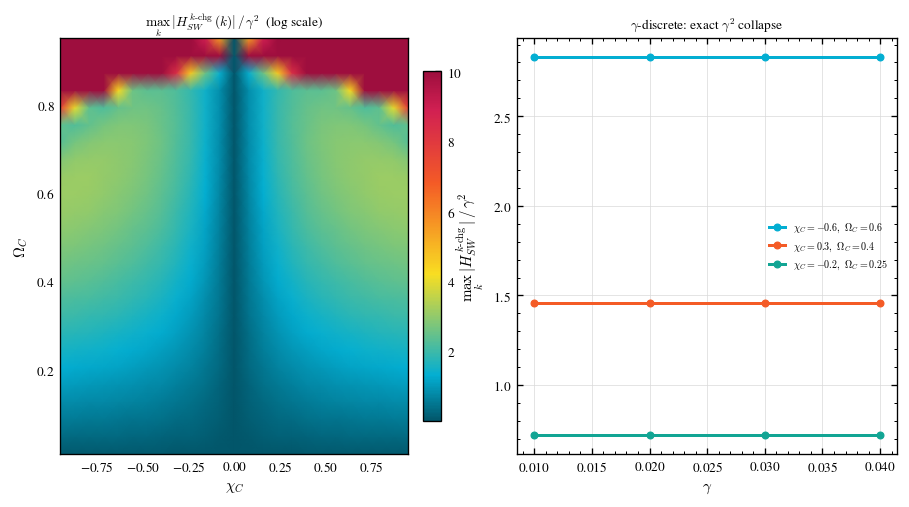

peak of the k-changing part / gamma^2 over the swept plane: 5310.088  at (Chi_C, Omega_C) = (-0.79, 0.95)
on the Chi_C = 0 line: max = 8.11e-14  (vanishes -- band-diagonal pairing)


In [20]:
fig, axs = plt.subplots(1, 2, figsize=ts.figsize(9, ratio=0.5))
from matplotlib.colors import LogNorm
image = axs[0].pcolormesh(chi_grid, omega_c_grid, np.clip(peak_grid, 1e-3, None),
                          cmap="thesis_cmap", shading="gouraud", vmin=1e-3, vmax=10)
axs[0].set_xlabel(r"$\chi_C$"); axs[0].set_ylabel(r"$\Omega_C$")
axs[0].set_title(r"$\max_k\,|H_{SW}^{\,k\text{-chg}}(k)|\,/\,\gamma^2$  (log scale)", fontsize=8)
fig.colorbar(image, ax=axs[0], fraction=0.046, pad=0.04)

# gamma-discrete collapse at three representative points
gamma_values = np.array([0.01, 0.02, 0.03, 0.04])
sample_points = [(-0.6, 0.6), (0.3, 0.4), (-0.2, 0.25)]
for chi, omega_c in sample_points:
    normalised_peak = peak_k_changing(chi, omega_c, bz_momenta)   # already the gamma^2-normalised value
    axs[1].plot(gamma_values, [normalised_peak] * len(gamma_values), "o-", ms=4,
                label=rf"$\chi_C={chi},\ \Omega_C={omega_c}$")
axs[1].set_xlabel(r"$\gamma$")
axs[1].set_ylabel(r"$\max_k\,|H_{SW}^{\,k\text{-chg}}|\,/\,\gamma^2$")
axs[1].set_title(r"$\gamma$-discrete: exact $\gamma^2$ collapse", fontsize=8)
axs[1].legend(fontsize=6)
ts.finalize(axs)
plt.show()

print(f"peak of the k-changing part / gamma^2 over the swept plane: {peak_grid.max():.3f}  "
      f"at (Chi_C, Omega_C) = ({chi_grid[np.argmax(peak_grid) % 25]:+.2f}, "
      f"{omega_c_grid[np.argmax(peak_grid) // 25]:.2f})")
print(f"on the Chi_C = 0 line: max = {peak_grid[:, np.argmin(np.abs(chi_grid))].max():.2e}  "
      f"(vanishes -- band-diagonal pairing)")

### Why the SW correction never jumps $k$: the structure of $\tilde H_J$

The whole SW correction is built out of $\tilde{\mathcal H}_J(k)=\mathcal T^\dagger\mathcal H_J^{(k)}\mathcal T$,
so its selection rules are inherited from that matrix. Plotting it for several $(\Omega_C,\chi_C)$
shows a **rigid checkerboard** — only the numbers change, never the pattern:

* the **number block** $\tilde{\mathcal A}_J$ is *momentum block-**diagonal***: only
  $\{+k\}\times\{+k\}$ and $\{-k\}\times\{-k\}$ entries survive. It can flip the band
  ($\alpha_k\!\leftrightarrow\!\beta_k$) but never the momentum.
* the **pairing block** $\tilde{\mathcal B}_J$ is *momentum block-**anti**-diagonal*: only
  $\{+k\}\times\{-k\}$ entries survive. Every $\hat B$ therefore creates one $+k$ and one $-k$
  quasiparticle — a **zero-momentum pair**.

So every insertion of the coupling either leaves the momentum alone or adds/removes a zero-momentum
pair. A single quasiparticle at $+k$ can never end up at $-k$ — which is exactly what the composite
$H_{\rm SW}$ plots show, and why its off-diagonal part is purely *interband* at fixed $k$.

Extra: at $\chi_C=0$ the pattern narrows further — the band-diagonal entries of
$\tilde{\mathcal B}_J$ switch off, leaving only $\alpha\!-\!\beta$ pairing. That is the origin of the
$\chi_C=0$ trench in the interband sweep above.


structural norms  (identically 0, for every parameter):
  Omega_C=0.10 Chi_C=-0.60:  ||A_J[+k,-k]||=0.0e+00   ||B_J[+k,+k]||=0.0e+00   (interband |A_J[a_k,b_k]| = 1.099)
  Omega_C=0.10 Chi_C=+0.00:  ||A_J[+k,-k]||=0.0e+00   ||B_J[+k,+k]||=0.0e+00   (interband |A_J[a_k,b_k]| = 1.208)
  Omega_C=0.10 Chi_C=+0.60:  ||A_J[+k,-k]||=0.0e+00   ||B_J[+k,+k]||=0.0e+00   (interband |A_J[a_k,b_k]| = 1.099)
  Omega_C=0.70 Chi_C=-0.60:  ||A_J[+k,-k]||=0.0e+00   ||B_J[+k,+k]||=0.0e+00   (interband |A_J[a_k,b_k]| = 0.979)
  Omega_C=0.70 Chi_C=+0.00:  ||A_J[+k,-k]||=0.0e+00   ||B_J[+k,+k]||=0.0e+00   (interband |A_J[a_k,b_k]| = 1.103)
  Omega_C=0.70 Chi_C=+0.60:  ||A_J[+k,-k]||=0.0e+00   ||B_J[+k,+k]||=0.0e+00   (interband |A_J[a_k,b_k]| = 0.979)


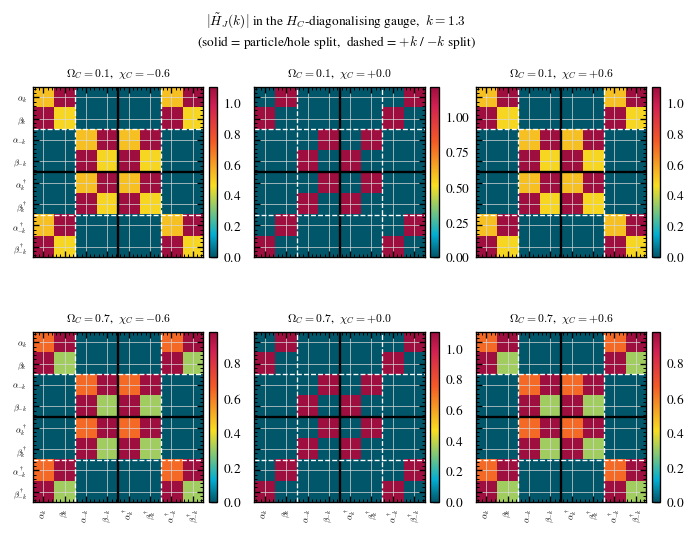

In [21]:
# --- why the SW correction never jumps k: the structure of the transformed H_joseph
# joseph_in_qp_gauge(k) = transform^dag H_joseph^(k) transform  in the {k,-k} sector, basis
#   (alpha_k, beta_k, alpha_-k, beta_-k)  then their daggers.
# Momentum blocks are the 2x2 groups; the particle/hole (Nambu) split is at index 4.

probe_momentum = 1.3                            # any generic k
omega_c_values = [0.10, 0.70]                   # Omega_C  (needs Omega_C < 1 for the squeeze)
chi_c_values   = [-0.60, 0.00, 0.60]            # Chi_C

def joseph_in_qp_gauge(k, Omega_C, Chi_C):
    g_cap_intra, g_cap_inter = 0.25 * Omega_C * (1 + Chi_C), 0.25 * Omega_C * (1 - Chi_C)
    H_cap, H_joseph = sector_nambu_at_k(k, g_cap_intra, g_cap_inter, Omega_J, Chi_J)
    transform, _ = diagonalize_cap_sector(H_cap, k, g_cap_intra, g_cap_inter)
    return 2.0 * (transform.conj().T @ H_joseph @ transform)    # physical convention

mode_labels = [r"$\alpha_k$", r"$\beta_k$", r"$\alpha_{-k}$", r"$\beta_{-k}$",
               r"$\alpha_k^\dagger$", r"$\beta_k^\dagger$", r"$\alpha_{-k}^\dagger$", r"$\beta_{-k}^\dagger$"]

fig, axs = plt.subplots(len(omega_c_values), len(chi_c_values), figsize=ts.figsize(2, ratio=0.72))
print("structural norms  (identically 0, for every parameter):")
for row, Omega_C_val in enumerate(omega_c_values):
    for col, Chi_C_val in enumerate(chi_c_values):
        joseph_qp = joseph_in_qp_gauge(probe_momentum, Omega_C_val, Chi_C_val)
        number_block, pairing_block = joseph_qp[:4, :4], joseph_qp[:4, 4:]
        print(f"  Omega_C={Omega_C_val:.2f} Chi_C={Chi_C_val:+.2f}:  "
              f"||A_J[+k,-k]||={np.linalg.norm(number_block[:2, 2:]):.1e}   "
              f"||B_J[+k,+k]||={np.linalg.norm(pairing_block[:2, :2]):.1e}   "
              f"(interband |A_J[a_k,b_k]| = {abs(number_block[0, 1]):.3f})")
        ax = axs[row, col]
        image = ax.imshow(np.abs(joseph_qp), cmap="thesis_cmap")
        ax.axhline(3.5, color="k", lw=1.4); ax.axvline(3.5, color="k", lw=1.4)     # Nambu split
        for boundary in (1.5, 5.5):                                                 # +k / -k split
            ax.axhline(boundary, color="w", lw=0.8, ls="--")
            ax.axvline(boundary, color="w", lw=0.8, ls="--")
        ax.set_xticks(range(8)); ax.set_yticks(range(8))
        ax.set_xticklabels(mode_labels if row == len(omega_c_values) - 1 else [], fontsize=5, rotation=90)
        ax.set_yticklabels(mode_labels if col == 0 else [], fontsize=5)
        ax.set_title(rf"$\Omega_C={Omega_C_val}$,  $\chi_C={Chi_C_val:+.1f}$", fontsize=7)
        fig.colorbar(image, ax=ax, fraction=0.046, pad=0.03)
fig.suptitle(rf"$|\tilde H_J(k)|$ in the $H_C$-diagonalising gauge,  $k={probe_momentum}$"
             "\n(solid = particle/hole split,  dashed = $+k$ / $-k$ split)", fontsize=8)
plt.show()

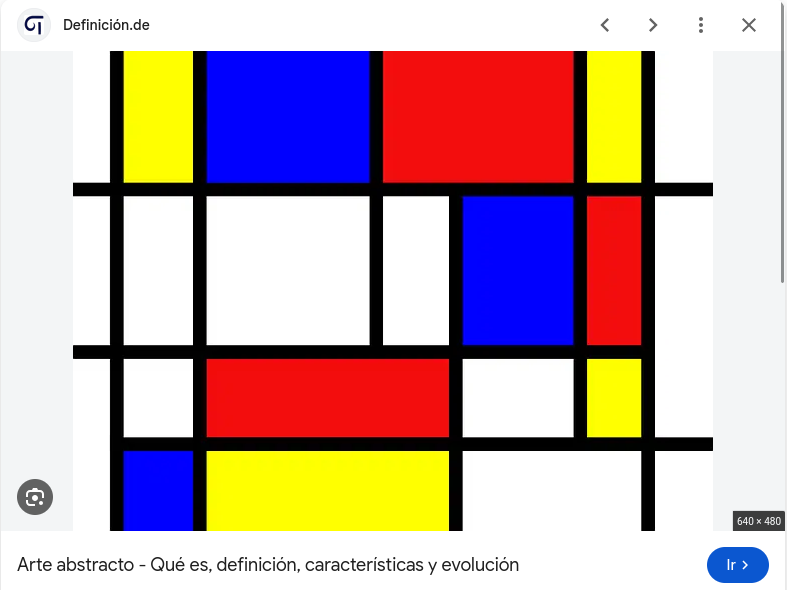

# Zak phase of the cavity-dressed second band
Per $k$ (momentum conserved → exact per sector), diagonalise on ${\alpha_k,\beta_k}\otimes(\text{cavity Fock})$:
$$H_{\rm eff}(k)=\omega_r a^\dagger a+\operatorname{diag}(\omega_{k\alpha},\omega_{k\beta})-\gamma(a+a^\dagger)\otimes(\tilde{\mathcal A}J+\tilde{\mathcal A}J^\dagger){+k}+H{\rm SW}^{+k}(k).$$
First three terms = build_full_hamiltonian in the single-QP subspace; last = the full SW correction (it never mixes $\pm k$, only bands). The direct $-\gamma(a+a^\dagger)\tilde{\mathcal A}_J$ term opens the gap — a JC anticrossing between $|\alpha_k,0\rangle$ and $|\beta_k,1\rangle$ at $k^\star$.

Inner product: lift each eigenvector $C^{(n)}(k)\in\mathbb C^{2\times d_{\rm ph}}$ into the fixed $\mathbb C^2_{\rm sub}\otimes\mathbb C^{d_{\rm ph}}{\rm cav}$ basis, $\Psi_n(k)=U(k)C^{(n)}(k)$, $U(k)=[u\alpha(k)|u_\beta(k)]$ the SSH Bloch spinors; then $\langle\psi_n(k)|\psi_n(k')\rangle=\Psi_n(k)^\dagger\Psi_n(k')$. BZ closure $\hat g=\operatorname{diag}(e^{-2\pi i s_A},e^{-2\pi i s_B})\otimes\mathbb 1_{d_{\rm ph}}$ — sublattice half only.

In [22]:
# --- cavity-dressed bands: diagonalise H_eff(k), Zak phase in (sublattice (x) cavity)
def ssh_bloch_spinors(k, g_cap_intra, g_cap_inter):
    bloch_cap = g_cap_intra + g_cap_inter * np.exp(-1j * k)
    _, eigenvectors = np.linalg.eigh(np.array([[0.0 + 0j, bloch_cap], [np.conj(bloch_cap), 0.0]]))
    return eigenvectors[:, [1, 0]]                              # [u_alpha (+|d|) | u_beta (-|d|)]


def H_eff_dressed(k, g_cap_intra, g_cap_inter, omega_r, gamma, photon_cutoff=6):
    """H_eff on {alpha_k, beta_k} (x) (cavity Fock), ordering n*2 + s  (s: 0=alpha, 1=beta)."""
    H_cap, H_joseph = sector_nambu_at_k(k, g_cap_intra, g_cap_inter, Omega_J, Chi_J)
    transform, H_cap_diag = diagonalize_cap_sector(H_cap, k, g_cap_intra, g_cap_inter)
    H_joseph_qp = transform.conj().T @ H_joseph @ transform
    qp_freqs = 2.0 * np.diag(H_cap_diag[:2, :2]).real
    matter_coupling = H_joseph_qp[:2, :2] + H_joseph_qp[:2, :2].conj().T   # = A_J + D_J^T  (number-conserving, +k)
    photon_lower = np.diag(np.sqrt(np.arange(1, photon_cutoff)), 1)
    H_eff = np.diag(np.array([omega_r * n + qp_freqs[s]
                              for n in range(photon_cutoff) for s in (0, 1)], dtype=complex))
    H_eff += -gamma * np.kron(photon_lower + photon_lower.conj().T, matter_coupling)
    H_sw_composite = H_SW_composite(k, omega_r, gamma, photon_cutoff=photon_cutoff)
    plus_k_indices = [n * 4 + s for n in range(photon_cutoff) for s in (0, 1)]     # +k block
    H_eff += H_sw_composite[np.ix_(plus_k_indices, plus_k_indices)]
    return H_eff, ssh_bloch_spinors(k, g_cap_intra, g_cap_inter)


def dressed_state(k, g_cap_intra, g_cap_inter, omega_r, gamma, band, photon_cutoff=6):
    H_eff, bloch_spinors = H_eff_dressed(k, g_cap_intra, g_cap_inter, omega_r, gamma, photon_cutoff)
    _, eigenvectors = np.linalg.eigh(H_eff)
    bands = band if np.iterable(band) else [band]
    lifted = np.stack([(bloch_spinors @ eigenvectors[:, b].reshape(photon_cutoff, 2).T).reshape(-1)
                       for b in bands], axis=1)
    return lifted if np.iterable(band) else lifted[:, 0]


def zak_dressed(g_cap_intra, g_cap_inter, omega_r, gamma, band,
                num_k_points=300, sublattice_positions=(-0.25, 0.25), photon_cutoff=6):
    momenta = np.linspace(0.0, 2 * np.pi, num_k_points, endpoint=False)
    states_along_loop = [dressed_state(k, g_cap_intra, g_cap_inter, omega_r, gamma, band, photon_cutoff)
                         for k in momenta]
    bz_boundary_phase = np.repeat(np.exp(-1j * 2 * np.pi * np.asarray(sublattice_positions)), photon_cutoff)
    if np.iterable(band):                                       # multiband: det Wilson loop
        wilson_matrix = np.eye(len(band), dtype=complex)
        for j in range(num_k_points):
            next_state = ((bz_boundary_phase[:, None] * states_along_loop[0]) if j == num_k_points - 1
                          else states_along_loop[(j + 1) % num_k_points])
            wilson_matrix = wilson_matrix @ (states_along_loop[j].conj().T @ next_state)
        return -np.angle(np.linalg.det(wilson_matrix))
    wilson_product = (np.prod([np.vdot(states_along_loop[j], states_along_loop[j + 1])
                               for j in range(num_k_points - 1)])
                      * np.vdot(states_along_loop[-1], bz_boundary_phase * states_along_loop[0]))
    return -np.angle(wilson_product)


omega_r = 2 * (g_cap_intra + g_cap_inter)
print(f"chi_C={Chi_C}, Omega_C={Omega_C}, gamma=0.03, omega_r={omega_r:.3f}\n")
for band, label in [(0, "band 0  |beta_k,0>  (zero-photon lower)"),
                    (1, "band 1  = SECOND band (lower polariton)"),
                    (2, "band 2  (upper polariton)"),
                    ([1, 2], "bands {1,2} combined")]:
    print(f"  gamma_Zak[{label}] = "
          f"{zak_dressed(g_cap_intra, g_cap_inter, omega_r, 0.03, band) / np.pi:+.4f} pi")

print("\ncavity switches the second band topological:")
for gamma in (0.0, 0.01, 0.03, 0.05):
    print(f"  gamma = {gamma:.3f}:  "
          f"{zak_dressed(g_cap_intra, g_cap_inter, 2*(g_cap_intra+g_cap_inter), gamma, 1, num_k_points=180) / np.pi:+.4f} pi")

for Chi_C_val in (0.5, -0.5):
    g_cap_intra_val = 0.25 * Omega_C * (1 + Chi_C_val)
    g_cap_inter_val = 0.25 * Omega_C * (1 - Chi_C_val)
    zak_band_1 = zak_dressed(g_cap_intra_val, g_cap_inter_val,
                             2*(g_cap_intra_val+g_cap_inter_val), 0.03, 1, num_k_points=180)
    zak_band_0 = zak_dressed(g_cap_intra_val, g_cap_inter_val,
                             2*(g_cap_intra_val+g_cap_inter_val), 0.03, 0, num_k_points=180)
    print(f"  chi_C={Chi_C_val:+.2f}:  band0 {zak_band_0/np.pi:+.2f} pi   band1 {zak_band_1/np.pi:+.2f} pi")

chi_C=0.5, Omega_C=0.95, gamma=0.03, omega_r=0.950

  gamma_Zak[band 0  |beta_k,0>  (zero-photon lower)] = -0.0000 pi
  gamma_Zak[band 1  = SECOND band (lower polariton)] = +1.0000 pi
  gamma_Zak[band 2  (upper polariton)] = -1.0000 pi
  gamma_Zak[bands {1,2} combined] = -0.0000 pi

cavity switches the second band topological:
  gamma = 0.000:  -0.0000 pi
  gamma = 0.010:  -1.0000 pi
  gamma = 0.030:  -1.0000 pi
  gamma = 0.050:  -1.0000 pi
  chi_C=+0.50:  band0 +0.00 pi   band1 -1.00 pi
  chi_C=-0.50:  band0 -1.00 pi   band1 -0.00 pi


In [23]:
# --- dressed band structure  and  Zak(band 1) vs cavity frequency ----------
photon_cutoff, gamma = 6, 0.02
bloch_magnitude_half_bz = np.abs(g_cap_intra + g_cap_inter * np.exp(-1j * np.linspace(0, np.pi, 400)))
interband_gap = np.sqrt(1 + 2 * bloch_magnitude_half_bz) - np.sqrt(1 - 2 * bloch_magnitude_half_bz)
gap_min, gap_max = float(interband_gap.min()), float(interband_gap.max())   # [gap(pi), gap(0)]

omega_r_in_window = 0.5 * (gap_min + gap_max)               # a value inside the window
k_dense = np.linspace(-np.pi, np.pi, 241)
energies_vs_k = np.array([
    np.linalg.eigvalsh(H_eff_dressed(k, g_cap_intra, g_cap_inter, omega_r_in_window, gamma, photon_cutoff)[0])
    for k in k_dense])

omega_r_values = np.linspace(0.01, 0.30, 32) * 5
zak_band_1     = np.array([zak_dressed(g_cap_intra, g_cap_inter, omega_r, gamma, 1,
                                       num_k_points=120, photon_cutoff=photon_cutoff)
                           for omega_r in omega_r_values])
zak_bands_1_2  = np.array([zak_dressed(g_cap_intra, g_cap_inter, omega_r, gamma, [1, 2],
                                       num_k_points=120, photon_cutoff=photon_cutoff)
                           for omega_r in omega_r_values])

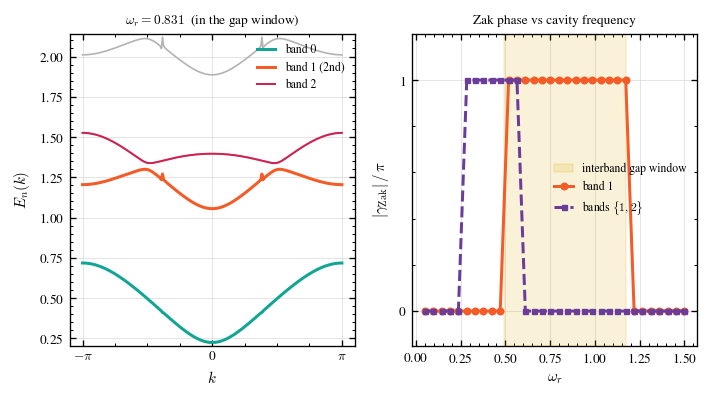

interband gap window [gap(pi), gap(0)] = [0.490, 1.173]


In [24]:
fig, axs = plt.subplots(1, 2, figsize=ts.figsize(2, ratio=0.5))

for band in range(6):
    axs[0].plot(k_dense, energies_vs_k[:, band], color="0.7", lw=1.0)
axs[0].plot(k_dense, energies_vs_k[:, 0], color=ts.COLORS["teal"],   lw=1.8, label="band 0")
axs[0].plot(k_dense, energies_vs_k[:, 1], color=ts.COLORS["orange"], lw=1.8, label="band 1 (2nd)")
axs[0].plot(k_dense, energies_vs_k[:, 2], color=ts.COLORS["red"],    lw=1.2, label="band 2")
axs[0].set_xlabel(r"$k$"); axs[0].set_ylabel(r"$E_n(k)$")
axs[0].set_xticks([-np.pi, 0, np.pi]); axs[0].set_xticklabels([r"$-\pi$", "0", r"$\pi$"])
axs[0].set_ylim(energies_vs_k[:, :4].min() - 0.02, energies_vs_k[:, 3].max() + 0.02)
axs[0].set_title(rf"$\omega_r = {omega_r_in_window:.3f}$  (in the gap window)", fontsize=8)
axs[0].legend(fontsize=7)

axs[1].axvspan(gap_min, gap_max, color=ts.COLORS["gold"], alpha=0.15, label="interband gap window")
axs[1].plot(omega_r_values, np.abs(zak_band_1) / np.pi,    "o-",  color=ts.COLORS["orange"], ms=4, label="band 1")
axs[1].plot(omega_r_values, np.abs(zak_bands_1_2) / np.pi, "s--", color=ts.COLORS["purple"], ms=3, label=r"bands $\{1,2\}$")
axs[1].set_xlabel(r"$\omega_r$"); axs[1].set_ylabel(r"$|\gamma_{\rm Zak}|\,/\,\pi$")
axs[1].set_yticks([0, 1]); axs[1].set_ylim(-0.15, 1.2)
axs[1].set_title("Zak phase vs cavity frequency", fontsize=8)
axs[1].legend(fontsize=7)
ts.finalize(axs)
plt.show()

print(f"interband gap window [gap(pi), gap(0)] = [{gap_min:.3f}, {gap_max:.3f}]")

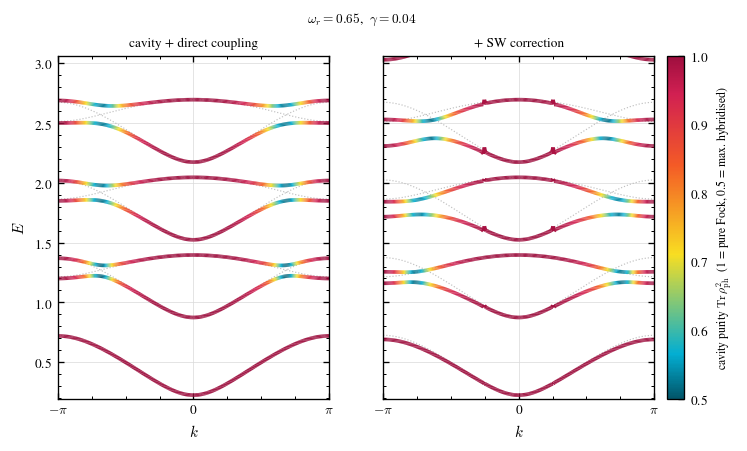

In [25]:
from matplotlib.collections import LineCollection

photon_cutoff, gamma, omega_r = 4, 0.04, 0.65          # one cavity frequency

def H_eff_no_sw(k, g_cap_intra, g_cap_inter, omega_r, gamma, photon_cutoff):
    H_cap, H_joseph = sector_nambu_at_k(k, g_cap_intra, g_cap_inter, Omega_J, Chi_J)
    transform, H_cap_diag = diagonalize_cap_sector(H_cap, k, g_cap_intra, g_cap_inter)
    H_joseph_qp = transform.conj().T @ H_joseph @ transform
    qp_freqs = 2.0 * np.diag(H_cap_diag[:2, :2]).real
    matter_coupling = H_joseph_qp[:2, :2] + H_joseph_qp[:2, :2].conj().T
    photon_lower = np.diag(np.sqrt(np.arange(1, photon_cutoff)), 1)
    H_eff = np.diag(np.array([omega_r * n + qp_freqs[s]
                              for n in range(photon_cutoff) for s in (0, 1)], dtype=complex))
    return H_eff - gamma * np.kron(photon_lower + photon_lower.conj().T, matter_coupling), qp_freqs


def spectrum_and_purity(hamiltonian_at_k, momenta):
    energies, cavity_purity = [], []
    for k in momenta:
        eigenvalues, eigenvectors = np.linalg.eigh(hamiltonian_at_k(k))
        energies.append(eigenvalues)
        purity_row = []
        for band in range(len(eigenvalues)):
            cavity_band_amplitudes = eigenvectors[:, band].reshape(photon_cutoff, 2)   # [photon, band]
            cavity_density_matrix = cavity_band_amplitudes @ cavity_band_amplitudes.conj().T
            purity_row.append(np.real(np.vdot(cavity_density_matrix, cavity_density_matrix)))   # Tr(rho_ph^2)
        cavity_purity.append(purity_row)
    return np.array(energies), np.array(cavity_purity)


bloch_magnitude_half_bz = np.abs(g_cap_intra + g_cap_inter * np.exp(-1j * np.linspace(0, np.pi, 400)))
interband_gap = np.sqrt(1 + 2 * bloch_magnitude_half_bz) - np.sqrt(1 - 2 * bloch_magnitude_half_bz)
k_dense = np.linspace(-np.pi, np.pi, 301)
band_freqs_vs_k = np.array([
    H_eff_no_sw(k, g_cap_intra, g_cap_inter, omega_r, 0.0, photon_cutoff)[1] for k in k_dense])
energies_direct, purity_direct = spectrum_and_purity(
    lambda k: H_eff_no_sw(k, g_cap_intra, g_cap_inter, omega_r, gamma, photon_cutoff)[0], k_dense)
energies_sw, purity_sw = spectrum_and_purity(
    lambda k: H_eff_dressed(k, g_cap_intra, g_cap_inter, omega_r, gamma, photon_cutoff)[0], k_dense)

fig, axs = plt.subplots(1, 2, figsize=ts.figsize(2, ratio=0.55), sharey=True)
purity_norm = plt.Normalize(0.5, 1.0)
for ax, energies, purity, title in [
        (axs[0], energies_direct, purity_direct, "cavity + direct coupling"),
        (axs[1], energies_sw,     purity_sw,     "+ SW correction")]:
    for rung in range(photon_cutoff):
        ax.plot(k_dense, band_freqs_vs_k[:, 1] + rung * omega_r, color="0.75", lw=0.7, ls=":")
        ax.plot(k_dense, band_freqs_vs_k[:, 0] + rung * omega_r, color="0.75", lw=0.7, ls=":")
    for band in range(2 * photon_cutoff):
        points = np.array([k_dense, energies[:, band]]).T.reshape(-1, 1, 2)
        segments = np.concatenate([points[:-1], points[1:]], axis=1)
        line_collection = LineCollection(segments, cmap="thesis_cmap", norm=purity_norm, lw=2.2)
        line_collection.set_array(0.5 * (purity[:-1, band] + purity[1:, band]))
        ax.add_collection(line_collection)
    ax.set_xlabel(r"$k$"); ax.set_xlim(-np.pi, np.pi)
    ax.set_xticks([-np.pi, 0, np.pi]); ax.set_xticklabels([r"$-\pi$", "0", r"$\pi$"])
    ax.set_title(title, fontsize=8)
axs[0].set_ylabel(r"$E$")
axs[0].set_ylim(band_freqs_vs_k[:, 1].min() - 0.03,
                band_freqs_vs_k[:, 1].max() + (photon_cutoff - 0.4) * omega_r)
colorbar = fig.colorbar(plt.cm.ScalarMappable(norm=purity_norm, cmap="thesis_cmap"),
                        ax=axs, fraction=0.03, pad=0.02)
colorbar.set_label(r"cavity purity $\mathrm{Tr}\,\rho_{\rm ph}^2$  "
                   r"(1 = pure Fock, 0.5 = max. hybridised)", fontsize=7)
fig.suptitle(rf"$\omega_r={omega_r}$,  $\gamma={gamma}$", fontsize=8)
ts.finalize(axs)
plt.show()

# Particle-conserving Hamiltonian and the two bands as a TLS

## Block structure over the whole Brillouin zone

Make the **chain** part number-conserving, either by dropping the pairing blocks
$\mathcal B_J,\mathcal C_J$ outright or by folding them in with 2nd-order Schrieffer-Wolff
(Step 9). The **resonator** part stays non-number-conserving: $(a+a^\dagger)$ from the direct
coupling and $a^2,a^{\dagger2}$ from $H_{\rm SW}$. The cavity-dressed Hamiltonian per $k$ is

$$H_{\rm eff}(k)=\omega_r\,a^\dagger a+\operatorname{diag}(\omega_{k\alpha},\omega_{k\beta})
 -\gamma\,(a+a^\dagger)\otimes M(k)\;\;[\,+\,H_{\rm SW}^{+k}(k)\,],\qquad
 M=\tilde{\mathcal A}_J+\tilde{\mathcal A}_J^\dagger .$$

Assembling one block per BZ point and permuting to momentum-major order (as in cell 6 for the
bare $H_C$) block-diagonalises the whole thing into $2N$ independent $2d_{\rm ph}$ problems.
This is **exact, not a truncation**: neither the direct coupling ($M$ is momentum-block-diagonal,
cell 28) nor $H_{\rm SW}$ (Step 9b) has a single $+k\leftrightarrow-k$ matrix element.

In [26]:
# --- particle-conserving H_eff: helper functions ----------------------------
def sw_correction_sector(k, g_cap_intra, g_cap_inter, omega_r, gamma,
                         photon_cutoff=6, qp_fock_cutoff=4, denom_floor=1e-6):
    """cell 23's H_SW_composite with (g_cap_intra, g_cap_inter) explicit (safe under
    parameter sweeps): 2nd-order SW elimination of the chain pairing ~B_J, per {k,-k} sector.
    Returns H_SW on (cavity Fock photon_cutoff) x (alpha_k, beta_k, alpha_-k, beta_-k), index n*4 + s.
    Denominators use the soft regulator  denom / (denom^2 + denom_floor^2)  instead of cell 23's
    hard cutoff: denom_floor=1e-6 reproduces cell 23 to ~1e-12, while a physical denom_floor
    (~5% of omega_r) smoothly suppresses a term when its 3-QP virtual state crosses into
    resonance -- where 2nd-order perturbation theory is invalid anyway -- so H_SW never blows
    up along a k-sweep."""
    H_cap, H_joseph = sector_nambu_at_k(k, g_cap_intra, g_cap_inter, Omega_J, Chi_J)
    transform, H_cap_diag = diagonalize_cap_sector(H_cap, k, g_cap_intra, g_cap_inter)
    H_joseph_qp = transform.conj().T @ H_joseph @ transform
    num_qp_modes = 4
    qp_freqs = 2.0 * np.diag(H_cap_diag[:num_qp_modes, :num_qp_modes]).real
    joseph_pairing_qp = 2.0 * H_joseph_qp[:num_qp_modes, num_qp_modes:]
    single_mode_lower = np.diag(np.sqrt(np.arange(1, qp_fock_cutoff)), 1)
    def qp_creation_op(target_mode):
        full = np.array([[1.0]])
        for mode in range(num_qp_modes):
            full = np.kron(full, single_mode_lower.conj().T if mode == target_mode
                           else np.eye(qp_fock_cutoff))
        return full
    qp_creation = [qp_creation_op(mode) for mode in range(num_qp_modes)]
    qp_fock_states = list(np.ndindex(*([qp_fock_cutoff] * num_qp_modes)))
    total_excitations = np.array([sum(state) for state in qp_fock_states])
    pairing_operator = sum(joseph_pairing_qp[i, j] * (qp_creation[i] @ qp_creation[j])
                           for i in range(num_qp_modes) for j in range(num_qp_modes))
    idx_single_qp = np.where(total_excitations == 1)[0]
    idx_virtual   = np.where(total_excitations == 3)[0]
    fock_energies = np.array(qp_fock_states) @ qp_freqs
    energy_single_qp, energy_virtual = fock_energies[idx_single_qp], fock_energies[idx_virtual]
    pairing_matrix_elements = pairing_operator[np.ix_(idx_virtual, idx_single_qp)]
    single_qp_order = np.argsort([qp_fock_states[x].index(1) for x in idx_single_qp])
    energy_single_qp = energy_single_qp[single_qp_order]
    pairing_matrix_elements = pairing_matrix_elements[:, single_qp_order]
    dim_single_qp = 4
    photon_ladder = np.zeros((photon_cutoff, photon_cutoff))
    for n in range(photon_cutoff - 1):
        photon_ladder[n, n + 1] = photon_ladder[n + 1, n] = gamma * np.sqrt(n + 1)
    H_SW = np.zeros((photon_cutoff * dim_single_qp, photon_cutoff * dim_single_qp), dtype=complex)
    for n_bra in range(photon_cutoff):
        for n_ket in range(photon_cutoff):
            for n_mid in range(photon_cutoff):
                ladder_factor = photon_ladder[n_bra, n_mid] * photon_ladder[n_mid, n_ket]
                if abs(ladder_factor) < 1e-15:
                    continue
                denom_first  = ((n_bra - n_mid) * omega_r
                                + energy_single_qp[:, None] - energy_virtual[None, :])
                denom_second = ((n_mid - n_ket) * omega_r
                                + energy_virtual[:, None] - energy_single_qp[None, :])
                resolvent_first  = denom_first  / (denom_first  ** 2 + denom_floor ** 2)
                resolvent_second = denom_second / (denom_second ** 2 + denom_floor ** 2)
                block = ladder_factor * (
                    (pairing_matrix_elements.T * resolvent_first) @ pairing_matrix_elements.conj()
                    - pairing_matrix_elements.T @ (pairing_matrix_elements.conj() * resolvent_second))
                H_SW[n_bra * dim_single_qp:(n_bra + 1) * dim_single_qp,
                     n_ket * dim_single_qp:(n_ket + 1) * dim_single_qp] += block
    return 0.25 * (H_SW + H_SW.conj().T)


def sector_frequencies_and_coupling(k, g_cap_intra, g_cap_inter, num_qp_modes):
    """QP frequencies and the number-conserving matter operator M = A_J + A_J^dag,
    restricted to the first `num_qp_modes` QP modes  (2 -> +k only, 4 -> the whole {k,-k} sector)."""
    H_cap, H_joseph = sector_nambu_at_k(k, g_cap_intra, g_cap_inter, Omega_J, Chi_J)
    transform, H_cap_diag = diagonalize_cap_sector(H_cap, k, g_cap_intra, g_cap_inter)
    H_joseph_qp = transform.conj().T @ H_joseph @ transform
    qp_freqs = 2.0 * np.diag(H_cap_diag[:num_qp_modes, :num_qp_modes]).real
    joseph_number_qp = H_joseph_qp[:num_qp_modes, :num_qp_modes]
    return qp_freqs, joseph_number_qp + joseph_number_qp.conj().T


def particle_conserving_block(k, g_cap_intra, g_cap_inter, omega_r, gamma,
                              photon_cutoff=6, include_sw=True, qp_fock_cutoff=4, denom_floor=1e-6):
    """particle-conserving H_eff on {alpha_k (s=0), beta_k (s=1)} x Fock(photon_cutoff), index n*2 + s.
    include_sw=False: chain pairing simply dropped.  include_sw=True: pairing folded in via H_SW.
    denom_floor: 3-QP virtual-state denominators near zero are soft-regulated (2nd-order SW is
    invalid there anyway).  denom_floor=1e-6 reproduces cell 31 H_eff_dressed exactly; the
    k-sweeps below use a physical energy scale (~5% of omega_r) so a virtual resonance can't
    blow up H_SW."""
    qp_freqs, matter_coupling = sector_frequencies_and_coupling(k, g_cap_intra, g_cap_inter, 2)
    photon_lower = np.diag(np.sqrt(np.arange(1, photon_cutoff)), 1)
    H_eff = np.diag(np.array([omega_r * n + qp_freqs[s]
                              for n in range(photon_cutoff) for s in (0, 1)], dtype=complex))
    H_eff += -gamma * np.kron(photon_lower + photon_lower.conj().T, matter_coupling)
    if include_sw:
        plus_k_indices = [n * 4 + s for n in range(photon_cutoff) for s in (0, 1)]
        H_eff += sw_correction_sector(k, g_cap_intra, g_cap_inter, omega_r, gamma,
                                      photon_cutoff, qp_fock_cutoff, denom_floor
                                      )[np.ix_(plus_k_indices, plus_k_indices)]
    return 0.5 * (H_eff + H_eff.conj().T)


def particle_conserving_sector(k, g_cap_intra, g_cap_inter, omega_r, gamma,
                               photon_cutoff=6, include_sw=True, qp_fock_cutoff=4, denom_floor=1e-6):
    """same H_eff on the full {alpha_k, beta_k, alpha_-k, beta_-k} x Fock(photon_cutoff) sector (n*4 + s)."""
    qp_freqs, matter_coupling = sector_frequencies_and_coupling(k, g_cap_intra, g_cap_inter, 4)
    photon_lower = np.diag(np.sqrt(np.arange(1, photon_cutoff)), 1)
    H_eff = np.diag(np.array([omega_r * n + qp_freqs[s]
                              for n in range(photon_cutoff) for s in range(4)], dtype=complex))
    H_eff += -gamma * np.kron(photon_lower + photon_lower.conj().T, matter_coupling)
    if include_sw:
        H_eff += sw_correction_sector(k, g_cap_intra, g_cap_inter, omega_r, gamma,
                                      photon_cutoff, qp_fock_cutoff, denom_floor)
    return 0.5 * (H_eff + H_eff.conj().T)


probe_momentum = float(k_grid(num_cells)[3])
resonant_omega_r = 2 * (g_cap_intra + g_cap_inter)
print("particle_conserving_block(include_sw=True)  vs cell 31 H_eff_dressed :",
      f"{np.abs(particle_conserving_block(probe_momentum, g_cap_intra, g_cap_inter, resonant_omega_r, 0.03, 6) - H_eff_dressed(probe_momentum, g_cap_intra, g_cap_inter, resonant_omega_r, 0.03, 6)[0]).max():.1e}  (denom_floor=1e-6)")
print("particle_conserving_block(include_sw=False) vs cell 34 H_eff_no_sw   :",
      f"{np.abs(particle_conserving_block(probe_momentum, g_cap_intra, g_cap_inter, resonant_omega_r, 0.03, 4, include_sw=False) - H_eff_no_sw(probe_momentum, g_cap_intra, g_cap_inter, resonant_omega_r, 0.03, 4)[0]).max():.1e}")

particle_conserving_block(include_sw=True)  vs cell 31 H_eff_dressed : 1.5e-12  (denom_floor=1e-6)
particle_conserving_block(include_sw=False) vs cell 34 H_eff_no_sw   : 0.0e+00


In [27]:
# --- particle-conserving H_eff: momentum block-diagonality  (data) ----------
photon_cutoff, gamma_ref = 5, 0.03
sw_denom_floor = 0.05                     # soft-regulate H_SW terms within 5% of omega_r of a 3-QP resonance
omega_r = 2 * (g_cap_intra + g_cap_inter)                   # interband-resonance cavity frequency
bz_momenta = k_grid(num_cells)
generic_momenta = bz_momenta[np.abs(np.sin(bz_momenta)) > 1e-9]   # non-TRIM momenta

# (i) inside a {k,-k} sector: is there any +k <-> -k coupling, with / without SW?
plus_k_rows  = [n * 4 + s for n in range(photon_cutoff) for s in (0, 1)]
minus_k_rows = [n * 4 + s for n in range(photon_cutoff) for s in (2, 3)]
coupling_direct = coupling_full = coupling_sw = 0.0
for k in generic_momenta:
    coupling_direct = max(coupling_direct, np.linalg.norm(
        particle_conserving_sector(k, g_cap_intra, g_cap_inter, omega_r, gamma_ref,
                                   photon_cutoff, include_sw=False)[np.ix_(plus_k_rows, minus_k_rows)]))
    coupling_full = max(coupling_full, np.linalg.norm(
        particle_conserving_sector(k, g_cap_intra, g_cap_inter, omega_r, gamma_ref,
                                   photon_cutoff, include_sw=True)[np.ix_(plus_k_rows, minus_k_rows)]))
    coupling_sw = max(coupling_sw, np.linalg.norm(
        sw_correction_sector(k, g_cap_intra, g_cap_inter, omega_r, gamma_ref,
                             photon_cutoff)[np.ix_(plus_k_rows, minus_k_rows)]))
print("max |+k <-> -k| coupling over the BZ:")
print(f"  direct term  -gamma (a+a^dag) (x) M       : {coupling_direct:.2e}")
print(f"  H_SW         (folded chain pairing)      : {coupling_sw:.2e}")
print(f"  full particle-conserving H_eff (with SW) : {coupling_full:.2e}")
print(f"=> every {2 * photon_cutoff}-dim momentum block is exact (Step 9b), not a truncation.\n")

# (ii) assemble one 2*photon_cutoff block per BZ point; a single permutation to
#      momentum-major order makes the whole composite block diagonal (cf. cell 6)
block_dim, num_k = 2 * photon_cutoff, len(bz_momenta)
blocks_per_k = [particle_conserving_block(k, g_cap_intra, g_cap_inter, omega_r, gamma_ref,
                                          photon_cutoff, include_sw=True) for k in bz_momenta]
block_diagonal = np.zeros((block_dim * num_k, block_dim * num_k), dtype=complex)
for m, block in enumerate(blocks_per_k):
    block_diagonal[m * block_dim:(m + 1) * block_dim, m * block_dim:(m + 1) * block_dim] = block
to_momentum_major = np.array([(s * photon_cutoff + n) * num_k + m    # natural order: momentum innermost
                              for m in range(num_k) for n in range(photon_cutoff) for s in (0, 1)])
natural_order = block_diagonal[np.ix_(np.argsort(to_momentum_major), np.argsort(to_momentum_major))]
assert np.allclose(natural_order[np.ix_(to_momentum_major, to_momentum_major)], block_diagonal)

def off_block_frobenius(matrix, block_size):
    outside = matrix.copy()
    for start in range(0, matrix.shape[0], block_size):
        outside[start:start + block_size, start:start + block_size] = 0.0
    return np.linalg.norm(outside)
print(f"off-(2 photon_cutoff)-block Frobenius norm:  natural order "
      f"{off_block_frobenius(natural_order, block_dim):.2e}"
      f"   ->   momentum-major {off_block_frobenius(block_diagonal, block_dim):.1e}   "
      f"({num_k} blocks of {block_dim})")

max |+k <-> -k| coupling over the BZ:
  direct term  -gamma (a+a^dag) (x) M       : 0.00e+00
  H_SW         (folded chain pairing)      : 0.00e+00
  full particle-conserving H_eff (with SW) : 0.00e+00
=> every 10-dim momentum block is exact (Step 9b), not a truncation.

off-(2 photon_cutoff)-block Frobenius norm:  natural order 9.26e-01   ->   momentum-major 0.0e+00   (10 blocks of 10)


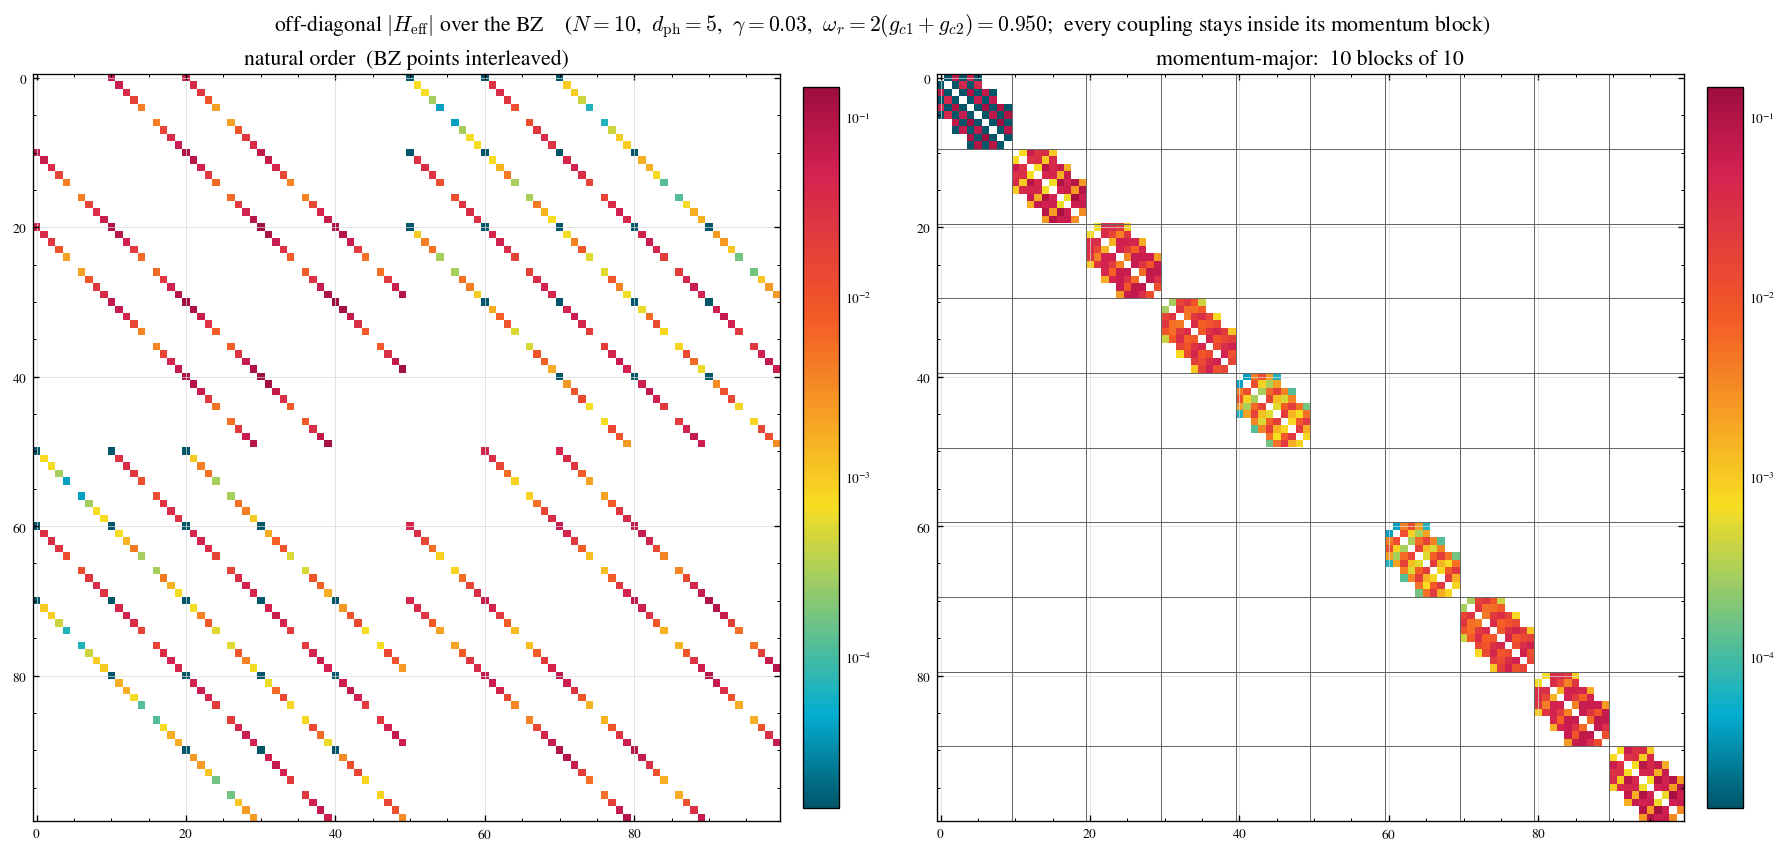

In [28]:
# --- particle-conserving H_eff: momentum block-diagonality  (plot) ----------
# off-diagonal magnitude only (the ~5-scale diagonal energies would swamp the
# tiny inter-state couplings, which is where the block structure actually lives)
from matplotlib.colors import LogNorm

def strip_diagonal(matrix):
    off_diagonal = np.abs(matrix).copy()
    np.fill_diagonal(off_diagonal, 0.0)
    return off_diagonal

natural_offdiag, blockdiag_offdiag = strip_diagonal(natural_order), strip_diagonal(block_diagonal)
color_max = blockdiag_offdiag.max()
color_norm = LogNorm(color_max * 1e-4, color_max)

fig, axs = plt.subplots(1, 2, figsize=(15, 7), constrained_layout=True)
for ax, matrix, title in [(axs[0], natural_offdiag,   "natural order  (BZ points interleaved)"),
                          (axs[1], blockdiag_offdiag, rf"momentum-major:  {num_k} blocks of {block_dim}")]:
    image = ax.imshow(np.where(matrix > 0, matrix, np.nan), cmap="thesis_cmap", norm=color_norm)
    ax.set_title(title, fontsize=13)
    fig.colorbar(image, ax=ax, fraction=0.046, pad=0.03)
for edge in range(block_dim, block_dim * num_k, block_dim):
    axs[1].axhline(edge - 0.5, color="0.4", lw=0.6)
    axs[1].axvline(edge - 0.5, color="0.4", lw=0.6)
fig.suptitle(rf"off-diagonal $|H_{{\rm eff}}|$ over the BZ    "
             rf"($N={num_cells}$,  $d_{{\rm ph}}={photon_cutoff}$,  $\gamma={gamma_ref}$,  "
             rf"$\omega_r=2(g_{{c1}}+g_{{c2}})={omega_r:.3f}$;  every coupling stays inside its momentum block)",
             fontsize=13)
plt.show()

In [29]:
# --- per-momentum dressed spectra vs k  (data) -----------------------------
k_dense = np.linspace(-np.pi, np.pi, 361)
energies_pairing_dropped = np.array([
    np.linalg.eigvalsh(particle_conserving_block(k, g_cap_intra, g_cap_inter, omega_r, gamma_ref,
                                                 photon_cutoff, include_sw=False)) for k in k_dense])
energies_pairing_sw = np.array([
    np.linalg.eigvalsh(particle_conserving_block(k, g_cap_intra, g_cap_inter, omega_r, gamma_ref,
                                                 photon_cutoff, include_sw=True,
                                                 denom_floor=sw_denom_floor)) for k in k_dense])
energies_discrete_bz = np.array([
    np.linalg.eigvalsh(particle_conserving_block(k, g_cap_intra, g_cap_inter, omega_r, gamma_ref,
                                                 photon_cutoff, include_sw=True,
                                                 denom_floor=sw_denom_floor)) for k in bz_momenta])

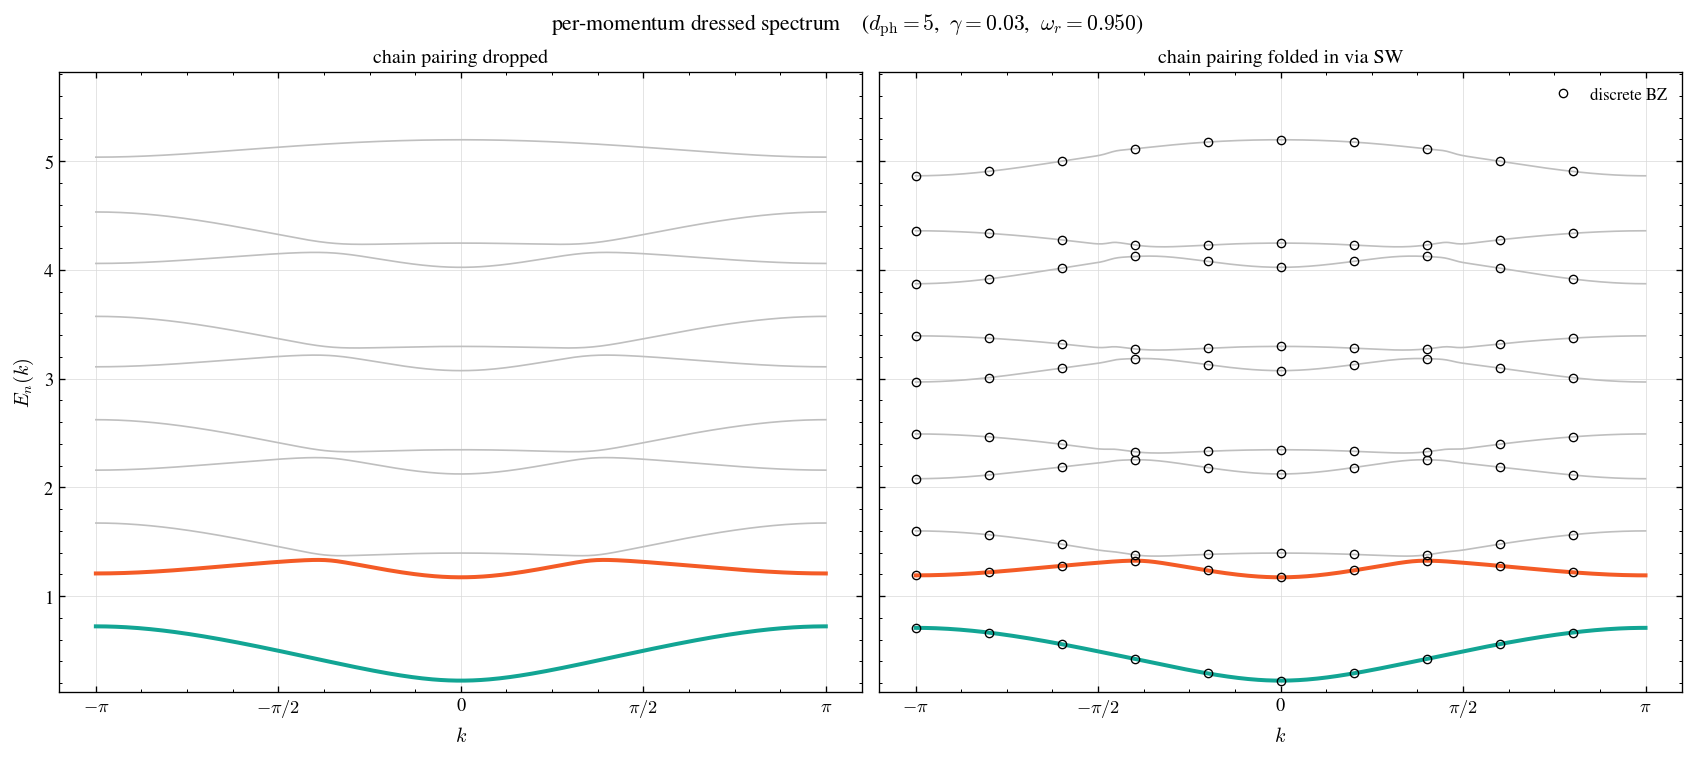

In [30]:
# --- per-momentum dressed spectra vs k  (plot) ----------------------------
fig, axs = plt.subplots(1, 2, figsize=(14, 6.2), sharey=True, constrained_layout=True)
for ax, energies, title in [(axs[0], energies_pairing_dropped, "chain pairing dropped"),
                            (axs[1], energies_pairing_sw,      "chain pairing folded in via SW")]:
    ax.plot(k_dense, energies, color="0.75", lw=1.0)
    ax.plot(k_dense, energies[:, 0], color=ts.COLORS["teal"], lw=2.4)
    ax.plot(k_dense, energies[:, 1], color=ts.COLORS["orange"], lw=2.4)
    ax.set_xlabel(r"$k$", fontsize=12)
    ax.set_title(title, fontsize=12)
    ax.set_xticks([-np.pi, -np.pi / 2, 0, np.pi / 2, np.pi])
    ax.set_xticklabels([r"$-\pi$", r"$-\pi/2$", "0", r"$\pi/2$", r"$\pi$"])
    ax.tick_params(labelsize=11)
axs[1].plot(np.repeat(bz_momenta, 2 * photon_cutoff), energies_discrete_bz.ravel(),
            "o", mfc="none", mec="k", ms=5, lw=0, label="discrete BZ")
axs[1].legend(fontsize=10)
axs[0].set_ylabel(r"$E_n(k)$", fontsize=12)
lowest = min(energies_pairing_dropped[:, 0].min(), energies_pairing_sw[:, 0].min()) - 0.1
axs[0].set_ylim(lowest, lowest + 6 * omega_r)               # doublet + a few photon-ladder rungs
fig.suptitle(rf"per-momentum dressed spectrum    "
             rf"($d_{{\rm ph}}={photon_cutoff}$,  $\gamma={gamma_ref}$,  $\omega_r={omega_r:.3f}$)", fontsize=13)
ts.finalize(axs)
plt.show()

## The two bands as a two-level system: connected Fock space at one $k$

Fock states are triples $(n_{\rm res},n_\alpha,n_\beta)$. Take
$|g\rangle=(0,1,0)=|\alpha_k,0\rangle$ and $|e\rangle=(1,0,1)=|\beta_k,1\rangle$; at the interband
resonance $\omega_r=\omega_{k\alpha}-\omega_{k\beta}$ they are degenerate and
$-\gamma(a+a^\dagger)\otimes M$ opens a Jaynes-Cummings anticrossing between them. Within the
particle-conserving Hamiltonian the matter sector stays at $n_\alpha+n_\beta=1$, so the states
these two connect to are the rest of the photon ladder $\{|\alpha_k,n\rangle,|\beta_k,n\rangle\}$
- a $2d_{\rm ph}$ space. Reorder it as $[\,|g\rangle,|e\rangle,\ \text{rest}\,]$ and split

$$H=\begin{pmatrix}H_{PP}&H_{PQ}\\ H_{QP}&H_{QQ}\end{pmatrix},\qquad P=\{|g\rangle,|e\rangle\}.$$

In [32]:
# --- single k: Fock states connected to (0,1,0) and (1,0,1); P/Q split  (data) -
resonant_bloch_mag = 0.5 * omega_r * np.sqrt(1 - omega_r ** 2 / 4)
resonant_momentum = np.arccos(np.clip(
    (resonant_bloch_mag ** 2 - g_cap_intra ** 2 - g_cap_inter ** 2)
    / (2 * g_cap_intra * g_cap_inter), -1, 1))
nearest_bz_momentum = float(bz_momenta[np.argmin(np.abs(bz_momenta - resonant_momentum))])
print(f"omega_r = {omega_r:.4f},  interband-resonant k* = {resonant_momentum:.4f},  "
      f"nearest BZ point k0 = {nearest_bz_momentum:.4f}\n")

photon_cutoff_tls = 6
H_eff = particle_conserving_block(nearest_bz_momentum, g_cap_intra, g_cap_inter, omega_r,
                                  gamma_ref, photon_cutoff_tls, include_sw=True, denom_floor=sw_denom_floor)
fock_triples = [(n, 1, 0) if s == 0 else (n, 0, 1)          # (n_res, n_alpha, n_beta)
                for n in range(photon_cutoff_tls) for s in (0, 1)]
target_indices = [fock_triples.index((0, 1, 0)), fock_triples.index((1, 0, 1))]

coupling_graph = np.abs(H_eff) > 1e-12                      # nonzero-coupling graph
reached, queue = set(target_indices), list(target_indices)
while queue:
    for j in np.where(coupling_graph[queue.pop()])[0]:
        if j not in reached:
            reached.add(j); queue.append(int(j))
connected_indices = sorted(reached)
print(f"connected Fock states: {len(connected_indices)} of {2 * photon_cutoff_tls}  "
      f"({'the whole photon ladder' if len(connected_indices) == 2 * photon_cutoff_tls else [fock_triples[i] for i in connected_indices]})")

reordered = target_indices + [i for i in connected_indices if i not in target_indices]  # [ |g>, |e>, spectators ]
H_reordered = H_eff[np.ix_(reordered, reordered)]
triple_labels = [str(fock_triples[i]) for i in reordered]
H_PP, H_QQ, H_PQ = H_reordered[:2, :2], H_reordered[2:, 2:], H_reordered[:2, 2:]
print("\nH_PP  (|g> = (0,1,0),  |e> = (1,0,1)):")
print(np.round(H_PP, 5))
print(f"bare doublet gap  |E_e - E_g|   = {np.ptp(np.linalg.eigvalsh(H_PP)):.5e}")
print(f"detuning  H_PP[1,1] - H_PP[0,0] = {(H_PP[1, 1] - H_PP[0, 0]).real:+.2e}   (0 at exact resonance)")
print(f"||H_PQ||  (doublet <-> {H_QQ.shape[0]} spectators) = {np.linalg.norm(H_PQ):.3e}")

omega_r = 0.9500,  interband-resonant k* = 1.1611,  nearest BZ point k0 = 1.2566

connected Fock states: 12 of 12  (the whole photon ladder)

H_PP  (|g> = (0,1,0),  |e> = (1,0,1)):
[[1.3448+0.j     0.    -0.0251j]
 [0.    +0.0251j 1.3625+0.j    ]]
bare doublet gap  |E_e - E_g|   = 5.33348e-02
detuning  H_PP[1,1] - H_PP[0,0] = +1.77e-02   (0 at exact resonance)
||H_PQ||  (doublet <-> 10 spectators) = 4.425e-02


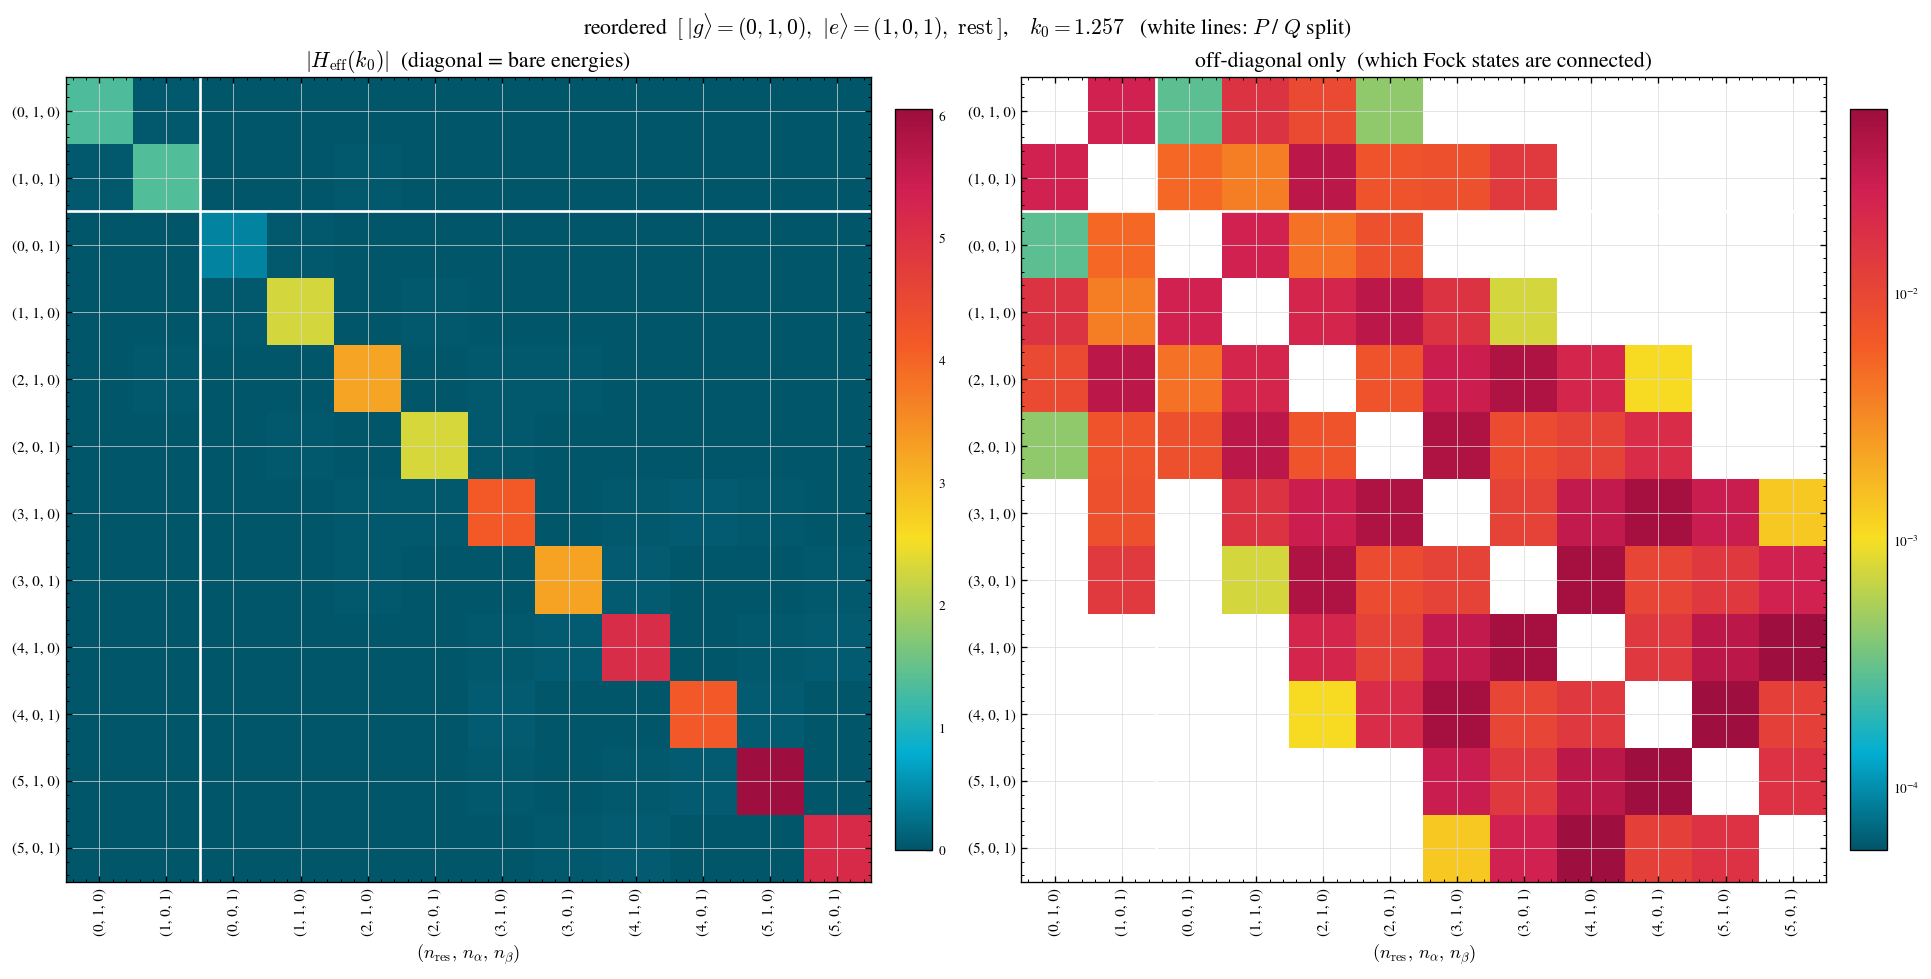

In [ ]:
# --- single k: |H_eff(k0)| reordered [ |g>, |e>, rest ]  (plot) ------------
from matplotlib.colors import LogNorm

H_reordered_offdiag = np.abs(H_reordered).copy()
np.fill_diagonal(H_reordered_offdiag, 0.0)

fig, axs = plt.subplots(1, 2, figsize=(16, 8), constrained_layout=True)
image_full = axs[0].imshow(np.abs(H_reordered), cmap="thesis_cmap")
axs[0].set_title(r"$|H_{\rm eff}(k_0)|$  (diagonal = bare energies)", fontsize=13)
fig.colorbar(image_full, ax=axs[0], fraction=0.046, pad=0.03)

image_offdiag = axs[1].imshow(np.where(H_reordered_offdiag > 0, H_reordered_offdiag, np.nan),
                              cmap="thesis_cmap",
                              norm=LogNorm(H_reordered_offdiag.max() * 1e-3, H_reordered_offdiag.max()))
axs[1].set_title(r"off-diagonal only  (which Fock states are connected)", fontsize=13)
fig.colorbar(image_offdiag, ax=axs[1], fraction=0.046, pad=0.03)

for ax in axs:
    ax.axhline(1.5, color="w", lw=1.6)
    ax.axvline(1.5, color="w", lw=1.6)
    ax.set_xticks(range(len(reordered)))
    ax.set_yticks(range(len(reordered)))
    ax.set_xticklabels(triple_labels, fontsize=9, rotation=90)
    ax.set_yticklabels(triple_labels, fontsize=9)
    ax.set_xlabel(r"$(n_{\rm res},\,n_\alpha,\,n_\beta)$", fontsize=11)
fig.suptitle(rf"reordered  $[\,|g\rangle=(0,1,0),\ |e\rangle=(1,0,1),\ \mathrm{{rest}}\,]$,    "
             rf"$k_0={nearest_bz_momentum:.3f}$   (white lines: $P$ / $Q$ split)", fontsize=13)
plt.show()

## Schrieffer-Wolff downfolding onto the doublet, and the gap

Diagonalise the two diagonal blocks first,
$H_{PP}=U_P\,\mathrm{diag}(\epsilon_P)\,U_P^\dagger$ and
$H_{QQ}=U_Q\,\mathrm{diag}(\epsilon_Q)\,U_Q^\dagger$, and rotate the coupling into those
eigenbases, $\tilde V=U_P^\dagger H_{PQ}U_Q$ (a $2\times(n-2)$ rectangular block connecting the
subspaces). The 2nd-order SW correction to the doublet is then diagonal-denominator trivial,

$$[\delta H]_{ab}=\tfrac12\sum_l \tilde V_{al}\,\overline{\tilde V_{bl}}
\left(\frac{1}{\epsilon_{P,a}-\epsilon_{Q,l}}+\frac{1}{\epsilon_{P,b}-\epsilon_{Q,l}}\right),
\qquad H_{\rm TLS}=U_P\big(\mathrm{diag}(\epsilon_P)+\delta H\big)U_P^\dagger .$$

Three gaps vs $k$: **(a) exact** - the two eigenvalues of the full $2d_{\rm ph}$ block with the
largest weight on $\{|g\rangle,|e\rangle\}$; **(b) bare** $H_{PP}$; **(c)** $H_{\rm TLS}$.

In [33]:
# --- SW downfolding onto the doublet: definitions + gap sweep  (data) ------
def sw_downfold(hamiltonian, target_indices, denom_floor=1e-9):
    """2x2 effective doublet: diagonalise H_PP and H_QQ, rotate the coupling into
    those eigenbases (coupling_in_eigenbasis), then the diagonal-denominator 2nd-order shift."""
    spectator_indices = [i for i in range(hamiltonian.shape[0]) if i not in target_indices]
    energies_P, basis_P = np.linalg.eigh(hamiltonian[np.ix_(target_indices, target_indices)])
    energies_Q, basis_Q = np.linalg.eigh(hamiltonian[np.ix_(spectator_indices, spectator_indices)])
    coupling_in_eigenbasis = (basis_P.conj().T
                              @ hamiltonian[np.ix_(target_indices, spectator_indices)]
                              @ basis_Q)                     # 2 x (n-2), connects the subspaces
    energy_denominator = energies_P[:, None] - energies_Q[None, :]
    resolvent = np.where(np.abs(energy_denominator) > denom_floor,
                         1.0 / np.where(np.abs(energy_denominator) > denom_floor, energy_denominator, 1.0), 0.0)
    second_order = (coupling_in_eigenbasis * resolvent) @ coupling_in_eigenbasis.conj().T
    return basis_P @ (np.diag(energies_P) + 0.5 * (second_order + second_order.conj().T)) @ basis_P.conj().T


def three_gaps(k, g_cap_intra, g_cap_inter, omega_r, gamma,
               photon_cutoff=6, qp_fock_cutoff=4, denom_floor=sw_denom_floor):
    H_eff = particle_conserving_block(k, g_cap_intra, g_cap_inter, omega_r, gamma,
                                      photon_cutoff, include_sw=True,
                                      qp_fock_cutoff=qp_fock_cutoff, denom_floor=denom_floor)
    triples = [(n, 1, 0) if s == 0 else (n, 0, 1) for n in range(photon_cutoff) for s in (0, 1)]
    doublet = [triples.index((0, 1, 0)), triples.index((1, 0, 1))]
    eigenvalues, eigenvectors = np.linalg.eigh(H_eff)
    doublet_weight = (np.abs(eigenvectors[doublet, :]) ** 2).sum(0)
    top_two = np.argsort(doublet_weight)[-2:]                # 2 eigenvectors most on the doublet
    gap_exact = np.ptp(eigenvalues[top_two]) if doublet_weight[top_two].min() > 0.7 else np.nan
    return (gap_exact,
            np.ptp(np.linalg.eigvalsh(H_eff[np.ix_(doublet, doublet)])),
            np.ptp(np.linalg.eigvalsh(sw_downfold(H_eff, doublet))))


_H_eff = particle_conserving_block(nearest_bz_momentum, g_cap_intra, g_cap_inter, omega_r,
                                   gamma_ref, 6, include_sw=True, denom_floor=sw_denom_floor)
_doublet = [0, 3]
_spectators = [i for i in range(12) if i not in (0, 3)]
_energies_P = np.linalg.eigvalsh(_H_eff[np.ix_(_doublet, _doublet)])
_energies_Q = np.linalg.eigvalsh(_H_eff[np.ix_(_spectators, _spectators)])
print(f"k0 = {nearest_bz_momentum:.3f}:  eps_P = {np.round(_energies_P, 4)}   "
      f"min|eps_P - eps_Q| = {np.abs(_energies_P[:, None] - _energies_Q[None, :]).min():.3f}   "
      f"(SW denominators, safely nonzero)")

k_values = np.linspace(0.06, np.pi - 0.02, 221)
gamma_values = [0.015, 0.03, 0.05]
gaps_by_gamma = [np.array([three_gaps(k, g_cap_intra, g_cap_inter, omega_r, gamma) for k in k_values])
                 for gamma in gamma_values]

k0 = 1.257:  eps_P = [1.327  1.3803]   min|eps_P - eps_Q| = 0.874   (SW denominators, safely nonzero)


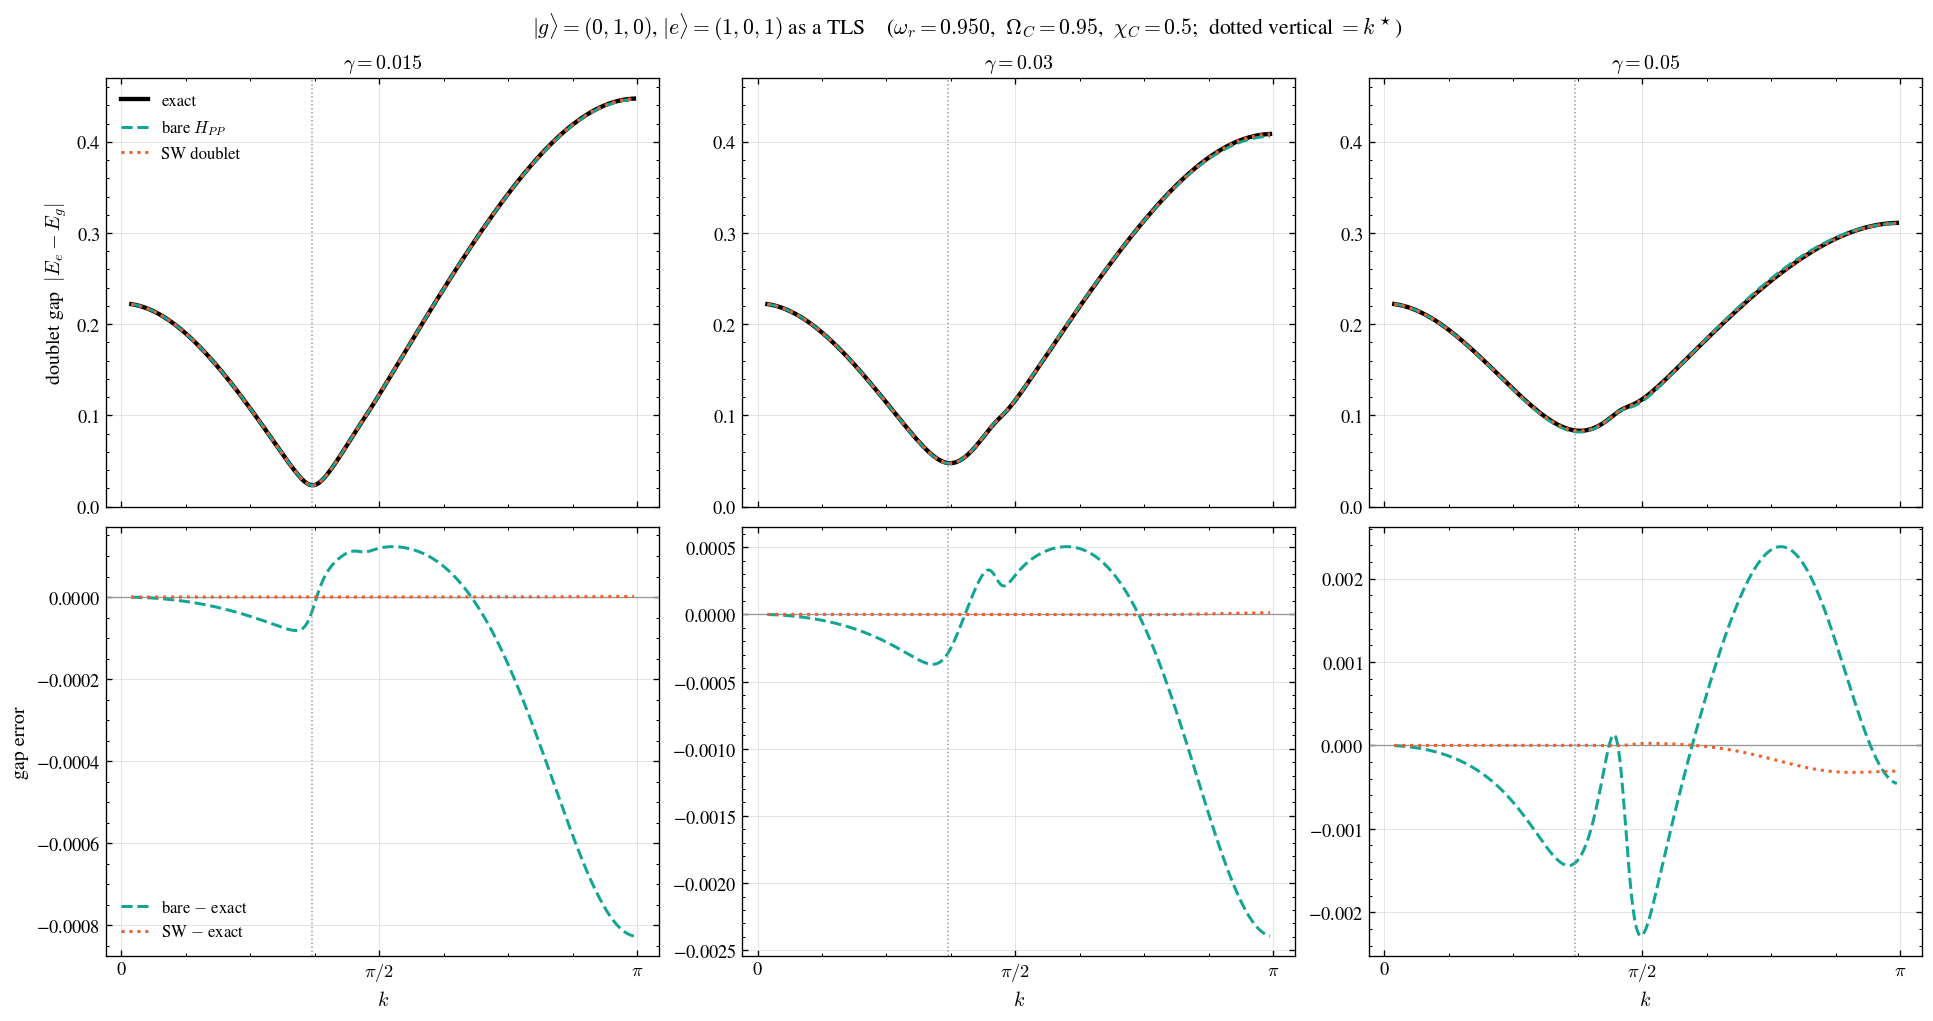

In [34]:
# --- three doublet gaps vs k, per gamma  (plot) --------------------------
gap_ceiling = 1.05 * max(np.nanmax(gaps[:, :3]) for gaps in gaps_by_gamma)
fig, axs = plt.subplots(2, 3, figsize=(16, 8.4), sharex=True, constrained_layout=True)
for col, (gamma, gaps) in enumerate(zip(gamma_values, gaps_by_gamma)):
    top, bottom = axs[0, col], axs[1, col]
    top.plot(k_values, gaps[:, 0], color="k", lw=2.6, label="exact")
    top.plot(k_values, gaps[:, 1], color=ts.COLORS["teal"], lw=1.8, ls="--", label=r"bare $H_{PP}$")
    top.plot(k_values, gaps[:, 2], color=ts.COLORS["orange"], lw=1.8, ls=":", label="SW doublet")
    top.set_ylim(0, gap_ceiling)
    top.set_title(rf"$\gamma = {gamma}$", fontsize=12)

    bottom.axhline(0, color="0.6", lw=0.8)
    bottom.plot(k_values, gaps[:, 1] - gaps[:, 0], color=ts.COLORS["teal"], lw=1.8, ls="--",
                label=r"bare $-$ exact")
    bottom.plot(k_values, gaps[:, 2] - gaps[:, 0], color=ts.COLORS["orange"], lw=1.8, ls=":",
                label=r"SW $-$ exact")
    bottom.set_xlabel(r"$k$", fontsize=12)

    for ax in (top, bottom):
        ax.axvline(resonant_momentum, color="0.6", lw=0.9, ls=":")
        ax.set_xticks([0, np.pi / 2, np.pi])
        ax.set_xticklabels(["0", r"$\pi/2$", r"$\pi$"])
        ax.tick_params(labelsize=11)
axs[0, 0].set_ylabel(r"doublet gap  $|E_e - E_g|$", fontsize=12)
axs[1, 0].set_ylabel(r"gap error", fontsize=12)
axs[0, 0].legend(fontsize=10, loc="upper left")
axs[1, 0].legend(fontsize=10, loc="lower left")
fig.suptitle(rf"$|g\rangle=(0,1,0)$, $|e\rangle=(1,0,1)$ as a TLS    "
             rf"($\omega_r={omega_r:.3f}$,  $\Omega_C={Omega_C}$,  $\chi_C={Chi_C}$;  "
             rf"dotted vertical $=k^\star$)", fontsize=13)
ts.finalize(axs)
plt.show()

In [35]:
# --- TLS-reduction error: vs gamma at k*, and vs the other knobs  (data) --
gamma_sweep = np.logspace(-2.4, -1.05, 18)
errors = np.array([[abs(bare - exact), abs(sw - exact)]
                   for exact, bare, sw in (three_gaps(nearest_bz_momentum, g_cap_intra, g_cap_inter,
                                                      omega_r, gamma) for gamma in gamma_sweep)])
loglog_slope = lambda errs: np.log(errs[2] / errs[0]) / np.log(gamma_sweep[2] / gamma_sweep[0])
print(f"at k0 = {nearest_bz_momentum:.3f}  (log-log slope near gamma -> 0):"
      f"   |bare - exact| ~ gamma^{loglog_slope(errors[:, 0]):.2f}"
      f"      |SW - exact| ~ gamma^{loglog_slope(errors[:, 1]):.2f}\n")

print(f"{'Omega_C':>8} {'Chi_C':>7} {'omega_r':>9} {'gap_exact':>12} {'bare err':>11} {'SW err':>11}")
for Omega_C_val, Chi_C_val, omega_r_factor in [(Omega_C, Chi_C, 1.0), (0.60, 0.50, 1.0),
                                               (0.95, 0.80, 1.0), (0.95, 0.50, 0.85),
                                               (0.95, 0.50, 1.15)]:
    g_cap_intra_val = 0.25 * Omega_C_val * (1 + Chi_C_val)
    g_cap_inter_val = 0.25 * Omega_C_val * (1 - Chi_C_val)
    omega_r_val = omega_r_factor * 2 * (g_cap_intra_val + g_cap_inter_val)
    resonant_bloch_mag_val = 0.5 * omega_r_val * np.sqrt(1 - omega_r_val ** 2 / 4)
    resonant_momentum_val = np.arccos(np.clip(
        (resonant_bloch_mag_val ** 2 - g_cap_intra_val ** 2 - g_cap_inter_val ** 2)
        / (2 * g_cap_intra_val * g_cap_inter_val), -1, 1))
    exact, bare, sw = three_gaps(resonant_momentum_val, g_cap_intra_val, g_cap_inter_val,
                                 omega_r_val, gamma_ref)
    print(f"{Omega_C_val:8.2f} {Chi_C_val:+7.2f} {omega_r_val:9.4f} {exact:12.3e} "
          f"{abs(bare - exact):11.2e} {abs(sw - exact):11.2e}")

at k0 = 1.257  (log-log slope near gamma -> 0):   |bare - exact| ~ gamma^1.89      |SW - exact| ~ gamma^3.91

 Omega_C   Chi_C   omega_r    gap_exact    bare err      SW err
    0.95   +0.50    0.9500    4.768e-02    2.86e-04    1.40e-07
    0.60   +0.50    0.6000    3.757e-02    2.22e-04    1.31e-07
    0.95   +0.80    0.9500    4.894e-02    5.52e-04    2.78e-06
    0.95   +0.50    0.8075    6.823e-02    1.14e-03    2.67e-06
    0.95   +0.50    1.0925    2.362e-02    5.10e-05    3.65e-09


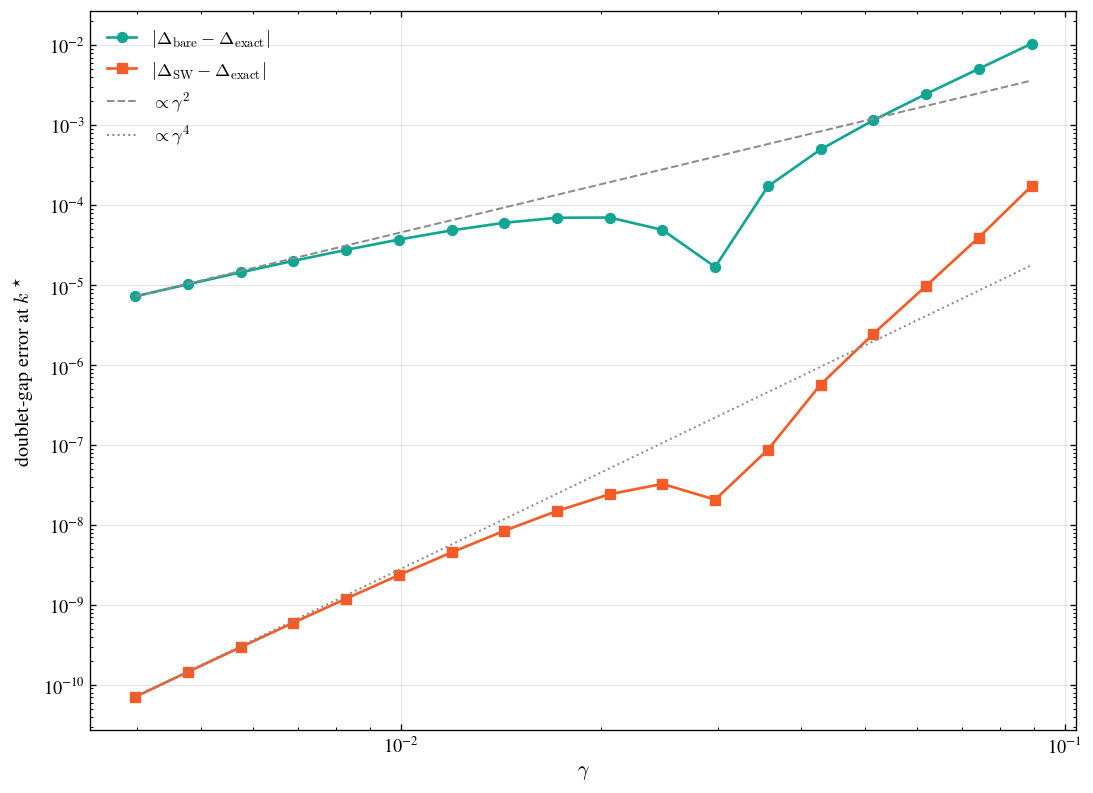

In [36]:
# --- TLS-reduction error vs gamma at k*  (plot) -------------------------
fig, ax = plt.subplots(figsize=(9, 6.5), constrained_layout=True)
ax.loglog(gamma_sweep, errors[:, 0], "o-", color=ts.COLORS["teal"], ms=6, lw=1.6,
          label=r"$|\Delta_{\rm bare} - \Delta_{\rm exact}|$")
ax.loglog(gamma_sweep, errors[:, 1], "s-", color=ts.COLORS["orange"], ms=6, lw=1.6,
          label=r"$|\Delta_{\rm SW} - \Delta_{\rm exact}|$")
ax.loglog(gamma_sweep, errors[0, 0] * (gamma_sweep / gamma_sweep[0]) ** 2, "--", color="0.55", lw=1.2,
          label=r"$\propto \gamma^2$")
ax.loglog(gamma_sweep, errors[0, 1] * (gamma_sweep / gamma_sweep[0]) ** 4, ":", color="0.55", lw=1.2,
          label=r"$\propto \gamma^4$")
ax.set_xlabel(r"$\gamma$", fontsize=12)
ax.set_ylabel(r"doublet-gap error at $k^\star$", fontsize=12)
ax.tick_params(labelsize=11)
ax.legend(fontsize=11)
ts.finalize(ax)
plt.show()

## Analytic coefficients of the transformed $H_J$ (symbolic)

Redo the $H_C$-diagonalising transform $T = T_{\rm rot}\,T_{\rm sq}$ (phased sublattice
rotation into $\alpha_k/\beta_k$, then the two-mode squeeze) with `sympy`, apply it to
$H_J$, and read off closed forms for every entry of $\tilde{\mathcal A}_J$ (number,
QP gauge) and $\tilde{\mathcal B}_J$ (pairing).  Same derivation as the Mathematica
notebook `hj_analytic_coefficients.nb`.  Fundamental symbols: $ad=|\delta_{C,k}|$
$(0<ad<\tfrac12)$, $\varphi=\arg\delta_{C,k}$, $\delta_J=\delta_{J,k}$ (generic complex),
$g_J=g_{J1}+g_{J2}$; the bands are $w_\alpha^2 = 1+2\,ad$, $w_\beta^2 = 1-2\,ad$.

In [37]:
import sympy as sp
from sympy import I, exp, sqrt, Rational, conjugate, simplify, symbols, Matrix, zeros, diag

ad = symbols('ad', positive=True)               # |delta_C,k| ,  0 < ad < 1/2
ph = symbols('varphi', real=True)               # arg delta_C,k
gJ = symbols('g_J', real=True)                   # g_J1 + g_J2
dJ = symbols('delta_J'); dJc = conjugate(dJ)     # delta_J,k  (generic complex)
w_alpha, w_beta = symbols('w_alpha w_beta', positive=True)   # w_alpha^2 = 1+2ad, w_beta^2 = 1-2ad
band_sub = {w_alpha: sqrt(1 + 2*ad), w_beta: sqrt(1 - 2*ad)}
dCk, dCkc = ad*exp(I*ph), ad*exp(-I*ph)

# --- the 8x8 sector Nambu blocks (honest 1/2 convention, transcribed from sector_nambu) ---
def sector_from_bloch(on_site, bloch, bloch_conj):
    return diag(Matrix([[on_site, bloch], [bloch_conj, on_site]]),
                Matrix([[on_site, bloch_conj], [bloch, on_site]]))

cap_normal  = Rational(1, 2) * sector_from_bloch(1, dCk, dCkc)
cap_pairing = zeros(4)
cap_pairing[0, 3] = cap_pairing[3, 0] = -dCk/2
cap_pairing[1, 2] = cap_pairing[2, 1] = -dCkc/2
HC_sym = Matrix(sp.BlockMatrix([[cap_normal, cap_pairing],
                                [cap_pairing.conjugate(), cap_normal.conjugate()]]))

joseph_normal  = Rational(1, 2) * sector_from_bloch(gJ, -dJ, -dJc)
joseph_pairing = zeros(4)
joseph_pairing[0, 2] = joseph_pairing[2, 0] = joseph_pairing[1, 3] = joseph_pairing[3, 1] = -gJ/2
joseph_pairing[0, 3] = joseph_pairing[3, 0] = -dJ/2
joseph_pairing[1, 2] = joseph_pairing[2, 1] = -dJc/2
HJ_sym = Matrix(sp.BlockMatrix([[joseph_normal, joseph_pairing],
                                [joseph_pairing.conjugate(), joseph_normal.conjugate()]]))

# --- T = T_rot . T_sq ---
eh, ehc = exp(I*ph/2), exp(-I*ph/2)
rot4 = diag((1/sqrt(2))*Matrix([[ehc, eh], [ehc, -eh]]),      # rows = alpha_k, beta_k
            (1/sqrt(2))*Matrix([[eh, ehc], [eh, -ehc]]))       # rows = alpha_-k, beta_-k
rot_inv = simplify(rot4.inv())
T_rot = Matrix(sp.BlockMatrix([[rot_inv, zeros(4)], [zeros(4), rot_inv.conjugate()]]))

chA, shA = (sqrt(w_alpha) + 1/sqrt(w_alpha))/2, (sqrt(w_alpha) - 1/sqrt(w_alpha))/2
chB, shB = (sqrt(w_beta)  + 1/sqrt(w_beta))/2,  (sqrt(w_beta)  - 1/sqrt(w_beta))/2
U4 = diag(chA, chB, chA, chB)
V4 = zeros(4); V4[0, 2] = V4[2, 0] = shA; V4[1, 3] = V4[3, 1] = shB
T_sq = Matrix(sp.BlockMatrix([[U4, V4], [V4, U4]]))

T_sym = sp.expand(T_rot * T_sq)
tau3  = diag(1, 1, 1, 1, -1, -1, -1, -1)
print("built HC_sym, HJ_sym (8x8) and the paraunitary transform T_sym")

built HC_sym, HJ_sym (8x8) and the paraunitary transform T_sym


In [38]:
# T is paraunitary
print("T^dag tau3 T - tau3 is the zero matrix:",
      simplify(T_sym.conjugate().T @ tau3 @ T_sym - tau3).is_zero_matrix)

# T diagonalises H_C: check off-diagonal numerically, then read the bands
HCd_sym = T_sym.conjugate().T @ HC_sym @ T_sym
_pt = {ad: 0.31, ph: 0.4, gJ: 0.5, dJ: 0.6 + 0.3j,
       w_alpha: (1 + 2*0.31)**0.5, w_beta: (1 - 2*0.31)**0.5}
HCd_num = np.array(HCd_sym.subs(_pt).evalf(), dtype=complex)
print("H_Cd off-diagonal magnitude at a sample point:",
      np.abs(HCd_num - np.diag(np.diag(HCd_num))).max())
print("physical bands  2*diag(H_Cd)[:2] =",
      [sp.simplify((2*HCd_sym[i, i]).subs(band_sub)) for i in range(2)],
      "  ( = sqrt(1 +/- 2 ad) )")

T^dag tau3 T - tau3 is the zero matrix: True
H_Cd off-diagonal magnitude at a sample point: 1.3877787807814457e-17
physical bands  2*diag(H_Cd)[:2] = [sqrt(2*ad + 1), sqrt(1 - 2*ad)]   ( = sqrt(1 +/- 2 ad) )


In [39]:
HJd_sym = T_sym.conjugate().T @ HJ_sym @ T_sym
A_J_sym = sp.Matrix(2 * HJd_sym[:4, :4])      # physical number block   \tilde A_J  (alpha_k, beta_k, alpha_-k, beta_-k)
B_J_sym = sp.Matrix(2 * HJd_sym[:4, 4:])      # physical pairing block  \tilde B_J

cf = lambda e: sp.factor(sp.simplify(e))
coeffs = {
    "A_J[alpha_k, alpha_k]"                       : cf(A_J_sym[0, 0]),
    "A_J[beta_k,  beta_k]"                        : cf(A_J_sym[1, 1]),
    "A_J[alpha_k, beta_k]   (interband, same k)"  : cf(A_J_sym[0, 1]),
    "A_J[alpha_k, {alpha,beta}_-k]  (should be 0)"       : [sp.simplify(A_J_sym[0, 2]), sp.simplify(A_J_sym[0, 3])],
    "B_J[alpha_k, alpha_-k] (zero-momentum pair)" : cf(B_J_sym[0, 2]),
    "B_J[alpha_k, beta_-k]  (zero-momentum pair)" : cf(B_J_sym[0, 3]),
    "B_J[beta_k,  beta_-k]  (zero-momentum pair)" : cf(B_J_sym[1, 3]),
    "B_J[alpha_k, {alpha_k,beta_k}]  (should be 0)"      : [sp.simplify(B_J_sym[0, 0]), sp.simplify(B_J_sym[0, 1])],
}
for name, val in coeffs.items():
    print(f"{name:44s} = {val}")
print("\nA_J[alpha_k, beta_k] == B_J[alpha_k, beta_-k] :",
      sp.simplify(A_J_sym[0, 1] - B_J_sym[0, 3]) == 0)
print("=> A_J is momentum-block-diagonal, B_J momentum-block-anti-diagonal (Step 9b).")

A_J[alpha_k, alpha_k]                        = -(delta_J*w_alpha**2 - 2*g_J*exp(I*varphi) + w_alpha**2*exp(2*I*varphi)*conjugate(delta_J))*exp(-I*varphi)/(2*w_alpha)
A_J[beta_k,  beta_k]                         = (delta_J*w_beta**2 + 2*g_J*exp(I*varphi) + w_beta**2*exp(2*I*varphi)*conjugate(delta_J))*exp(-I*varphi)/(2*w_beta)
A_J[alpha_k, beta_k]   (interband, same k)   = -sqrt(w_alpha)*sqrt(w_beta)*(-delta_J + exp(2*I*varphi)*conjugate(delta_J))*exp(-I*varphi)/2
A_J[alpha_k, {alpha,beta}_-k]  (should be 0) = [0, 0]
B_J[alpha_k, alpha_-k] (zero-momentum pair)  = -(delta_J*w_alpha**2 + 2*g_J*exp(I*varphi) + w_alpha**2*exp(2*I*varphi)*conjugate(delta_J))*exp(-I*varphi)/(2*w_alpha)
B_J[alpha_k, beta_-k]  (zero-momentum pair)  = -sqrt(w_alpha)*sqrt(w_beta)*(-delta_J + exp(2*I*varphi)*conjugate(delta_J))*exp(-I*varphi)/2
B_J[beta_k,  beta_-k]  (zero-momentum pair)  = (delta_J*w_beta**2 - 2*g_J*exp(I*varphi) + w_beta**2*exp(2*I*varphi)*conjugate(delta_J))*exp(-I*varphi)/(2*w_beta)
B_J[alpha_

In [40]:
# --- write the coefficients down (rendered from A_J_sym / B_J_sym) -----------
from IPython.display import display, Math
import sympy as sp

def _show(lhs, expr):
    display(Math(lhs + " = " + sp.latex(sp.simplify(expr))))
    display(Math(r"\qquad = " + sp.latex(sp.simplify(sp.simplify(expr).subs(band_sub)))
                 + r"\quad\text{(explicit in } ad=|\delta_{C,k}|\text{)}"))

print("physical  \\tilde H_J  in the QP gauge   "
      "( w_alpha^2 = 1 + 2 ad ,  w_beta^2 = 1 - 2 ad ):\n")
_show(r"\tilde{\mathcal{A}}_J[\alpha_k,\alpha_k]",   A_J_sym[0, 0])
_show(r"\tilde{\mathcal{A}}_J[\beta_k,\beta_k]",     A_J_sym[1, 1])
_show(r"\tilde{\mathcal{A}}_J[\alpha_k,\beta_k]",    A_J_sym[0, 1])
_show(r"\tilde{\mathcal{B}}_J[\alpha_k,\alpha_{-k}]", B_J_sym[0, 2])
_show(r"\tilde{\mathcal{B}}_J[\alpha_k,\beta_{-k}]",  B_J_sym[0, 3])
_show(r"\tilde{\mathcal{B}}_J[\beta_k,\beta_{-k}]",   B_J_sym[1, 3])
display(Math(r"\tilde{\mathcal{A}}_J[\alpha_k,\{\alpha,\beta\}_{-k}] = 0"
             r"\qquad\tilde{\mathcal{B}}_J[\alpha_k,\{\alpha_k,\beta_k\}] = 0"))

physical  \tilde H_J  in the QP gauge   ( w_alpha^2 = 1 + 2 ad ,  w_beta^2 = 1 - 2 ad ):



<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

...

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

### The closed forms

With $\delta_{J,k}=g_{J1}+g_{J2}e^{-ik}$, $\varphi=\arg\delta_{C,k}$, $g_J=g_{J1}+g_{J2}$
and the bands $w_{\alpha,\beta}=\sqrt{1\pm 2|\delta_{C,k}|}$, the transform
$T=T_{\rm rot}T_{\rm sq}$ takes the Josephson block to (physical convention, QP basis
$\alpha_k,\beta_k,\alpha_{-k},\beta_{-k}$):

$$\tilde{\mathcal A}_J[\alpha_k,\alpha_k]
 =-\tfrac{w_\alpha}{2}e^{-i\varphi}\delta_{J,k}+\tfrac{g_J}{w_\alpha}
   -\tfrac{w_\alpha}{2}e^{i\varphi}\bar\delta_{J,k},\qquad
  \tilde{\mathcal A}_J[\beta_k,\beta_k]
 =\tfrac{w_\beta}{2}e^{-i\varphi}\delta_{J,k}+\tfrac{g_J}{w_\beta}
   +\tfrac{w_\beta}{2}e^{i\varphi}\bar\delta_{J,k}$$

$$\boxed{\ \tilde{\mathcal A}_J[\alpha_k,\beta_k]
        =\tilde{\mathcal B}_J[\alpha_k,\beta_{-k}]
        =\frac{(1-4|\delta_{C,k}|^2)^{1/4}}{2}\,e^{-i\varphi}
         \big(\delta_{J,k}-e^{2i\varphi}\,\bar\delta_{J,k}\big)\ }$$

$$\tilde{\mathcal B}_J[\alpha_k,\alpha_{-k}]
 =-\tfrac{w_\alpha}{2}e^{-i\varphi}\delta_{J,k}-\tfrac{g_J}{w_\alpha}
   -\tfrac{w_\alpha}{2}e^{i\varphi}\bar\delta_{J,k},\qquad
  \tilde{\mathcal B}_J[\beta_k,\beta_{-k}]
 =\tfrac{w_\beta}{2}e^{-i\varphi}\delta_{J,k}-\tfrac{g_J}{w_\beta}
   +\tfrac{w_\beta}{2}e^{i\varphi}\bar\delta_{J,k}$$

$$\tilde{\mathcal A}_J[\alpha_k,\alpha_{-k}]=\tilde{\mathcal A}_J[\alpha_k,\beta_{-k}]=0,
  \qquad
  \tilde{\mathcal B}_J[\alpha_k,\alpha_k]=\tilde{\mathcal B}_J[\alpha_k,\beta_k]=0
  \qquad(\text{Step 9b}).$$

**Readout.**

* The band-diagonal number shift $\tilde{\mathcal A}_J[\gamma_k,\gamma_k]$ and the
  same-mode induced pairing $\tilde{\mathcal B}_J[\gamma_k,\gamma_{-k}]$ differ **only**
  by the sign of the $g_J/w_\gamma$ term.
* The interband number coupling $\tilde{\mathcal A}_J[\alpha_k,\beta_k]$ and the
  $\alpha_k$–$\beta_{-k}$ zero-momentum pair $\tilde{\mathcal B}_J[\alpha_k,\beta_{-k}]$
  carry the **identical** coefficient, $\propto\ \delta_{J,k}-e^{2i\varphi}\bar\delta_{J,k}$.
* That factor vanishes iff $\arg\delta_{J,k}=\varphi=\arg\delta_{C,k}$ (Josephson and
  capacitive Bloch phases aligned) — in particular on $\chi_C=0$, where it is exactly
  the trench seen in the interband ($k$-changing) sweep.

In [41]:
# --- cross-check the closed forms against the implemented procedure ---
test_points = [                       # (k, gc1, gc2, gJ1, gJ2),  gc1 + gc2 < 1/2
    (0.70, 0.18, 0.11, 1.00, -0.50),
    (1.30, 0.24, 0.16, 1.00,  0.00),
    (2.10, 0.20, 0.19, 0.80, -0.30),
    (0.35, 0.34, 0.05, 1.20, -0.70),
    (3.05, 0.15, 0.14, 1.00, -0.20),   # near k = pi (TRIM)
    (0.90, 0.11, 0.30, 0.60, -0.90),   # topological side  gc1 < gc2
    (1.75, 0.30, 0.09, 0.50, -0.50),
    (0.05, 0.20, 0.20, 0.90, -0.10),   # near k = 0 (TRIM),  chi_C = 0
]
lam_A = sp.lambdify((ad, ph, dJ, gJ, w_alpha, w_beta), A_J_sym, "numpy")
lam_B = sp.lambdify((ad, ph, dJ, gJ, w_alpha, w_beta), B_J_sym, "numpy")

print(f"{'k':>6} {'gc1':>6} {'gc2':>6} {'gJ1':>5} {'gJ2':>6}   {'max|d A_J|':>11}  {'max|d B_J|':>11}   side")
for (k, gc1, gc2, gJ1, gJ2) in test_points:
    OmJ, ChiJ = (gJ1 - gJ2)/2, (gJ1 + gJ2)/(gJ1 - gJ2)
    HC_n, HJ_n = sector_nambu_at_k(k, gc1, gc2, OmJ, ChiJ)
    T_n, _ = diagonalize_cap_sector(HC_n, k, gc1, gc2)
    HJd_n = T_n.conj().T @ HJ_n @ T_n
    adv = abs(gc1 + gc2*np.exp(-1j*k)); phv = np.angle(gc1 + gc2*np.exp(-1j*k))
    dJv = gJ1 + gJ2*np.exp(-1j*k); w = (np.sqrt(1 + 2*adv), np.sqrt(1 - 2*adv))
    dA = np.abs(lam_A(adv, phv, dJv, gJ1 + gJ2, *w) - 2*HJd_n[:4, :4]).max()
    dB = np.abs(lam_B(adv, phv, dJv, gJ1 + gJ2, *w) - 2*HJd_n[:4, 4:]).max()
    print(f"{k:6.2f} {gc1:6.2f} {gc2:6.2f} {gJ1:5.1f} {gJ2:6.1f}   {dA:11.2e}  {dB:11.2e}   "
          f"{'trivial' if gc1 > gc2 else 'topological'}")
print("\nall ~1e-15 -> the closed forms match the implemented procedure across the BZ and both sides.")

     k    gc1    gc2   gJ1    gJ2    max|d A_J|   max|d B_J|   side
  0.70   0.18   0.11   1.0   -0.5      6.66e-16     4.48e-16   trivial
  1.30   0.24   0.16   1.0    0.0      8.95e-16     6.67e-16   trivial
  2.10   0.20   0.19   0.8   -0.3      2.78e-16     3.51e-16   trivial
  0.35   0.34   0.05   1.2   -0.7      1.11e-15     6.66e-16   trivial
  3.05   0.15   0.14   1.0   -0.2      6.89e-16     1.53e-16   trivial
  0.90   0.11   0.30   0.6   -0.9      6.66e-16     4.45e-16   topological
  1.75   0.30   0.09   0.5   -0.5      2.24e-16     2.24e-16   trivial
  0.05   0.20   0.20   0.9   -0.1      8.88e-16     6.66e-16   topological

all ~1e-15 -> the closed forms match the implemented procedure across the BZ and both sides.


## The hybridised spinor in a real gauge: does it wind?

The $k$-independent rotation $\sigma_y\to\sigma_x$
($R=\operatorname{diag}(e^{i\pi/4},e^{-i\pi/4})$, a constant relabelling of
$|\alpha_k,0\rangle,\ |\beta_k,1\rangle$) turns the truncated doublet into a
**real symmetric** matrix,

$$H_{\rm TLS}(k)=\begin{pmatrix}\Delta_k/2 & \gamma\rho_k\\[2pt]\gamma\rho_k & -\Delta_k/2\end{pmatrix},
\qquad \Delta_k=\omega_{\alpha,k}-\omega_{\beta,k}-\omega_r,\qquad g_k=i\rho_k .$$

Its lower eigenvector is then real, $c_k=(-\sin\tfrac{\beta_k}{2},\ \cos\tfrac{\beta_k}{2})$
with $\beta_k=\operatorname{atan2}(\gamma\rho_k,\ \Delta_k/2)$, and it points
(anti)parallel to the plane vector $(\gamma\rho_k,\ \Delta_k/2)$. Sweeping $k$ across
the BZ that vector traces a **closed loop**; the loop encircles the origin exactly
when $\beta_k$ winds, i.e. when $\Delta_k$ changes sign somewhere in the zone
($\omega_r$ inside the interband-gap window). Its winding $w_h$ is the cavity
contribution to $\gamma_{\rm Zak}=\pi(w_h-w_C)$; at this notebook's dimerisation
$w_C=0$, so here $\gamma_{\rm Zak}=\pi\,w_h$ and *loop encircles the origin*
$\Leftrightarrow \gamma_{\rm Zak}=\pi$. The cell below draws the loop for $\omega_r$
below, inside ($\times 2$) and above the window.

In [42]:
# --- hybridised spinor: real-gauge pseudo-spin loop vs the Zak phase  (data) -
# After sigma_y -> sigma_x (constant gauge R = diag(e^{i pi/4}, e^{-i pi/4})),
#     H_TLS(k) = [[ Delta_k/2,  gamma rho_k ],
#                 [ gamma rho_k, -Delta_k/2 ]]        (real symmetric)
# with  g_k = (A_J + A_J^dag)[alpha_k, beta_k] = i rho_k ,  rho_k real,
#       Delta_k = omega_alpha(k) - omega_beta(k) - omega_r .
# The real lower eigenvector points along the plane vector (gamma rho_k, Delta_k/2);
# as k sweeps the BZ this vector draws a closed loop whose winding number about the
# origin is  w_h .  With the SSH winding w_C = 0 here,  gamma_Zak = pi w_h , so the
# loop encircles the origin  <=>  gamma_Zak = pi  <=>  omega_r inside the gap window.

gamma_winding = 0.04
num_k_winding = 4000
loop_momenta  = np.linspace(0.0, 2 * np.pi, num_k_winding, endpoint=False)


def real_gauge_pseudospin_loop(momenta, g_cap_intra, g_cap_inter, omega_r, gamma):
    """the plane vector  (spin_x, spin_z) = (gamma rho_k, Delta_k / 2)  along the BZ loop."""
    spin_x = np.empty(len(momenta))
    spin_z = np.empty(len(momenta))
    for index, k in enumerate(momenta):
        H_cap, H_joseph = sector_nambu_at_k(k, g_cap_intra, g_cap_inter, Omega_J, Chi_J)
        transform, H_cap_diag = diagonalize_cap_sector(H_cap, k, g_cap_intra, g_cap_inter)
        H_joseph_qp = transform.conj().T @ H_joseph @ transform
        interband_number = (H_joseph_qp[:2, :2] + H_joseph_qp[:2, :2].conj().T)[0, 1]   # g_k = i rho_k
        omega_alpha, omega_beta = 2.0 * np.diag(H_cap_diag[:2, :2]).real
        spin_x[index] = gamma * interband_number.imag                                   # gamma rho_k
        spin_z[index] = 0.5 * (omega_alpha - omega_beta - omega_r)                      # Delta_k / 2
    return spin_x, spin_z


def loop_winding_number(vector_x, vector_z):
    """signed turns of (vector_x, vector_z) about the origin over the closed loop."""
    closed = np.r_[vector_x, vector_x[:1]] + 1j * np.r_[vector_z, vector_z[:1]]
    return int(np.round(np.sum(np.angle(closed[1:] / closed[:-1])) / (2 * np.pi)))


# this notebook's dimerisation (w_C is read off the capacitive hopping)
ssh_winding = 0 if g_cap_intra > g_cap_inter else 1

bloch_magnitude_half_bz = np.abs(g_cap_intra + g_cap_inter * np.exp(-1j * np.linspace(0, np.pi, 400)))
interband_gap = np.sqrt(1 + 2 * bloch_magnitude_half_bz) - np.sqrt(1 - 2 * bloch_magnitude_half_bz)
gap_low, gap_high = float(interband_gap.min()), float(interband_gap.max())
omega_r_winding = np.array([0.5 * gap_low,
                            0.5 * (gap_low + gap_high),
                            0.9 * gap_high,
                            1.3 * gap_high])

spinor_winding = {}          # omega_r -> dict(spin_x, spin_z, w_h, zak_from_winding, zak_reference)
print(f"gamma = {gamma_winding},   w_C = {ssh_winding},   "
      f"interband-gap window [gap(pi), gap(0)] = [{gap_low:.3f}, {gap_high:.3f}]\n")
print(f"{'omega_r':>9} {'position':>18} {'w_h':>5} {'pi(w_h - w_C)/pi':>17} "
      f"{'zak_dressed(1)/pi':>18}   match")
for omega_r_value in omega_r_winding:
    spin_x, spin_z = real_gauge_pseudospin_loop(loop_momenta, g_cap_intra, g_cap_inter,
                                                omega_r_value, gamma_winding)
    winding = abs(loop_winding_number(spin_x, spin_z))
    zak_from_winding = (winding - ssh_winding) % 2                        # units of pi, {0, 1}
    zak_reference = abs(zak_dressed(g_cap_intra, g_cap_inter, omega_r_value,
                                    gamma_winding, 1, num_k_points=180)) / np.pi
    spinor_winding[float(omega_r_value)] = dict(
        spin_x=spin_x, spin_z=spin_z, w_h=winding,
        zak_from_winding=zak_from_winding, zak_reference=zak_reference)
    position = ("below window" if omega_r_value < gap_low else
                "above window" if omega_r_value > gap_high else "inside window")
    print(f"{omega_r_value:9.3f} {position:>18} {winding:5d} {zak_from_winding:17d} "
          f"{zak_reference:18.3f}   "
          f"{'ok' if abs(zak_from_winding - zak_reference) < 1e-6 else 'MISMATCH'}")

gamma = 0.04,   w_C = 0,   interband-gap window [gap(pi), gap(0)] = [0.490, 1.173]

  omega_r           position   w_h  pi(w_h - w_C)/pi  zak_dressed(1)/pi   match
    0.245       below window     0                 0              0.000   ok
    0.831      inside window     1                 1              1.000   ok
    1.056      inside window     1                 1              1.000   ok
    1.525       above window     0                 0              0.000   ok


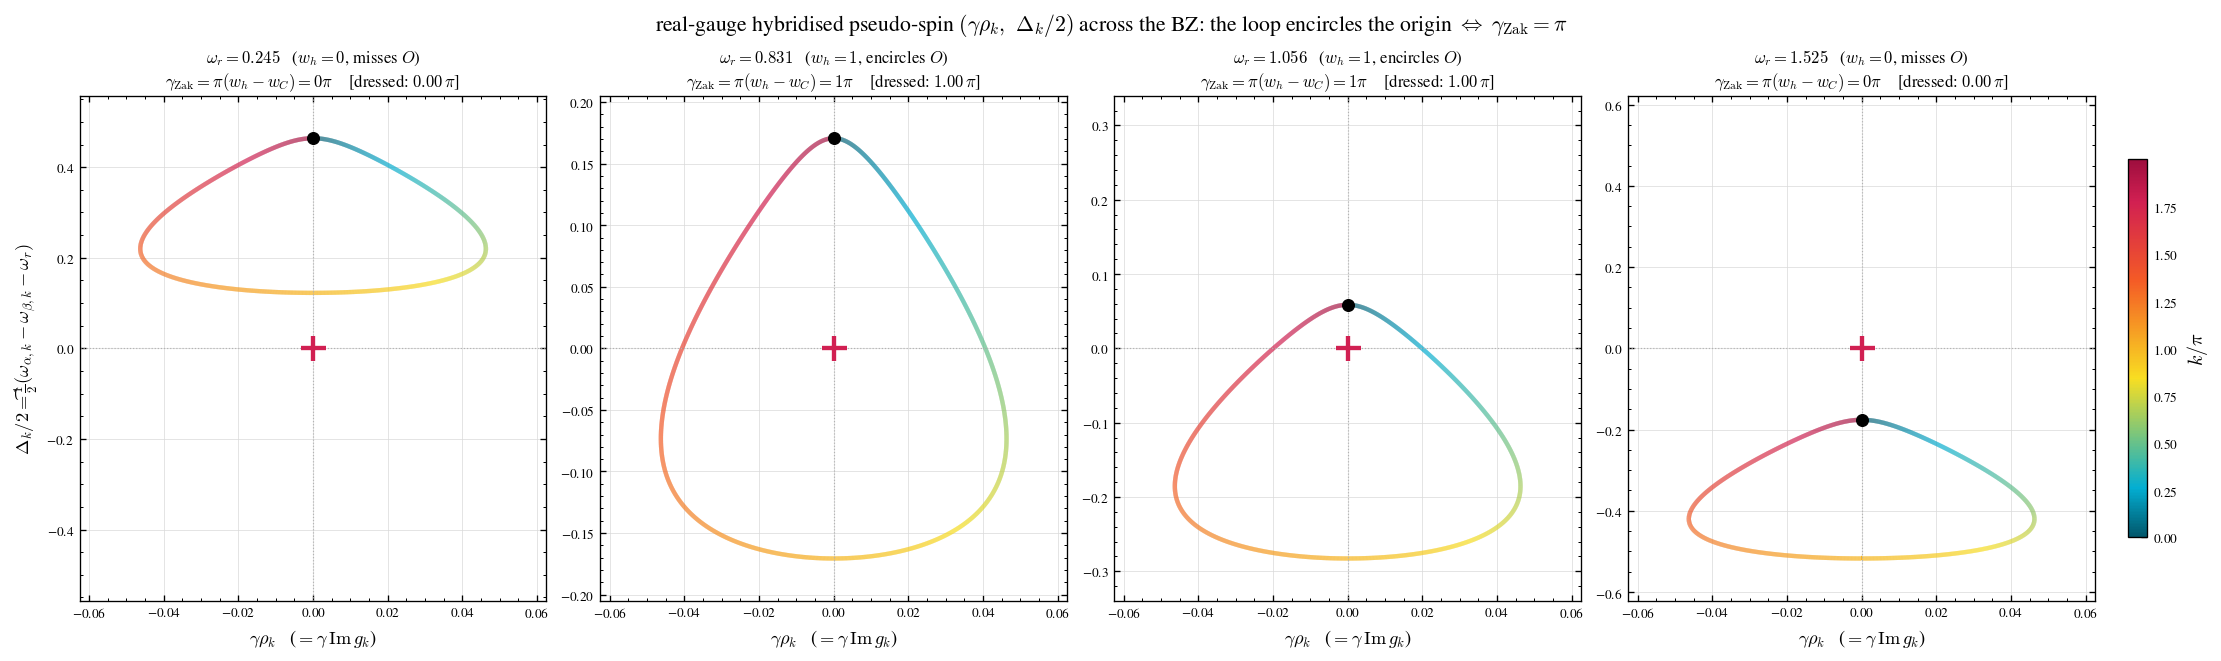

In [43]:
# --- hybridised spinor: real-gauge pseudo-spin loop vs the Zak phase  (plot) -
from matplotlib.collections import LineCollection

omega_r_list = list(spinor_winding)
num_panels   = len(omega_r_list)
fig, axs = plt.subplots(1, num_panels, figsize=(4.6 * num_panels, 5.4), constrained_layout=True)

for ax, omega_r_value in zip(np.atleast_1d(axs), omega_r_list):
    record = spinor_winding[omega_r_value]
    spin_x = np.r_[record["spin_x"], record["spin_x"][:1]]
    spin_z = np.r_[record["spin_z"], record["spin_z"][:1]]
    points = np.column_stack([spin_x, spin_z]).reshape(-1, 1, 2)
    loop = LineCollection(np.concatenate([points[:-1], points[1:]], axis=1),
                          cmap="thesis_cmap", linewidth=2.6)
    loop.set_array(np.r_[loop_momenta, 2 * np.pi][:-1] / np.pi)
    ax.add_collection(loop)

    ax.axhline(0.0, color="0.7", lw=0.7, ls=":")
    ax.axvline(0.0, color="0.7", lw=0.7, ls=":")
    ax.plot(0, 0, "+", color=ts.COLORS["red"], ms=15, mew=2.6, zorder=5)          # origin
    ax.plot(spin_x[0], spin_z[0], "o", color="k", ms=7, zorder=6)                 # k = 0

    span_x = np.abs(record["spin_x"]).max()
    span_z = np.abs(record["spin_z"]).max()
    ax.set_xlim(-1.35 * span_x, 1.35 * span_x)
    ax.set_ylim(-1.2 * max(span_z, span_x), 1.2 * max(span_z, span_x))

    encircles = "encircles $O$" if record["w_h"] else "misses $O$"
    ax.set_title(rf"$\omega_r = {omega_r_value:.3f}$   ($w_h = {record['w_h']}$, {encircles})"
                 "\n"
                 rf"$\gamma_{{\rm Zak}} = \pi(w_h - w_C) = {record['zak_from_winding']}\pi$"
                 rf"    [dressed: ${record['zak_reference']:.2f}\,\pi$]",
                 fontsize=10)
    ax.set_xlabel(r"$\gamma\rho_k$   ($=\gamma\,\mathrm{Im}\,g_k$)", fontsize=11)

np.atleast_1d(axs)[0].set_ylabel(r"$\Delta_k/2 = \t \frac{1}{2}(\omega_{\alpha,k}-\omega_{\beta,k}-\omega_r)$",
                                 fontsize=11)
colorbar = fig.colorbar(loop, ax=axs, shrink=0.75, pad=0.015)
colorbar.set_label(r"$k / \pi$", fontsize=12)
fig.suptitle(r"real-gauge hybridised pseudo-spin $(\gamma\rho_k,\ \Delta_k/2)$ across the BZ: "
             r"the loop encircles the origin $\Leftrightarrow$ $\gamma_{\rm Zak}=\pi$", fontsize=13)
ts.finalize(axs)
plt.show()

## Why the Schrieffer-Wolff correction blows up near the interband resonance

The doublet $\{|\alpha_k,0\rangle,\ |\beta_k,1\rangle\}$ sits at $E\approx\omega_{\alpha,k}$.
The pairing block $\tilde{\mathcal B}_J$ connects it -- at second order, through the
photon ladder $(a+a^\dagger)$ -- to **three-quasiparticle** states. The lowest are
three $\beta$-band excitations with no photon, $E\approx 3\,\omega_{\beta,k}$. Such a
state crosses the doublet when $3\omega_\beta\approx\omega_\alpha$, i.e.
$\omega_r\approx 2\,\omega_\beta$; for $\omega_r$ near the interband splitting this
crossing lands right next to the interband-resonant $k^\star$.

At the crossing, second-order perturbation theory (Schrieffer-Wolff) reports a
divergent $|V|^2/\Delta E$ shift where the true physics is a small avoided
crossing. The current `sw_correction_sector` uses **bare Fock energies**
$\sum_i n_i\,\omega_i$ in the denominators and hides the pole behind the soft
regulator $d/(d^2+\varepsilon^2)$ ($\varepsilon=$ `sw_denom_floor`); near $k^\star$
the answer then depends on $\varepsilon$.

The fix suggested by the block structure: build the full $\tilde H_J$ (number
**and** pairing) on $\mathrm{Fock}(\text{cavity})\otimes\mathrm{Fock}_{\rm QP}$,
**separate** $P=\{$doublet$\}$ from $Q=\{$the rest$\}$, **diagonalise both blocks
exactly**, and only then apply the second-order shift through the residual $P$-$Q$
coupling. The denominators become true energy differences $E_P-E_Q$, so the
*spurious* bare-Fock poles vanish; a *genuine* crossing (the $3\beta$ state) still
appears as $\min|E_P-E_Q|\to 0$, and there the honest response is to enlarge $P$.

In [44]:
# --- SW near the interband resonance: bare vs true denominators  (data) ------
import itertools

# QP mode order for the {k,-k} sector:  0=alpha_k, 1=beta_k, 2=alpha_-k, 3=beta_-k
def dressed_doublet_full_joseph(k, g_cap_intra, g_cap_inter, omega_r, gamma,
                                photon_cutoff=6, qp_fock_cutoff=4):
    """H on Fock(cavity) x Fock_QP(4 modes) with the FULL transformed Josephson coupling
    -gamma (a + a^dag) (A_J-number + B_J-pairing + h.c.) kept explicitly (no pre-elimination).
    Kept QP subspace = the states the doublet actually reaches: one QP in a +k band, or
    any three-QP state (A_J is momentum-block-diagonal; B_J only makes (+k,-k) pairs, so a
    bare -k single-QP state is never connected).  Returns (hamiltonian, basis, doublet_indices)."""
    H_cap, H_joseph = sector_nambu_at_k(k, g_cap_intra, g_cap_inter, Omega_J, Chi_J)
    transform, H_cap_diag = diagonalize_cap_sector(H_cap, k, g_cap_intra, g_cap_inter)
    H_joseph_qp = transform.conj().T @ H_joseph @ transform
    qp_band_frequencies = 2.0 * np.diag(H_cap_diag[:4, :4]).real
    number_block  = 2.0 * H_joseph_qp[:4, :4]                         # tilde A_J  (physical)
    pairing_block = 2.0 * H_joseph_qp[:4, 4:]                         # tilde B_J

    single_mode_lower = np.diag(np.sqrt(np.arange(1, qp_fock_cutoff)), 1)

    def qp_ladder(mode, raising):
        operator = np.array([[1.0]])
        for other in range(4):
            factor = (single_mode_lower.conj().T if raising else single_mode_lower) \
                     if other == mode else np.eye(qp_fock_cutoff)
            operator = np.kron(operator, factor)
        return operator

    qp_annihilate = [qp_ladder(mode, False) for mode in range(4)]
    qp_create     = [qp_ladder(mode, True)  for mode in range(4)]
    number_operator  = sum(number_block[i, j] * (qp_create[i] @ qp_annihilate[j])
                           for i in range(4) for j in range(4))
    pairing_operator = sum(pairing_block[i, j] * (qp_create[i] @ qp_create[j])
                           for i in range(4) for j in range(4))
    matter_coupling  = number_operator + pairing_operator + pairing_operator.conj().T
    qp_free_energy   = sum(qp_band_frequencies[m] * (qp_create[m] @ qp_annihilate[m]) for m in range(4))

    all_qp_states = list(itertools.product(range(qp_fock_cutoff), repeat=4))
    kept = [i for i, s in enumerate(all_qp_states)
            if sum(s) == 3 or (sum(s) == 1 and s[2] == 0 and s[3] == 0)]
    matter_coupling = matter_coupling[np.ix_(kept, kept)]
    qp_free_energy  = qp_free_energy[np.ix_(kept, kept)].real
    kept_qp_states  = [all_qp_states[i] for i in kept]

    photon_lower  = np.diag(np.sqrt(np.arange(1, photon_cutoff)), 1)
    photon_number = np.diag(np.arange(photon_cutoff))
    hamiltonian   = (np.kron(omega_r * photon_number, np.eye(len(kept)))
                     + np.kron(np.eye(photon_cutoff), qp_free_energy)).astype(complex)
    hamiltonian  += -gamma * np.kron(photon_lower + photon_lower.conj().T, matter_coupling)
    hamiltonian   = 0.5 * (hamiltonian + hamiltonian.conj().T)

    basis = [(photon, kept_qp_states[q])
             for photon in range(photon_cutoff) for q in range(len(kept))]
    doublet_indices = [basis.index((0, (1, 0, 0, 0))),      # |alpha_k, 0>
                       basis.index((1, (0, 1, 0, 0)))]      # |beta_k, 1>
    return hamiltonian, basis, doublet_indices


def schrieffer_wolff_downfold(hamiltonian, target_indices, denominator_floor):
    """2x2 doublet: diagonalise the target (P) and spectator (Q) sub-blocks exactly,
    rotate the P-Q coupling into those eigenbases, apply the second-order shift with a
    soft resolvent  d / (d^2 + eps^2).  Returns (tls_2x2, energies_P, energies_Q)."""
    spectator_indices = [i for i in range(hamiltonian.shape[0]) if i not in target_indices]
    energies_P, basis_P = np.linalg.eigh(hamiltonian[np.ix_(target_indices, target_indices)])
    energies_Q, basis_Q = np.linalg.eigh(hamiltonian[np.ix_(spectator_indices, spectator_indices)])
    coupling_in_eigenbasis = (basis_P.conj().T
                              @ hamiltonian[np.ix_(target_indices, spectator_indices)]
                              @ basis_Q)
    energy_denominator = energies_P[:, None] - energies_Q[None, :]
    resolvent = energy_denominator / (energy_denominator ** 2 + denominator_floor ** 2)
    second_order = (coupling_in_eigenbasis * resolvent) @ coupling_in_eigenbasis.conj().T
    tls_2x2 = basis_P @ (np.diag(energies_P) + 0.5 * (second_order + second_order.conj().T)) @ basis_P.conj().T
    return tls_2x2, energies_P, energies_Q


# --- sweep k through the interband resonance at omega_r = resonant_omega_r ---
omega_r_resonance = resonant_omega_r
gamma_resonance   = gamma_winding
k_resonance       = np.linspace(0.85, 1.85, 120)

bloch_magnitude_resonance = np.abs(g_cap_intra + g_cap_inter * np.exp(-1j * k_resonance))
band_split_resonance = (np.sqrt(1 + 2 * bloch_magnitude_resonance)
                        - np.sqrt(1 - 2 * bloch_magnitude_resonance))
k_star = float(k_resonance[np.argmin(np.abs(band_split_resonance - omega_r_resonance))])

resonance_scan = {key: [] for key in
                  ("Delta", "bare_denominator", "true_denominator",
                   "gap_bare_2x2", "gap_sw_tiny_reg", "gap_method_b", "gap_exact")}
crossing_qp_at_k_star = None
for k in k_resonance:
    H_cap, _ = sector_nambu_at_k(k, g_cap_intra, g_cap_inter, Omega_J, Chi_J)
    _, H_cap_diag = diagonalize_cap_sector(H_cap, k, g_cap_intra, g_cap_inter)
    omega_alpha, omega_beta = 2.0 * np.diag(H_cap_diag[:2, :2]).real
    resonance_scan["Delta"].append(omega_alpha - omega_beta - omega_r_resonance)

    bare_one_qp   = [omega_alpha, omega_beta]
    bare_three_qp = [3 * omega_alpha, 2 * omega_alpha + omega_beta,
                     omega_alpha + 2 * omega_beta, 3 * omega_beta]
    resonance_scan["bare_denominator"].append(
        min(abs(photon_step * omega_r_resonance + e_one - e_three)
            for photon_step in (-1, 1) for e_one in bare_one_qp for e_three in bare_three_qp))

    hamiltonian, basis, doublet = dressed_doublet_full_joseph(
        k, g_cap_intra, g_cap_inter, omega_r_resonance, gamma_resonance)
    tls_method_b, energies_P, energies_Q = schrieffer_wolff_downfold(
        hamiltonian, doublet, 0.05 * omega_r_resonance)
    nearest_index = np.abs(energies_Q[:, None] - energies_P[None, :]).min(axis=1).argmin()
    resonance_scan["true_denominator"].append(
        abs(energies_Q[nearest_index] - energies_P).min())
    resonance_scan["gap_method_b"].append(np.ptp(np.linalg.eigvalsh(tls_method_b)))

    _, gap_bare_2x2, gap_sw_tiny_reg = three_gaps(
        k, g_cap_intra, g_cap_inter, omega_r_resonance, gamma_resonance, denom_floor=1e-3)
    resonance_scan["gap_bare_2x2"].append(gap_bare_2x2)
    resonance_scan["gap_sw_tiny_reg"].append(gap_sw_tiny_reg)

    eigenvalues, eigenvectors = np.linalg.eigh(hamiltonian)
    doublet_weight = (np.abs(eigenvectors[doublet, :]) ** 2).sum(0)
    top_two = np.argsort(doublet_weight)[-2:]
    resonance_scan["gap_exact"].append(
        np.ptp(eigenvalues[top_two]) if doublet_weight[top_two].min() > 0.6 else np.nan)

    if abs(k - k_star) < 0.5 * (k_resonance[1] - k_resonance[0]):
        spectator_basis = [basis[i] for i in range(len(basis)) if i not in doublet]
        _, spectator_vectors = np.linalg.eigh(
            hamiltonian[np.ix_([i for i in range(len(basis)) if i not in doublet],
                               [i for i in range(len(basis)) if i not in doublet])])
        dominant = np.abs(spectator_vectors[:, nearest_index]) ** 2
        crossing_qp_at_k_star = spectator_basis[dominant.argmax()]

resonance_scan = {key: np.array(value) for key, value in resonance_scan.items()}
print(f"omega_r = {omega_r_resonance:.3f}   interband-resonant k* = {k_star:.3f}")
print(f"nearest crossing spectator at k*:  (photon, QP occ) = {crossing_qp_at_k_star}  "
      f"(three-beta, zero-photon  ~  3 omega_beta)\n")
print(f"{'k':>7} {'Delta':>9} {'bare denom':>11} {'true denom':>11} "
      f"{'gap SW(1e-3)':>13} {'gap method B':>13} {'gap exact':>11}")
for row in range(0, len(k_resonance), 8):
    print(f"{k_resonance[row]:7.3f} {resonance_scan['Delta'][row]:+9.4f} "
          f"{resonance_scan['bare_denominator'][row]:11.4f} {resonance_scan['true_denominator'][row]:11.4f} "
          f"{resonance_scan['gap_sw_tiny_reg'][row]:13.4f} {resonance_scan['gap_method_b'][row]:13.4f} "
          f"{resonance_scan['gap_exact'][row]:11.4f}")

omega_r = 0.950   interband-resonant k* = 1.161
nearest crossing spectator at k*:  (photon, QP occ) = (0, (0, 3, 0, 0))  (three-beta, zero-photon  ~  3 omega_beta)

      k     Delta  bare denom  true denom  gap SW(1e-3)  gap method B   gap exact
  0.850   +0.0882      0.2788      0.2745        0.1078        0.1078      0.1076
  0.917   +0.0700      0.2497      0.2433        0.0950        0.0950      0.0948
  0.984   +0.0513      0.2200      0.2105        0.0833        0.0833      0.0830
  1.052   +0.0321      0.1899      0.1752        0.0735        0.0735      0.0732
  1.119   +0.0125      0.1593      0.1369        0.0669        0.0668      0.0664
  1.186   -0.0075      0.1285      0.0949        0.0647        0.0645      0.0638
  1.253   -0.0277      0.0976      0.0498        0.0678        0.0674      0.0654
  1.321   -0.0482      0.0666      0.0024        0.0765        0.0773      0.0894
  1.388   -0.0689      0.0356      0.0463        0.0930        0.0918      0.1016
  1.455   -0.08

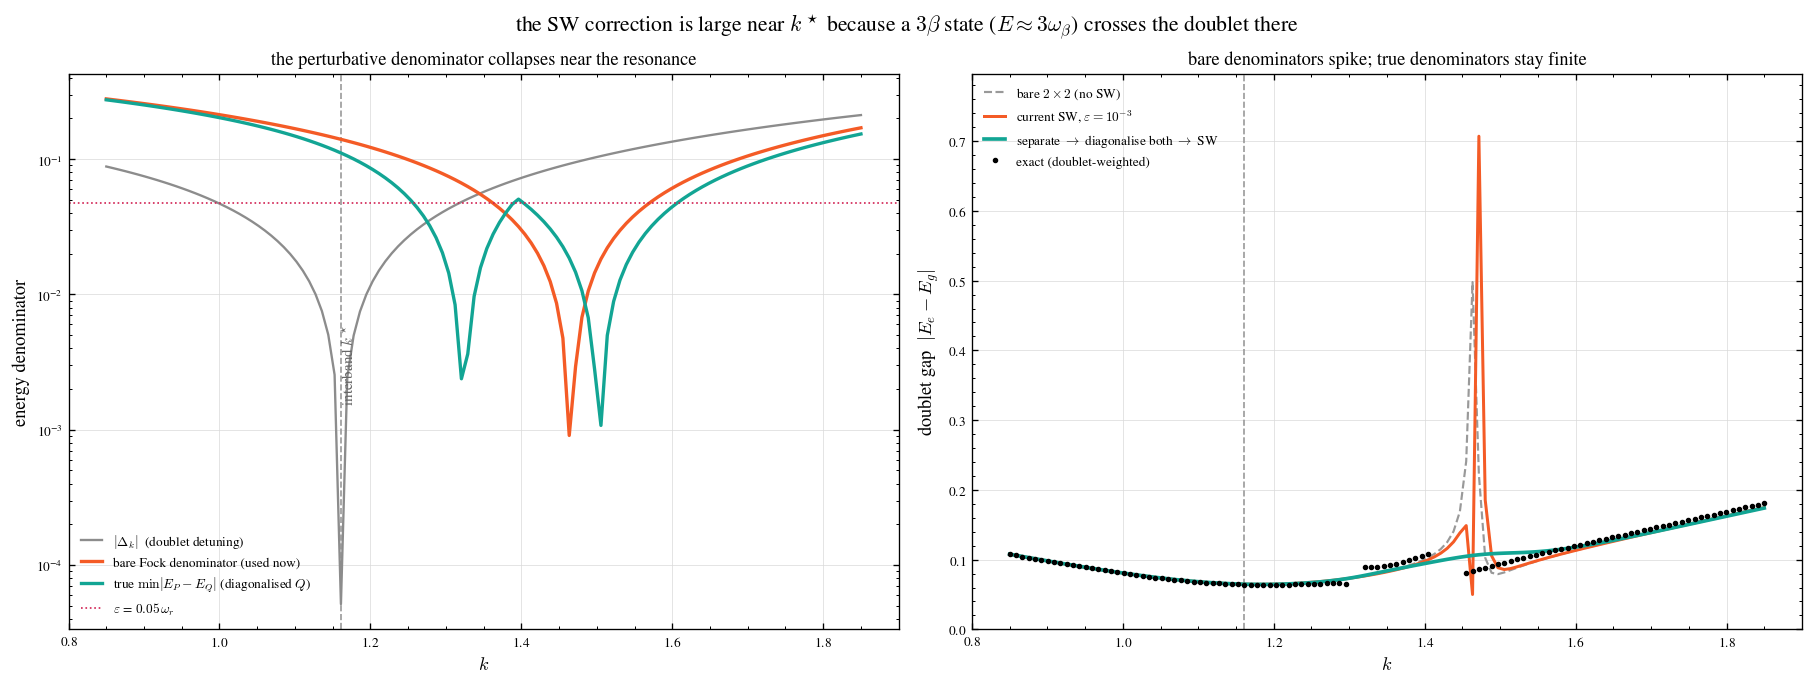

In [45]:
# --- SW near the interband resonance: bare vs true denominators  (plot) ------
fig, axs = plt.subplots(1, 2, figsize=(15, 5.6), constrained_layout=True)

axs[0].axvline(k_star, color="0.6", lw=1.0, ls="--")
axs[0].text(k_star, 0.55, r"  interband $k^\star$", rotation=90, va="top", ha="left",
            color="0.4", fontsize=9, transform=axs[0].get_xaxis_transform())
axs[0].semilogy(k_resonance, np.abs(resonance_scan["Delta"]), color="0.55", lw=1.4,
                label=r"$|\Delta_k|$  (doublet detuning)")
axs[0].semilogy(k_resonance, resonance_scan["bare_denominator"], color=ts.COLORS["orange"], lw=2.0,
                label=r"bare Fock denominator (used now)")
axs[0].semilogy(k_resonance, resonance_scan["true_denominator"], color=ts.COLORS["teal"], lw=2.0,
                label=r"true $\min|E_P-E_Q|$ (diagonalised $Q$)")
axs[0].axhline(0.05 * omega_r_resonance, color=ts.COLORS["red"], lw=1.0, ls=":",
               label=r"$\varepsilon$ = $0.05\,\omega_r$")
axs[0].set_xlabel(r"$k$", fontsize=11)
axs[0].set_ylabel("energy denominator", fontsize=11)
axs[0].set_title("the perturbative denominator collapses near the resonance", fontsize=11)
axs[0].legend(fontsize=8, loc="lower left")

axs[1].axvline(k_star, color="0.6", lw=1.0, ls="--")
axs[1].plot(k_resonance, resonance_scan["gap_bare_2x2"], color="0.6", lw=1.3, ls="--",
            label=r"bare $2\times2$ (no SW)")
axs[1].plot(k_resonance, resonance_scan["gap_sw_tiny_reg"], color=ts.COLORS["orange"], lw=1.8,
            label=r"current SW, $\varepsilon=10^{-3}$")
axs[1].plot(k_resonance, resonance_scan["gap_method_b"], color=ts.COLORS["teal"], lw=2.2,
            label=r"separate $\to$ diagonalise both $\to$ SW")
axs[1].plot(k_resonance, resonance_scan["gap_exact"], color="k", lw=0, marker="o", ms=2.5,
            label=r"exact (doublet-weighted)")
axs[1].set_xlabel(r"$k$", fontsize=11)
axs[1].set_ylabel(r"doublet gap  $|E_e - E_g|$", fontsize=11)
axs[1].set_ylim(0, max(np.nanmax(resonance_scan["gap_bare_2x2"]),
                       np.nanmax(resonance_scan["gap_method_b"])) * 1.6)
axs[1].set_title(r"bare denominators spike; true denominators stay finite", fontsize=11)
axs[1].legend(fontsize=8, loc="upper left")

fig.suptitle(r"the SW correction is large near $k^\star$ because a $3\beta$ state ($E\approx3\omega_\beta$) "
             r"crosses the doublet there", fontsize=13)
ts.finalize(axs)
plt.show()

## The SW-corrected spinor (full $\tilde H_J$, pairing folded in)

Using `dressed_doublet_full_joseph` + `schrieffer_wolff_downfold` from above: the
full $\tilde H_J$ on $\mathrm{Fock}(\text{cavity})\otimes\mathrm{Fock}_{\rm QP}$
(QP total $\in\{1,3\}$), one SW step onto $\{|\alpha_k,0\rangle,|\beta_k,1\rangle\}$
with the soft resolvent. The corrected off-diagonal stays **exactly imaginary**,
$g_k^{\rm SW}=i\,\rho_k^{\rm SW}$ (checked below), so the pseudo-spin is still
planar: the correction renormalises $\Delta_k$ and $\gamma\rho_k$ but does not tilt
the plane. The plot overlays the corrected loop on the bare one; because the
$3\beta$ crossing of the previous section is a narrow feature in $k$ it does not
change the winding, so $\gamma_{\rm Zak}$ is unchanged.

In [46]:
# --- full H_J on the doublet: SW-corrected pseudo-spin loop  (data) ---------
def sw_corrected_pseudospin_loop(momenta, g_cap_intra, g_cap_inter, omega_r, gamma,
                                 photon_cutoff=5, qp_fock_cutoff=3):
    """(spin_x, spin_z) = (gamma rho_k^SW, Delta_k^SW / 2)  from the SW-downfolded 2x2."""
    denominator_floor = 0.05 * omega_r
    spin_x = np.empty(len(momenta))
    spin_z = np.empty(len(momenta))
    residual_real_part = 0.0
    for index, k in enumerate(momenta):
        hamiltonian, _, doublet_indices = dressed_doublet_full_joseph(
            k, g_cap_intra, g_cap_inter, omega_r, gamma, photon_cutoff, qp_fock_cutoff)
        corrected_tls, _, _ = schrieffer_wolff_downfold(hamiltonian, doublet_indices, denominator_floor)
        spin_x[index] = -corrected_tls[0, 1].imag                       # -Im(H_TLS[0,1]) = gamma rho_k^SW
        spin_z[index] = 0.5 * (corrected_tls[0, 0] - corrected_tls[1, 1]).real
        residual_real_part = max(residual_real_part, abs(corrected_tls[0, 1].real))
    return spin_x, spin_z, residual_real_part


num_k_sw = 600
loop_momenta_sw = np.linspace(0.0, 2 * np.pi, num_k_sw, endpoint=False)

sw_spinor_winding = {}
print(f"gamma = {gamma_winding},   w_C = {ssh_winding}\n")
print(f"{'omega_r':>9} {'w_h (bare)':>11} {'w_h (SW)':>10} {'zak_dressed(1)/pi':>18} "
      f"{'max|Re g_k^SW|':>15}   match")
for omega_r_value in omega_r_winding:
    spin_x_sw, spin_z_sw, residual = sw_corrected_pseudospin_loop(
        loop_momenta_sw, g_cap_intra, g_cap_inter, omega_r_value, gamma_winding)
    winding_sw = abs(loop_winding_number(spin_x_sw, spin_z_sw))
    zak_from_winding_sw = (winding_sw - ssh_winding) % 2
    zak_reference = spinor_winding[float(omega_r_value)]["zak_reference"]
    winding_bare = spinor_winding[float(omega_r_value)]["w_h"]
    sw_spinor_winding[float(omega_r_value)] = dict(
        spin_x=spin_x_sw, spin_z=spin_z_sw, w_h=winding_sw,
        zak_from_winding=zak_from_winding_sw, residual=residual)
    print(f"{omega_r_value:9.3f} {winding_bare:11d} {winding_sw:10d} {zak_reference:18.3f} "
          f"{residual:15.2e}   "
          f"{'ok' if abs(zak_from_winding_sw - zak_reference) < 1e-6 else 'MISMATCH'}")

gamma = 0.04,   w_C = 0

  omega_r  w_h (bare)   w_h (SW)  zak_dressed(1)/pi  max|Re g_k^SW|   match
    0.245           0          0              0.000        2.23e-16   ok
    0.831           1          1              1.000        6.64e-17   ok
    1.056           1          1              1.000        1.59e-16   ok
    1.525           0          0              0.000        1.98e-16   ok


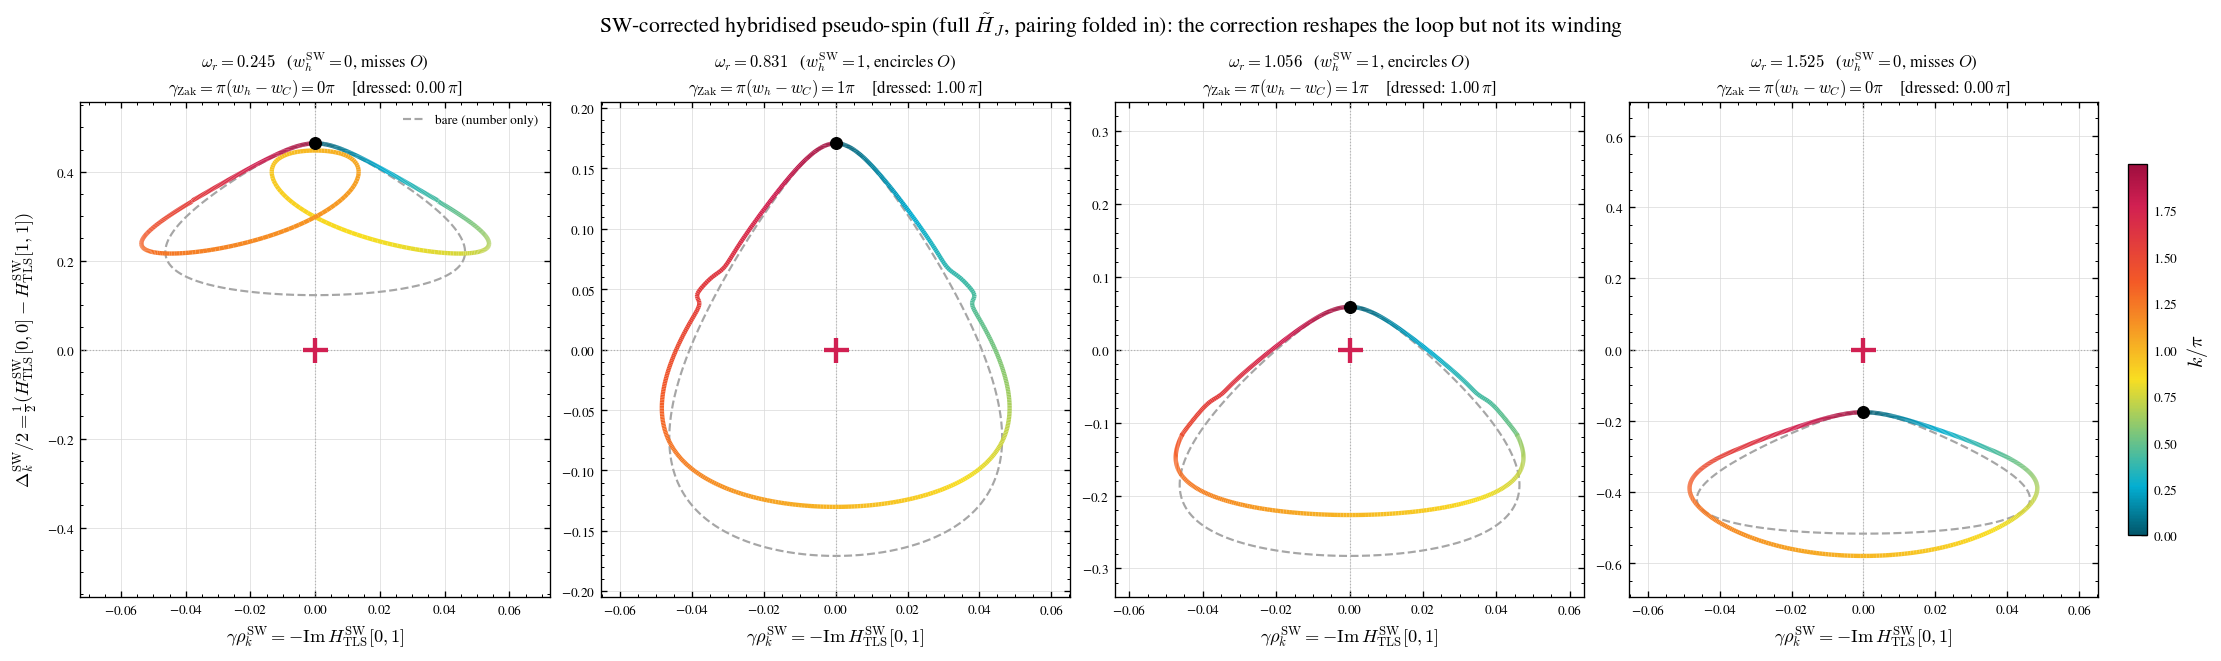

In [47]:
# --- full H_J on the doublet: SW-corrected pseudo-spin loop  (plot) ---------
from matplotlib.collections import LineCollection

omega_r_list = list(sw_spinor_winding)
num_panels   = len(omega_r_list)
fig, axs = plt.subplots(1, num_panels, figsize=(4.6 * num_panels, 5.4), constrained_layout=True)

for ax, omega_r_value in zip(np.atleast_1d(axs), omega_r_list):
    bare      = spinor_winding[omega_r_value]
    corrected = sw_spinor_winding[omega_r_value]

    ax.plot(np.r_[bare["spin_x"], bare["spin_x"][:1]],
            np.r_[bare["spin_z"], bare["spin_z"][:1]],
            color="0.65", lw=1.3, ls="--", zorder=1, label="bare (number only)")

    spin_x = np.r_[corrected["spin_x"], corrected["spin_x"][:1]]
    spin_z = np.r_[corrected["spin_z"], corrected["spin_z"][:1]]
    points = np.column_stack([spin_x, spin_z]).reshape(-1, 1, 2)
    loop = LineCollection(np.concatenate([points[:-1], points[1:]], axis=1),
                          cmap="thesis_cmap", linewidth=2.6, zorder=3)
    loop.set_array(np.r_[loop_momenta_sw, 2 * np.pi][:-1] / np.pi)
    ax.add_collection(loop)

    ax.axhline(0.0, color="0.7", lw=0.7, ls=":")
    ax.axvline(0.0, color="0.7", lw=0.7, ls=":")
    ax.plot(0, 0, "+", color=ts.COLORS["red"], ms=15, mew=2.6, zorder=5)
    ax.plot(spin_x[0], spin_z[0], "o", color="k", ms=7, zorder=6)

    span_x = max(np.abs(corrected["spin_x"]).max(), np.abs(bare["spin_x"]).max())
    span_z = max(np.abs(corrected["spin_z"]).max(), np.abs(bare["spin_z"]).max())
    ax.set_xlim(-1.35 * span_x, 1.35 * span_x)
    ax.set_ylim(-1.2 * max(span_z, span_x), 1.2 * max(span_z, span_x))

    encircles = "encircles $O$" if corrected["w_h"] else "misses $O$"
    ax.set_title(rf"$\omega_r = {omega_r_value:.3f}$   ($w_h^{{\rm SW}} = {corrected['w_h']}$, {encircles})"
                 "\n"
                 rf"$\gamma_{{\rm Zak}} = \pi(w_h - w_C) = {corrected['zak_from_winding']}\pi$"
                 rf"    [dressed: ${bare['zak_reference']:.2f}\,\pi$]",
                 fontsize=10)
    ax.set_xlabel(r"$\gamma\rho_k^{\rm SW} = -\mathrm{Im}\,H_{\rm TLS}^{\rm SW}[0,1]$", fontsize=11)

first_ax = np.atleast_1d(axs)[0]
first_ax.set_ylabel(r"$\Delta_k^{\rm SW}/2 = \frac{1}{2}(H_{\rm TLS}^{\rm SW}[0,0] - H_{\rm TLS}^{\rm SW}[1,1])$",
                    fontsize=11)
first_ax.legend(loc="upper right", fontsize=8)
colorbar = fig.colorbar(loop, ax=axs, shrink=0.75, pad=0.015)
colorbar.set_label(r"$k / \pi$", fontsize=12)
fig.suptitle(r"SW-corrected hybridised pseudo-spin (full $\tilde H_J$, pairing folded in): "
             r"the correction reshapes the loop but not its winding", fontsize=13)
ts.finalize(axs)
plt.show()

## Kerr regularisation of the SW singularity

The blow-up near the interband resonance is a three-quasiparticle state at
$E\approx 3\omega_{\beta,k}$ crossing the doublet at $E\approx\omega_{\alpha,k}$.
An anharmonic (Kerr) term shifts the multi-QP levels but leaves the one-QP doublet
almost untouched, so it can push that virtual state clear of the doublet and
restore a well-behaved SW downfold.

The site Kerr $-\,\mathrm{kerr}\sum_j n_j(n_j-1)$ (as in `PeriodicChainSW`), kept
for the $\{k,-k\}$ sector only, is $-\tfrac{\mathrm{kerr}}{N}\sum_{s}\!\big[
n_{k,s}(n_{k,s}-1)+n_{-k,s}(n_{-k,s}-1)+4\,n_{k,s}n_{-k,s}\big]$ (number-diagonal
part); pushed through the analytic $T=T_{\rm rot}T_{\rm sq}$ into the
$(\alpha_k,\beta_k,\alpha_{-k},\beta_{-k})$ basis it becomes a quartic operator
whose **Fock-diagonal element** (first order) — or, optionally, its second-order
level shift — corrects the QP level energies. Only the level *energies* are
touched; the full quartic is not added to $H$. This is a **separate** function
from `dressed_doublet_full_joseph`.

The doublet ($\le 1$ QP) barely moves; the $3\beta$ state moves by $\sim 3K/N$. A
*hardening* shift ($\mathrm{kerr}<0$ here, raising the multi-QP levels) lifts it
above the doublet and clears the crossing; a *softening* one ($\mathrm{kerr}>0$,
transmon-like) pushes it further onto the doublet and makes things worse.

In [48]:
# --- Kerr-corrected multi-QP levels: definitions ---------------------------
def sector_kerr_qp_level_shift(k, g_cap_intra, g_cap_inter, kerr, num_cells,
                               qp_fock_cutoff, kerr_order=1):
    """Fock-diagonal energy shift of the {k,-k}-sector QP levels from the site Kerr
    -kerr * sum_j n_j(n_j-1).  Restricted to the sector and divided by num_cells (each
    site's Kerr spreads over all N momenta), then pushed through T = T_rot T_sq into the
    (alpha_k, beta_k, alpha_-k, beta_-k) basis.  order 1 = the diagonal element
    <fock|H_Kerr|fock>;  order 2 also adds sum_{m!=n} |<m|H_Kerr|n>|^2 / (E0_n - E0_m)."""
    H_cap, _ = sector_nambu_at_k(k, g_cap_intra, g_cap_inter, Omega_J, Chi_J)
    transform, H_cap_diag = diagonalize_cap_sector(H_cap, k, g_cap_intra, g_cap_inter)

    single_mode_lower = np.diag(np.sqrt(np.arange(1, qp_fock_cutoff)), 1)

    def qp_ladder(mode, raising):
        operator = np.array([[1.0]])
        for other in range(4):
            factor = (single_mode_lower.conj().T if raising else single_mode_lower) \
                     if other == mode else np.eye(qp_fock_cutoff)
            operator = np.kron(operator, factor)
        return operator

    qp_annihilate = [qp_ladder(mode, False) for mode in range(4)]
    qp_create     = [qp_ladder(mode, True)  for mode in range(4)]

    # Fourier-mode annihilation ops (c_kA, c_kB, c_-kA, c_-kB) as Bogoliubov combos:
    #   Psi_site = transform . Psi_qp   =>   c_i = sum_j T[i,j] a_j + T[i,4+j] a_j^dag
    fourier_mode = [sum(transform[i, j] * qp_annihilate[j] + transform[i, 4 + j] * qp_create[j]
                        for j in range(4)) for i in range(4)]
    number_c = [op.conj().T @ op for op in fourier_mode]

    dimension = qp_fock_cutoff ** 4
    identity = np.eye(dimension)
    kerr_operator = np.zeros((dimension, dimension), dtype=complex)
    for mode_plus_k, mode_minus_k in ((0, 2), (1, 3)):            # (kA,-kA), (kB,-kB)
        n_plus, n_minus = number_c[mode_plus_k], number_c[mode_minus_k]
        kerr_operator += (n_plus @ (n_plus - identity) + n_minus @ (n_minus - identity)
                          + 4.0 * (n_plus @ n_minus))
    kerr_operator *= -kerr / num_cells
    kerr_operator = 0.5 * (kerr_operator + kerr_operator.conj().T)

    all_qp_states = list(itertools.product(range(qp_fock_cutoff), repeat=4))
    kept = [i for i, s in enumerate(all_qp_states)
            if sum(s) == 3 or (sum(s) == 1 and s[2] == 0 and s[3] == 0)]
    kerr_kept = kerr_operator[np.ix_(kept, kept)]

    level_shift = np.diag(kerr_kept).real                          # first order
    if kerr_order >= 2:
        qp_band_frequencies = 2.0 * np.diag(H_cap_diag[:4, :4]).real
        bare_energy = np.array([np.dot(all_qp_states[i], qp_band_frequencies) for i in kept])
        energy_gap = bare_energy[None, :] - bare_energy[:, None]   # [m, n] -> E0_n - E0_m
        resolvent = np.where(np.abs(energy_gap) > 1e-6,
                             1.0 / np.where(np.abs(energy_gap) > 1e-6, energy_gap, 1.0), 0.0)
        np.fill_diagonal(resolvent, 0.0)
        level_shift = level_shift + np.sum(np.abs(kerr_kept) ** 2 * resolvent, axis=0)
    return level_shift


def dressed_doublet_full_joseph_kerr(k, g_cap_intra, g_cap_inter, omega_r, gamma, kerr,
                                     num_cells=num_cells, photon_cutoff=6,
                                     qp_fock_cutoff=4, kerr_order=1):
    """dressed_doublet_full_joseph, with the QP Fock levels carrying the anharmonic Kerr
    shift (sector_kerr_qp_level_shift).  Only the level ENERGIES are corrected -- the full
    quartic Kerr operator is not added to H -- so the doublet stays put while the multi-QP
    virtual states move off resonance.  kerr = the site Kerr coefficient of
    -kerr sum_j n_j(n_j-1), as in PeriodicChainSW  (kerr < 0 = hardening = clears the crossing)."""
    hamiltonian, basis, doublet_indices = dressed_doublet_full_joseph(
        k, g_cap_intra, g_cap_inter, omega_r, gamma, photon_cutoff, qp_fock_cutoff)
    if kerr != 0.0:
        level_shift = sector_kerr_qp_level_shift(
            k, g_cap_intra, g_cap_inter, kerr, num_cells, qp_fock_cutoff, kerr_order)
        hamiltonian = hamiltonian + np.kron(np.eye(photon_cutoff), np.diag(level_shift))
    return hamiltonian, basis, doublet_indices


# byte-identical to dressed_doublet_full_joseph when kerr = 0
_check = np.allclose(
    dressed_doublet_full_joseph_kerr(1.3, g_cap_intra, g_cap_inter, resonant_omega_r,
                                     gamma_winding, kerr=0.0)[0],
    dressed_doublet_full_joseph(1.3, g_cap_intra, g_cap_inter, resonant_omega_r,
                                gamma_winding)[0])
print(f"dressed_doublet_full_joseph_kerr(kerr=0)  ==  dressed_doublet_full_joseph :  {_check}")

dressed_doublet_full_joseph_kerr(kerr=0)  ==  dressed_doublet_full_joseph :  True


In [ ]:
# --- Kerr regularisation: sweep k through the resonance vs kerr  (data) -----
kerr_values   = [0.0, -0.05, -0.05]      # site Kerr;  per-sector shift ~ |kerr| / num_cells
kerr_order    = 2                       # 1 = diagonal element (preferred);  2 = + 2nd-order

kerr_scan = {}                          # kerr -> dict(true_denominator, gap_method_b, gap_exact)
print(f"omega_r = {omega_r_resonance:.3f},  k* = {k_star:.3f},  num_cells = {num_cells},  "
      f"kerr_order = {kerr_order}\n")
print(f"{'kerr':>6} {'per-sector':>11} {'min|E_P-E_Q| in window':>24} "
      f"{'max|gap_SW - gap_exact|':>24} {'k where doublet dissolves':>26}")
for kerr in kerr_values:
    true_denominator = np.empty(len(k_resonance))
    gap_method_b     = np.empty(len(k_resonance))
    gap_exact        = np.full(len(k_resonance), np.nan)
    for index, k in enumerate(k_resonance):
        hamiltonian, basis, doublet = dressed_doublet_full_joseph_kerr(
            k, g_cap_intra, g_cap_inter, omega_r_resonance, gamma_winding,
            kerr=kerr, kerr_order=kerr_order)
        tls, energies_P, energies_Q = schrieffer_wolff_downfold(
            hamiltonian, doublet, 0.05 * omega_r_resonance)
        true_denominator[index] = np.abs(energies_Q[:, None] - energies_P[None, :]).min()
        gap_method_b[index]     = np.ptp(np.linalg.eigvalsh(tls))
        eigenvalues, eigenvectors = np.linalg.eigh(hamiltonian)
        doublet_weight = (np.abs(eigenvectors[doublet, :]) ** 2).sum(0)
        top_two = np.argsort(doublet_weight)[-2:]
        if doublet_weight[top_two].min() > 0.6:
            gap_exact[index] = np.ptp(eigenvalues[top_two])
    kerr_scan[kerr] = dict(true_denominator=true_denominator,
                           gap_method_b=gap_method_b, gap_exact=gap_exact)
    in_window = (k_resonance > 1.15) & (k_resonance < 1.6)
    dissolves = k_resonance[np.isnan(gap_exact)]
    print(f"{kerr:6.1f} {abs(kerr) / num_cells:11.3f} "
          f"{np.nanmin(true_denominator[in_window]):24.4f} "
          f"{np.nanmax(np.abs(gap_method_b - gap_exact)):24.4f} "
          f"{('none' if dissolves.size == 0 else f'{dissolves.min():.2f}..{dissolves.max():.2f}'):>26}")

omega_r = 0.950,  k* = 1.161,  num_cells = 10,  kerr_order = 2

  kerr  per-sector   min|E_P-E_Q| in window  max|gap_SW - gap_exact|  k where doublet dissolves
   0.0       0.000                   0.0011                   0.0240                 1.30..1.45
  -0.0       0.002                   0.0002                   0.0200                 1.26..1.40
  -0.1       0.005                   0.0001                   0.0146                 1.17..1.30


In [ ]:
# omega_r = 0.950,  k* = 1.161,  num_cells = 10,  kerr_order = 1

#   kerr  per-sector   min|E_P-E_Q| in window  max|gap_SW - gap_exact|  k where doublet dissolves
#    0.0       0.000                   0.0011                   0.0240                 1.30..1.45
#   -0.0       0.002                   0.0003                   0.0200                 1.26..1.40
#   -0.1       0.005                   0.0003                   0.0151                 1.17..1.30

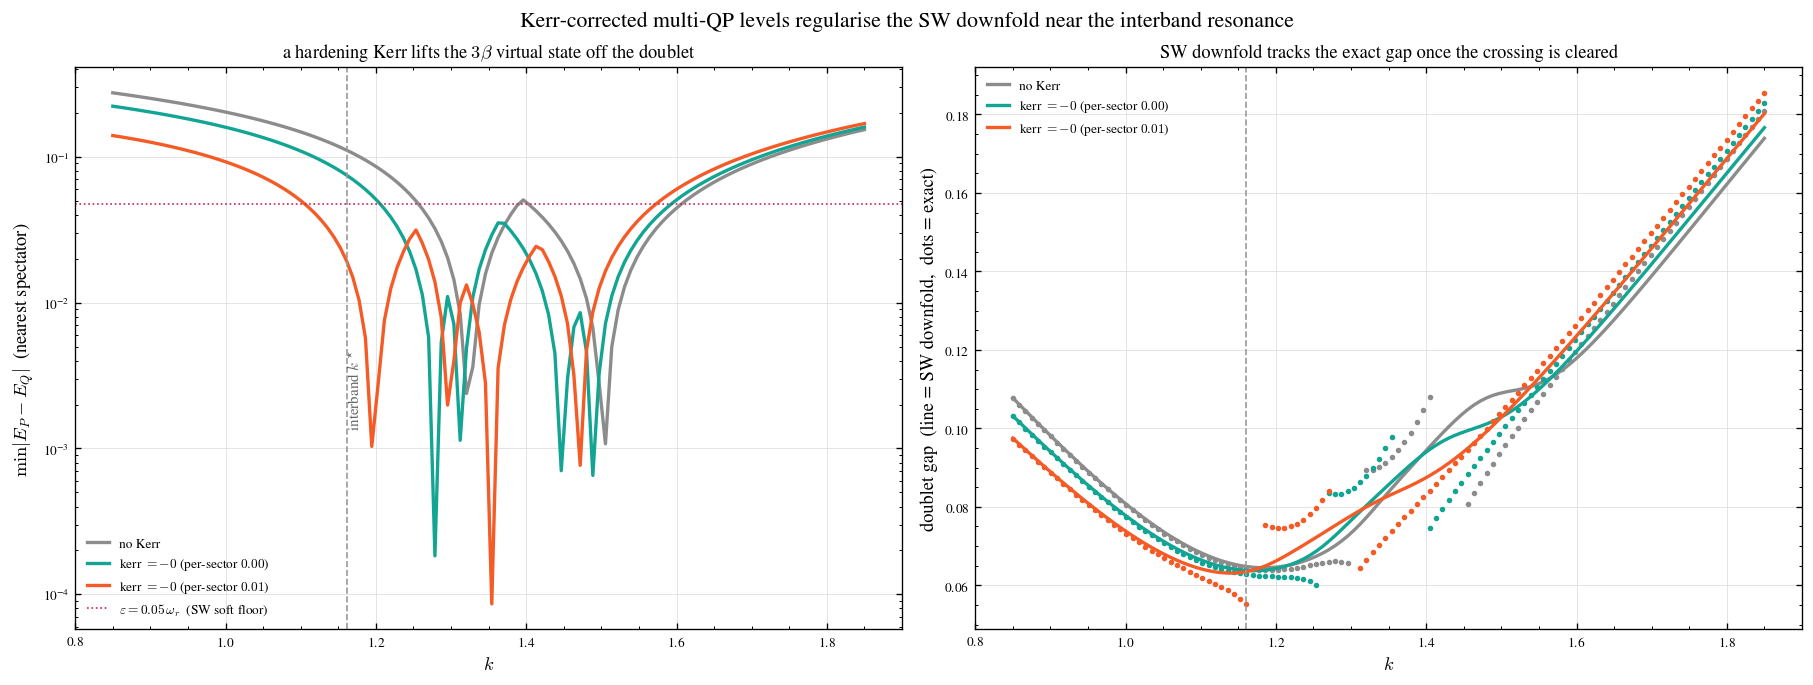

In [59]:
# --- Kerr regularisation: sweep k through the resonance vs kerr  (plot) -----
fig, axs = plt.subplots(1, 2, figsize=(15, 5.6), constrained_layout=True)
kerr_colours = ["0.55", ts.COLORS["teal"], ts.COLORS["orange"], ts.COLORS["purple"]]

for kerr, colour in zip(kerr_values, kerr_colours):
    record = kerr_scan[kerr]
    label = "no Kerr" if kerr == 0.0 else rf"kerr $= {kerr:.0f}$ (per-sector ${abs(kerr)/num_cells:.2f}$)"
    axs[0].semilogy(k_resonance, record["true_denominator"], color=colour, lw=2.0, label=label)
    axs[1].plot(k_resonance, record["gap_method_b"], color=colour, lw=2.0, label=label)
    axs[1].plot(k_resonance, record["gap_exact"], color=colour, lw=0, marker="o", ms=2.5)

for ax in axs:
    ax.axvline(k_star, color="0.6", lw=1.0, ls="--")
axs[0].axhline(0.05 * omega_r_resonance, color=ts.COLORS["red"], lw=1.0, ls=":",
               label=r"$\varepsilon = 0.05\,\omega_r$  (SW soft floor)")
axs[0].text(k_star, 0.5, r"  interband $k^\star$", rotation=90, va="top", ha="left",
            color="0.4", fontsize=9, transform=axs[0].get_xaxis_transform())
axs[0].set_xlabel(r"$k$", fontsize=11)
axs[0].set_ylabel(r"$\min|E_P - E_Q|$  (nearest spectator)", fontsize=11)
axs[0].set_title("a hardening Kerr lifts the $3\\beta$ virtual state off the doublet", fontsize=11)
axs[0].legend(fontsize=8, loc="lower left")

axs[1].set_xlabel(r"$k$", fontsize=11)
axs[1].set_ylabel(r"doublet gap  (line = SW downfold,  dots = exact)", fontsize=11)
axs[1].set_title("SW downfold tracks the exact gap once the crossing is cleared", fontsize=11)
axs[1].legend(fontsize=8, loc="upper left")

fig.suptitle(r"Kerr-corrected multi-QP levels regularise the SW downfold near the interband resonance",
             fontsize=13)
ts.finalize(axs)
plt.show()

### The hybridised spinor with the Kerr correction

The pseudo-spin loop $(\,\gamma\rho_k^{\rm SW},\ \Delta_k^{\rm SW}/2\,)$ from the
Kerr-regularised downfold, as $k$ sweeps the BZ. The off-diagonal stays purely
imaginary ($|\mathrm{Re}\,H_{\rm TLS}[0,1]|\sim10^{-16}$) so the pseudo-spin is
still planar. Unlike the pairing SW correction (which left the winding untouched),
the Kerr level shift renormalises the detuning $\Delta_k$ **substantially**:
projected on the doublet its $|\alpha_k,0\rangle$ and $|\beta_k,1\rangle$ pieces
carry different squeezed-vacuum weights, so $\Delta_k$ moves. Inside the interband
window that is enough to stop $\Delta_k$ changing sign, i.e. the loop stops
encircling the origin and $w_h$ drops $1\to0$. The Kerr therefore fixes the SW
downfold **but is not topologically innocuous** — the Zak phase becomes
Kerr-dependent, not just $\omega_r$-dependent.

In [ ]:
# --- Kerr-corrected hybridised pseudo-spin loop  (data) --------------------
def kerr_corrected_pseudospin_loop(momenta, g_cap_intra, g_cap_inter, omega_r, gamma,
                                   kerr, kerr_order=1, photon_cutoff=6, qp_fock_cutoff=4):
    """(spin_x, spin_z) = (gamma rho_k^SW, Delta_k^SW / 2)  from the Kerr-regularised
    SW downfold  (kerr = 0 reproduces sw_corrected_pseudospin_loop)."""
    denominator_floor = 0.05 * omega_r
    spin_x = np.empty(len(momenta))
    spin_z = np.empty(len(momenta))
    residual_real_part = 0.0
    for index, k in enumerate(momenta):
        hamiltonian, _, doublet_indices = dressed_doublet_full_joseph_kerr(
            k, g_cap_intra, g_cap_inter, omega_r, gamma, kerr=kerr, kerr_order=kerr_order,
            photon_cutoff=photon_cutoff, qp_fock_cutoff=qp_fock_cutoff)
        corrected_tls, _, _ = schrieffer_wolff_downfold(hamiltonian, doublet_indices, denominator_floor)
        spin_x[index] = -corrected_tls[0, 1].imag
        spin_z[index] = 0.5 * (corrected_tls[0, 0] - corrected_tls[1, 1]).real
        residual_real_part = max(residual_real_part, abs(corrected_tls[0, 1].real))
    return spin_x, spin_z, residual_real_part


num_k_kerr_spinor = 30
loop_momenta_kerr = np.linspace(0.0, 2 * np.pi, num_k_kerr_spinor, endpoint=False)
kerr_spinor_values = [0.0, -0.05, -0.05]

kerr_spinor_scan = {}          # omega_r -> { kerr -> dict(spin_x, spin_z, w_h, residual) }
print(f"gamma = {gamma_winding},   w_C = {ssh_winding},   num_cells = {num_cells}\n")
print(f"{'omega_r':>9} {'kerr':>6} {'per-sector':>11} {'w_h':>5} "
      f"{'gamma_Zak/pi':>13} {'max|Re off|':>12}")
for omega_r_value in omega_r_winding:
    kerr_spinor_scan[float(omega_r_value)] = {}
    for kerr in kerr_spinor_values:
        spin_x, spin_z, residual = kerr_corrected_pseudospin_loop(
            loop_momenta_kerr, g_cap_intra, g_cap_inter, omega_r_value, gamma_winding, kerr=kerr)
        winding = abs(loop_winding_number(spin_x, spin_z))
        kerr_spinor_scan[float(omega_r_value)][kerr] = dict(
            spin_x=spin_x, spin_z=spin_z, w_h=winding,
            gamma_zak=(winding - ssh_winding) % 2, residual=residual)
        print(f"{omega_r_value:9.3f} {kerr:6.1f} {abs(kerr) / num_cells:11.3f} {winding:5d} "
              f"{(winding - ssh_winding) % 2:13d} {residual:12.1e}")

gamma = 0.04,   w_C = 0,   num_cells = 10

  omega_r   kerr  per-sector   w_h  gamma_Zak/pi  max|Re off|
    0.245    0.0       0.000     0             0      5.5e-17
    0.245   -0.0       0.002     0             0      4.5e-17
    0.245   -0.1       0.005     0             0      4.0e-17
    0.831    0.0       0.000     1             1      5.2e-17
    0.831   -0.0       0.002     1             1      3.3e-17
    0.831   -0.1       0.005     1             1      4.2e-17
    1.056    0.0       0.000     1             1      3.4e-17
    1.056   -0.0       0.002     1             1      3.1e-17
    1.056   -0.1       0.005     1             1      4.9e-17
    1.525    0.0       0.000     0             0      8.4e-17
    1.525   -0.0       0.002     0             0      9.8e-17
    1.525   -0.1       0.005     0             0      1.7e-16


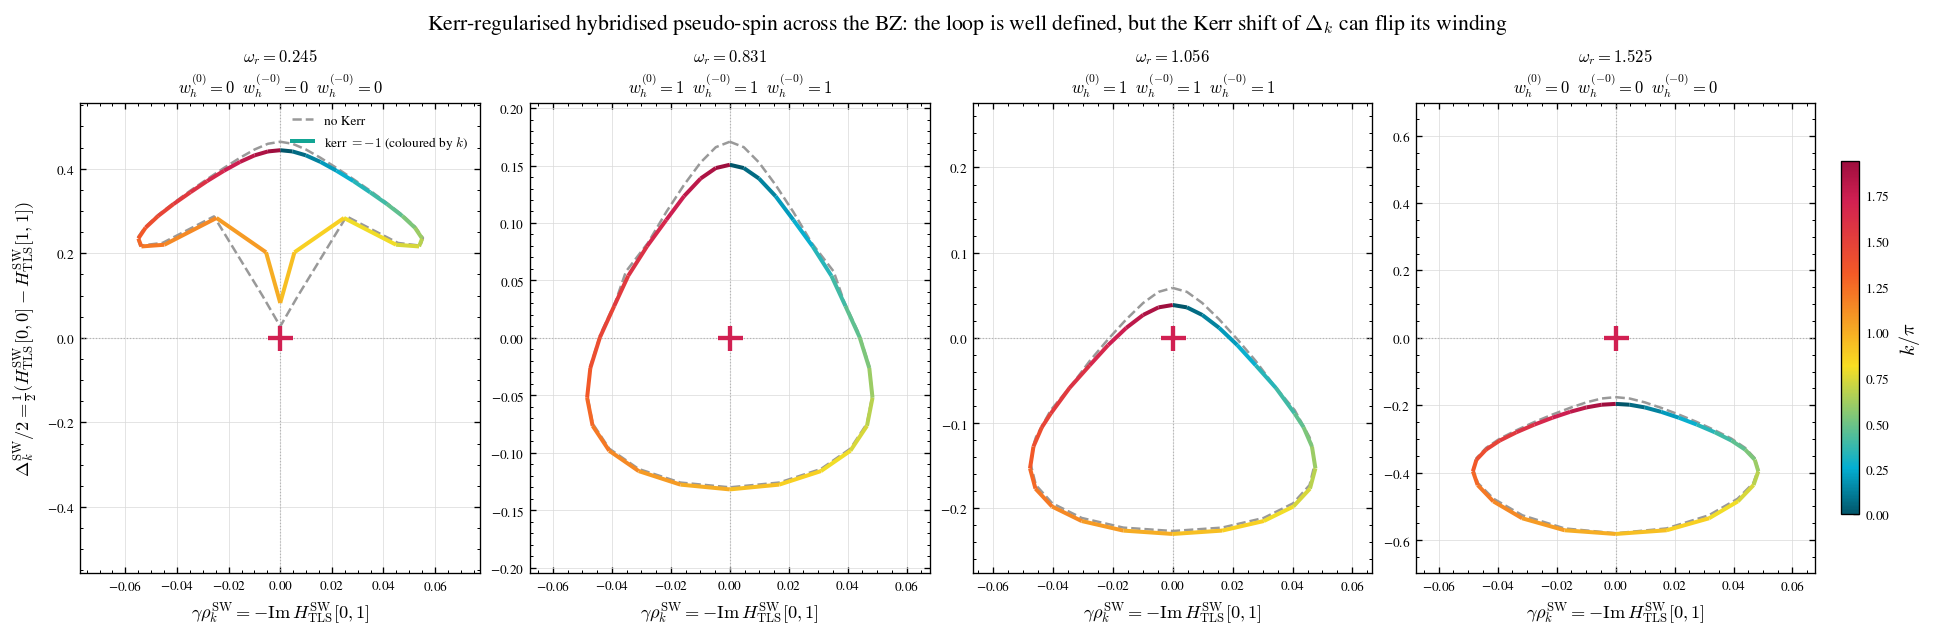

In [75]:
# --- Kerr-corrected hybridised pseudo-spin loop  (plot) -------------------
from matplotlib.collections import LineCollection

omega_r_list = list(kerr_spinor_scan)
num_panels   = len(omega_r_list)
fig, axs = plt.subplots(1, num_panels, figsize=(4.0 * num_panels, 5.2), constrained_layout=True)
kerr_line_style = {0.0: dict(color="0.6", lw=1.5, ls="--")}   # -1 drawn as a k-coloured LineCollection

for ax, omega_r_value in zip(np.atleast_1d(axs), omega_r_list):
    records = kerr_spinor_scan[omega_r_value]
    for kerr in (0.0, -0.05):                            # -2 (overshoot) stays in the table only
        record = records[kerr]
        spin_x = np.r_[record["spin_x"], record["spin_x"][:1]]
        spin_z = np.r_[record["spin_z"], record["spin_z"][:1]]
        if kerr == -0.05:                                   # colour the reference Kerr loop by k
            points = np.column_stack([spin_x, spin_z]).reshape(-1, 1, 2)
            loop = LineCollection(np.concatenate([points[:-1], points[1:]], axis=1),
                                  cmap="thesis_cmap", linewidth=2.4, zorder=4)
            loop.set_array(np.r_[loop_momenta_kerr, 2 * np.pi][:-1] / np.pi)
            ax.add_collection(loop)
        else:
            ax.plot(spin_x, spin_z, zorder=3, label="no Kerr", **kerr_line_style[kerr])
    ax.plot([], [], color=ts.COLORS["teal"], lw=2.4, label=r"kerr $=-1$ (coloured by $k$)")

    ax.axhline(0.0, color="0.7", lw=0.7, ls=":")
    ax.axvline(0.0, color="0.7", lw=0.7, ls=":")
    ax.plot(0, 0, "+", color=ts.COLORS["red"], ms=15, mew=2.6, zorder=6)

    all_x = np.concatenate([records[kerr]["spin_x"] for kerr in (0.0, -0.05)])
    all_z = np.concatenate([records[kerr]["spin_z"] for kerr in (0.0, -0.05)])
    span_x, span_z = np.abs(all_x).max(), np.abs(all_z).max()
    ax.set_xlim(-1.4 * span_x, 1.4 * span_x)
    ax.set_ylim(-1.2 * max(span_z, span_x), 1.2 * max(span_z, span_x))

    windings = "  ".join(rf"$w_h^{{({kerr:.0f})}}={records[kerr]['w_h']}$" for kerr in kerr_spinor_values)
    ax.set_title(rf"$\omega_r = {omega_r_value:.3f}$" "\n" + windings, fontsize=10)
    ax.set_xlabel(r"$\gamma\rho_k^{\rm SW} = -\mathrm{Im}\,H_{\rm TLS}^{\rm SW}[0,1]$", fontsize=11)

first_ax = np.atleast_1d(axs)[0]
first_ax.set_ylabel(r"$\Delta_k^{\rm SW}/2 = \frac{1}{2}(H_{\rm TLS}^{\rm SW}[0,0] - H_{\rm TLS}^{\rm SW}[1,1])$",
                    fontsize=11)
first_ax.legend(loc="upper right", fontsize=8)
colorbar = fig.colorbar(loop, ax=axs, shrink=0.75, pad=0.015)
colorbar.set_label(r"$k / \pi$", fontsize=12)
fig.suptitle(r"Kerr-regularised hybridised pseudo-spin across the BZ: the loop is well defined, "
             r"but the Kerr shift of $\Delta_k$ can flip its winding", fontsize=13)
ts.finalize(axs)
plt.show()